Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

# Project directory configuration
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
IMAGES_DIR = PROJECT_ROOT / "images"
REPORTS_DIR = PROJECT_ROOT / "reports"

# Ensure output directories exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)
print("Images:", IMAGES_DIR)

Project root: c:\Users\HP\Desktop\ecommerce-business-performance-analysis
Processed data: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\data\processed
Images: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\images


Load the dataset

In [3]:
file_path = "../data/online_retail_II.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Year 2009-2010', 'Year 2010-2011']


Load the data

In [4]:
df = pd.read_excel(
    file_path,
    sheet_name=excel_file.sheet_names[0]
)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Understand the dataset

In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (525461, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Co

Check data quality

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nBasic statistics:")
display(df.describe(include="all"))

Missing values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Duplicate rows:
6865

Basic statistics:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,525461.0,525461,522533,525461.000000,525461,525461.000000,417534.000000,525461
unique,28816.0,4632,4681,NaN,NaN,NaN,NaN,40
top,537434.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,675.0,3516,3549,NaN,NaN,NaN,NaN,485852
mean,NaN,NaN,NaN,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478,NaN
min,NaN,NaN,NaN,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2010-03-21 12:20:00,1.250000,13983.000000,NaN
50%,NaN,NaN,NaN,3.000000,2010-07-06 09:51:00,2.100000,15311.000000,NaN
75%,NaN,NaN,NaN,10.000000,2010-10-15 12:45:00,4.210000,16799.000000,NaN
max,NaN,NaN,NaN,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000,NaN


## 2. Dataset Structure and Time Period

The dataset contains two Excel worksheets.
I will inspect both sheets to understand their
time coverage and transaction structure before
combining them for further analysis.

In [7]:
print("Available worksheets:")
print(excel_file.sheet_names)

for sheet in excel_file.sheet_names:

    temp_df = pd.read_excel(
        file_path,
        sheet_name=sheet
    )

    print("\nWorksheet:", sheet)
    print("Shape:", temp_df.shape)

    print("Date range:")
    print(temp_df["InvoiceDate"].min())
    print(temp_df["InvoiceDate"].max())

Available worksheets:
['Year 2009-2010', 'Year 2010-2011']

Worksheet: Year 2009-2010
Shape: (525461, 8)
Date range:
2009-12-01 07:45:00
2010-12-09 20:01:00

Worksheet: Year 2010-2011
Shape: (541910, 8)
Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


Investigate negative quantities

In [8]:
negative_quantity = df[df["Quantity"] < 0]

print("Negative quantity records:",
      len(negative_quantity))

display(negative_quantity.head(10))

Negative quantity records: 12326


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


Investigate negative prices

In [9]:
negative_price = df[df["Price"] < 0]

print("Negative price records:",
      len(negative_price))

display(negative_price.head(10))

Negative price records: 3


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


Investigate cancelled invoices

In [10]:
cancelled = df[
    df["Invoice"].astype(str).str.startswith("C")
]

print("Cancelled invoice records:", len(cancelled))

display(cancelled.head(10))

Cancelled invoice records: 10206


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


Examine duplicate transactions

In [11]:
duplicates = df[df.duplicated(keep=False)]

print("Total records involved in duplicates:",
      len(duplicates))

display(duplicates.head(20))

Total records involved in duplicates: 13283


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


## 3. Combining Both Worksheets

The dataset contains two worksheets representing
different reporting periods.

I will combine both worksheets into one DataFrame
to perform analysis across the complete dataset.

In [12]:
# Load both worksheets

df_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

# Combine both datasets

df_all = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

print("Combined dataset shape:", df_all.shape)

display(df_all.head())

Combined dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Repeat the data-quality checks

In [13]:
# Missing values

print("Missing values:")
print(df_all.isnull().sum())

# Duplicate records

print("\nDuplicate rows:")
print(df_all.duplicated().sum())

# Negative quantities

print("\nNegative quantities:")
print((df_all["Quantity"] < 0).sum())

# Negative prices

print("\nNegative prices:")
print((df_all["Price"] < 0).sum())

# Cancelled invoices

cancelled_all = df_all[
    df_all["Invoice"].astype(str).str.startswith("C")
]

print("\nCancelled invoice records:")
print(len(cancelled_all))

Missing values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate rows:
34335

Negative quantities:
22950

Negative prices:
5

Cancelled invoice records:
19494


One additional investigation

In [14]:
missing_customer_percentage = (
    df_all["Customer ID"].isnull().mean() * 100
)

print(
    f"Missing Customer IDs: "
    f"{missing_customer_percentage:.2f}%"
)

Missing Customer IDs: 22.77%


## 4. Detailed Data Quality Investigation

This section investigates transaction types,
duplicate records, negative quantities and
unusual price values before data cleaning.

Are all negative quantities cancellations?

In [15]:
# Negative quantities without a cancellation prefix

negative_without_cancel = df_all[
    (df_all["Quantity"] < 0) &
    (~df_all["Invoice"].astype(str).str.startswith("C"))
]

print("Negative quantities without C prefix:",
      len(negative_without_cancel))

display(negative_without_cancel.head(15))

Negative quantities without C prefix: 3457


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


Are there cancelled invoices with positive quantities?

In [16]:
cancelled_positive = df_all[
    (df_all["Invoice"].astype(str).str.startswith("C")) &
    (df_all["Quantity"] > 0)
]

print("Cancelled invoices with positive quantity:",
      len(cancelled_positive))

display(cancelled_positive.head(10))

Cancelled invoices with positive quantity: 1


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


Inspect all negative prices

In [17]:
negative_price_all = df_all[
    df_all["Price"] < 0
]

display(negative_price_all)

print("Total negative price records:",
      len(negative_price_all))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Total negative price records: 5


Investigation 4: Understand duplicate groups

In [18]:
duplicate_records = df_all[
    df_all.duplicated(keep=False)
]

print("Records involved in duplicate groups:",
      len(duplicate_records))

print("Unique invoices among duplicates:",
      duplicate_records["Invoice"].nunique())

display(duplicate_records.head(20))

Records involved in duplicate groups: 67242
Unique invoices among duplicates: 5391


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


## 5. Investigation of Unusual Transactions

This section examines negative quantity records,
stock adjustments, bad-debt adjustments and
duplicate transaction patterns.

Investigation 1 – Understand negative quantity records

In [19]:
# Examine descriptions of negative quantity records

negative_without_cancel["Description"].value_counts(
    dropna=False
).head(20)

Description
NaN                       2689
check                      123
damages                     84
?                           83
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
??                           7
damages?                     7
crushed                      6
given away                   6
Damages                      5
wet damaged                  5
ebay                         5
counted                      5
Name: count, dtype: int64

Investigation 2 – Check whether they have zero prices

In [20]:
print("Negative quantity records:")
print(len(negative_without_cancel))

print("\nZero-price records:")
print(
    (negative_without_cancel["Price"] == 0).sum()
)

print("\nRecords with missing Customer IDs:")
print(
    negative_without_cancel["Customer ID"].isnull().sum()
)

Negative quantity records:
3457

Zero-price records:
3457

Records with missing Customer IDs:
3457


Investigation 3 – Examine the cancelled invoice records

In [21]:
cancelled_all["Quantity"].describe()

count    19494.000000
mean       -25.186827
std        805.104908
min     -80995.000000
25%         -6.000000
50%         -2.000000
75%         -1.000000
max          1.000000
Name: Quantity, dtype: float64

In [22]:
print(
    "Cancelled invoices with positive quantities:",
    len(cancelled_positive)
)

Cancelled invoices with positive quantities: 1


Investigation 4 – Understand duplicate patterns

In [23]:
duplicate_summary = (
    duplicate_records
    .groupby(
        ["Invoice", "StockCode", "Quantity", "Price"]
    )
    .size()
    .reset_index(name="Occurrences")
)

display(
    duplicate_summary
    .sort_values("Occurrences", ascending=False)
    .head(20)
)

,Invoice,StockCode,Quantity,Price,Occurrences
29289,555524,22698,1,2.95,20
29288,555524,22697,1,2.95,12
15843,537224,70007,1,1.65,10
30878,572861,22775,12,1.25,8
14728,537154,22727,1,3.75,6
28023,538514,21756,1,5.95,6
17512,537265,79000,12,0.85,6
15438,537208,90082B,1,6.35,6
4055,525065,20894,1,2.95,6
23543,537781,22898,1,1.95,6


In [24]:
invoice_555524 = df_all[
    df_all["Invoice"].astype(str) == "555524"
]

display(invoice_555524)

print("Number of rows:", len(invoice_555524))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
738628,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
738629,555524,84978,HANGING HEART JAR T-LIGHT HOLDER,6,2011-06-05 11:37:00,1.25,16923.0,United Kingdom
738630,555524,23174,REGENCY SUGAR BOWL GREEN,2,2011-06-05 11:37:00,4.15,16923.0,United Kingdom
738631,555524,23169,CLASSIC GLASS COOKIE JAR,1,2011-06-05 11:37:00,4.15,16923.0,United Kingdom
738632,555524,23300,GARDENERS KNEELING PAD CUP OF TEA,4,2011-06-05 11:37:00,1.65,16923.0,United Kingdom
...,...,...,...,...,...,...,...,...
738699,555524,22896,PEG BAG APPLES DESIGN,2,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
738700,555524,21155,RED RETROSPOT PEG BAG,1,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
738701,555524,22896,PEG BAG APPLES DESIGN,1,2011-06-05 11:37:00,2.55,16923.0,United Kingdom
738702,555524,22899,CHILDREN'S APRON DOLLY GIRL,2,2011-06-05 11:37:00,2.10,16923.0,United Kingdom


Number of rows: 76


3. Investigate the one unusual cancelled invoice

In [25]:
display(cancelled_positive)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


In [26]:
positive_cancel_invoice = cancelled_positive.iloc[0]["Invoice"]

display(
    df_all[
        df_all["Invoice"] == positive_cancel_invoice
    ]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


Cell 1 – Count exact duplicate occurrences

In [27]:
print("Exact duplicate occurrences:",
      df_all.duplicated().sum())

print("All rows belonging to duplicate groups:",
      df_all.duplicated(keep=False).sum())

Exact duplicate occurrences: 34335
All rows belonging to duplicate groups: 67242


Cell 2 – Identify unique duplicated records

In [28]:
exact_duplicate_groups = (
    df_all[df_all.duplicated(keep=False)]
    .drop_duplicates()
)

print(
    "Unique records belonging to duplicate groups:",
    len(exact_duplicate_groups)
)

display(exact_duplicate_groups.head(20))

Unique records belonging to duplicate groups: 32907


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
388,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,2009-12-01 11:34:00,2.55,16329.0,United Kingdom
628,489529,48129,DOOR MAT TOPIARY,1,2009-12-01 11:51:00,6.75,17984.0,United Kingdom
634,489529,22028,PENNY FARTHING BIRTHDAY CARD,12,2009-12-01 11:51:00,0.42,17984.0,United Kingdom
656,489529,22036,DINOSAUR BIRTHDAY CARD,12,2009-12-01 11:51:00,0.42,17984.0,United Kingdom


Cell 3 – Understand how often they occur

In [29]:
duplicate_frequency = (
    df_all.value_counts(
        subset=df_all.columns.tolist(),
        dropna=False
    )
    .reset_index(name="Occurrences")
)

duplicate_frequency = duplicate_frequency[
    duplicate_frequency["Occurrences"] > 1
]

display(
    duplicate_frequency
    .sort_values("Occurrences", ascending=False)
    .head(20)
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Occurrences
0,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,20
1,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,12
2,537224,70007,HI TEC ALPINE HAND WARMER,1,2010-12-05 16:24:00,1.65,13174.0,United Kingdom,10
3,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.0,United Kingdom,8
4,536796,21967,PACK OF 12 SKULL TISSUES,1,2010-12-02 15:46:00,0.29,15574.0,United Kingdom,6
5,572344,M,Manual,48,2011-10-24 10:43:00,1.50,14607.0,United Kingdom,6
6,536874,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-03 11:35:00,2.10,16891.0,United Kingdom,6
7,537781,22745,POPPY'S PLAYHOUSE BEDROOM,1,2010-12-08 12:46:00,2.10,17341.0,United Kingdom,6
8,537224,22086,PAPER CHAIN KIT 50'S CHRISTMAS,1,2010-12-05 16:24:00,2.95,13174.0,United Kingdom,6
9,578289,23395,BELLE JARDINIERE CUSHION COVER,1,2011-11-23 14:07:00,3.75,17841.0,United Kingdom,6


4. Your next task: inspect the repeated records

In [30]:
# Inspect the 20 repeated records in invoice 555524
duplicate_example = df_all[
    (df_all["Invoice"].astype(str) == "555524") &
    (df_all["StockCode"].astype(str) == "22698")
]

display(duplicate_example)

print("Number of matching rows:", len(duplicate_example))
print("Number of unique rows:", len(duplicate_example.drop_duplicates()))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
738637,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738638,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738644,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738652,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738653,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738655,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738656,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738657,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738658,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom
738659,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom


Number of matching rows: 20
Number of unique rows: 1


In [31]:
duplicate_frequency["Extra_Copies"] = (
    duplicate_frequency["Occurrences"] - 1
)

print(
    "Number of exact-duplicate groups:",
    len(duplicate_frequency)
)

print(
    "Total extra copies:",
    duplicate_frequency["Extra_Copies"].sum()
)

Number of exact-duplicate groups: 32907
Total extra copies: 34335


1. Create a duplicate-free working dataset

In [32]:
# Create a new dataset without exact duplicate rows
df_dedup = df_all.drop_duplicates().copy()

# Compare original and new dataset
print("Original shape:", df_all.shape)
print("After removing duplicates:", df_dedup.shape)

print("Rows removed:", len(df_all) - len(df_dedup))
print("Remaining exact duplicates:", df_dedup.duplicated().sum())

Original shape: (1067371, 8)
After removing duplicates: (1033036, 8)
Rows removed: 34335
Remaining exact duplicates: 0


3. Next: investigate negative quantities

In [33]:
# Identify transactions with negative quantities
negative_quantity = df_dedup[df_dedup["Quantity"] < 0]

# Compare cancelled and non-cancelled invoices
negative_quantity_summary = (
    negative_quantity
    .assign(
        Is_Cancelled=negative_quantity["Invoice"]
        .astype(str)
        .str.startswith("C")
    )
    .groupby("Is_Cancelled")
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Missing_Customer_ID=("Customer ID", lambda x: x.isna().sum()),
        Zero_Price=("Price", lambda x: (x == 0).sum())
    )
)

display(negative_quantity_summary)

,Records,Total_Quantity,Missing_Customer_ID,Zero_Price
Is_Cancelled,,,,
False,3393,-569314,3393,3393
True,19103,-476820,713,0


2. Investigate the descriptions of these records

In [34]:
# Examine descriptions of non-cancelled negative-quantity records
non_cancelled_negative = df_dedup[
    (df_dedup["Quantity"] < 0) &
    (~df_dedup["Invoice"].astype(str).str.startswith("C"))
]

print("Number of records:", len(non_cancelled_negative))

display(
    non_cancelled_negative["Description"]
    .value_counts(dropna=False)
    .head(25)
)

Number of records: 3393


Description
NaN                       2633
check                      121
damages                     83
?                           81
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
??                           7
damages?                     7
crushed                      6
given away                   6
Damages                      5
wet damaged                  5
ebay                         5
counted                      5
MIA                          5
checked                      5
ebay sales                   4
CHECK                        3
wet pallet                   3
Name: count, dtype: int64

Investigate the cancelled records:

In [35]:
cancelled_negative = df_dedup[
    (df_dedup["Quantity"] < 0) &
    (df_dedup["Invoice"].astype(str).str.startswith("C"))
]

display(
    cancelled_negative["Description"]
    .value_counts(dropna=False)
    .head(25)
)

Description
Manual                                 533
REGENCY CAKESTAND 3 TIER               341
POSTAGE                                228
BAKING SET 9 PIECE RETROSPOT           209
STRAWBERRY CERAMIC TRINKET BOX         181
Discount                               168
WHITE HANGING HEART T-LIGHT HOLDER     134
WHITE CHERRY LIGHTS                    121
RED RETROSPOT CAKE STAND               107
SAMPLES                                 98
JAM MAKING SET WITH JARS                87
PINK CHERRY LIGHTS                      86
WOOD 2 DRAWER CABINET WHITE FINISH      85
SET OF 3 CAKE TINS PANTRY DESIGN        73
SWEETHEART CERAMIC TRINKET BOX          73
JUMBO BAG RED RETROSPOT                 72
CERAMIC CAKE STAND + HANGING CAKES      71
RED RETROSPOT TRADITIONAL TEAPOT        69
SMALL GLASS HEART TRINKET POT           68
BAKING SET SPACEBOY DESIGN              67
SILVER HANGING T-LIGHT HOLDER           66
GUMBALL COAT RACK                       65
LARGE CAKE STAND  HANGING STRAWBERY     64

3. Check whether cancelled records have positive prices

In [36]:
display(
    cancelled_negative[["Quantity", "Price"]].describe()
)

print(
    "Cancelled records with zero price:",
    (cancelled_negative["Price"] == 0).sum()
)

print(
    "Cancelled records with positive price:",
    (cancelled_negative["Price"] > 0).sum()
)

,Quantity,Price
count,19103.000000,19103.000000
mean,-24.960477,42.831924
std,810.430519,574.820831
min,-80995.000000,0.010000
25%,-6.000000,1.450000
50%,-2.000000,2.950000
75%,-1.000000,6.650000
max,-1.000000,38970.000000


Cancelled records with zero price: 0
Cancelled records with positive price: 19103


3. One more investigation before cleaning

In [37]:
# Examine prices in cancelled negative-quantity records
display(
    cancelled_negative[["Quantity", "Price"]].describe()
)

print(
    "Zero-price records:",
    (cancelled_negative["Price"] == 0).sum()
)

print(
    "Positive-price records:",
    (cancelled_negative["Price"] > 0).sum()
)

print(
    "Negative-price records:",
    (cancelled_negative["Price"] < 0).sum()
)

,Quantity,Price
count,19103.000000,19103.000000
mean,-24.960477,42.831924
std,810.430519,574.820831
min,-80995.000000,0.010000
25%,-6.000000,1.450000
50%,-2.000000,2.950000
75%,-1.000000,6.650000
max,-1.000000,38970.000000


Zero-price records: 0
Positive-price records: 19103
Negative-price records: 0


2. Investigate unusually high prices

In [38]:
# Calculate transaction value
cancelled_negative = cancelled_negative.copy()

cancelled_negative["TransactionValue"] = (
    cancelled_negative["Quantity"] *
    cancelled_negative["Price"]
)

# Show the 20 records with the highest unit prices
high_price_cancellations = (
    cancelled_negative
    .sort_values("Price", ascending=False)
)

display(
    high_price_cancellations[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "TransactionValue",
         "Customer ID", "Country"]
    ].head(20)
)

,Invoice,StockCode,Description,Quantity,Price,TransactionValue,Customer ID,Country
748142,C556445,M,Manual,-1,38970.00,-38970.00,15098.0,United Kingdom
241824,C512770,M,Manual,-1,25111.09,-25111.09,17399.0,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,18910.69,-18910.69,NaN,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46,-17836.46,NaN,United Kingdom
569163,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,-16888.02,NaN,United Kingdom
569164,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,-16453.71,NaN,United Kingdom
519294,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,NaN,United Kingdom
517953,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,NaN,United Kingdom
519170,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,-13474.79,NaN,United Kingdom
1050062,C580604,AMAZONFEE,AMAZON FEE,-1,11586.50,-11586.50,NaN,United Kingdom


3. Next: identify all non-product transaction types

In [39]:
# Group negative-quantity transactions by stock code and description
negative_transaction_types = (
    cancelled_negative
    .groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum"),
        Average_Price=("Price", "mean")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(negative_transaction_types.head(30))

,StockCode,Description,Records,Total_Quantity,Total_Value,Average_Price
3082,M,Manual,533,-5444,-422926.14,779.440263
1269,22423,REGENCY CAKESTAND 3 TIER,341,-1450,-16545.30,12.053226
3084,POST,POSTAGE,228,-302,-15252.01,61.319123
991,22138,BAKING SET 9 PIECE RETROSPOT,209,-859,-4052.95,4.879426
353,21232,STRAWBERRY CERAMIC TRINKET BOX,181,-782,-922.59,1.219558
3080,D,Discount,168,-3064,-13277.52,71.938750
2929,85123A,WHITE HANGING HEART T-LIGHT HOLDER,134,-3637,-9387.10,2.779478
2705,79323W,WHITE CHERRY LIGHTS,121,-1072,-6331.30,6.310331
780,21843,RED RETROSPOT CAKE STAND,107,-494,-4273.90,10.707477
3085,S,SAMPLES,98,-98,-6127.96,62.530204


Then check how many records have non-numeric stock codes:

In [40]:
# Identify stock codes that are not purely numeric
non_numeric_stock = cancelled_negative[
    ~cancelled_negative["StockCode"]
    .astype(str)
    .str.fullmatch(r"\d+")
]

print("Non-numeric stock code records:", len(non_numeric_stock))

display(
    non_numeric_stock["StockCode"]
    .value_counts()
)

Non-numeric stock code records: 3383


StockCode
M         533
POST      228
D         168
85123A    134
79323W    126
         ... 
90202B      1
90202C      1
90202D      1
90082D      1
90200D      1
Name: count, Length: 537, dtype: int64

3. Next investigation: identify special transaction codes

In [41]:
# Known special transaction codes identified during investigation
special_codes = [
    "M",
    "POST",
    "D",
    "S",
    "BANK CHARGES",
    "AMAZONFEE"
]

special_transactions = cancelled_negative[
    cancelled_negative["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(special_codes)
]

special_summary = (
    special_transactions
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(special_summary)

,StockCode,Description,Records,Total_Quantity,Total_Value
4,M,Manual,533,-5444,-422926.14
5,POST,POSTAGE,228,-302,-15252.01
3,D,Discount,168,-3064,-13277.52
6,S,SAMPLES,98,-98,-6127.96
2,BANK CHARGES,Bank Charges,62,-72,-33902.53
0,AMAZONFEE,AMAZON FEE,33,-33,-241988.30
1,BANK CHARGES,Bank Charges,4,-4,-2098.96


Now let's inspect the remaining stock codes to see whether there are other special entries:

In [42]:
# Show stock codes and descriptions, excluding known special codes
other_transactions = cancelled_negative[
    ~cancelled_negative["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(special_codes)
]

other_summary = (
    other_transactions
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "count"),
        Total_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(other_summary.head(30))

,StockCode,Description,Records,Total_Value
1269,22423,REGENCY CAKESTAND 3 TIER,341,-16545.30
991,22138,BAKING SET 9 PIECE RETROSPOT,209,-4052.95
353,21232,STRAWBERRY CERAMIC TRINKET BOX,181,-922.59
2929,85123A,WHITE HANGING HEART T-LIGHT HOLDER,134,-9387.10
2705,79323W,WHITE CHERRY LIGHTS,121,-6331.30
780,21843,RED RETROSPOT CAKE STAND,107,-4273.90
1724,22960,JAM MAKING SET WITH JARS,87,-1012.79
2701,79323P,PINK CHERRY LIGHTS,86,-4021.35
2270,82483,WOOD 2 DRAWER CABINET WHITE FINISH,85,-1683.85
352,21231,SWEETHEART CERAMIC TRINKET BOX,73,-388.93


Code 1 — Examine special stock codes across all transactions

In [43]:
special_codes = [
    "M",
    "POST",
    "D",
    "S",
    "BANK CHARGES",
    "AMAZONFEE"
]

special_all = df_dedup[
    df_dedup["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(special_codes)
].copy()

special_all["TransactionValue"] = (
    special_all["Quantity"] * special_all["Price"]
)

special_all_summary = (
    special_all
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(special_all_summary)

,StockCode,Description,Records,Total_Quantity,Total_Value
5,POST,POSTAGE,2079,5061,110430.410
4,M,Manual,1387,4193,-83326.330
3,D,Discount,173,-2868,-12879.630
7,S,SAMPLES,101,-95,-5991.110
2,BANK CHARGES,Bank Charges,94,-40,-33413.289
0,AMAZONFEE,AMAZON FEE,36,-30,-221520.500
6,POST,NaN,7,4950,0.000
1,BANK CHARGES,Bank Charges,6,-2,-2068.960
8,m,Manual,5,5,15.050


Code 2 — Inspect other unusual descriptions

In [44]:
# Inspect descriptions containing operational or financial terms
keywords = [
    "MANUAL",
    "POSTAGE",
    "DISCOUNT",
    "SAMPLE",
    "BANK",
    "FEE",
    "CHARGE",
    "ADJUST",
    "CARRIAGE"
]

description_text = (
    df_dedup["Description"]
    .fillna("")
    .astype(str)
    .str.upper()
)

unusual_description = df_dedup[
    description_text.str.contains(
        "|".join(keywords),
        regex=True
    )
].copy()

unusual_summary = (
    unusual_description
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("Price", lambda x: 0) 
    )
    .reset_index()
)

display(unusual_summary.head(40))

,StockCode,Description,Records,Total_Quantity,Total_Value
0,20665,adjustment,1,-15,0
1,20748,KENSINGTON COFFEE SET,183,1600,0
2,20847,ZINC HEART LATTICE CHARGER LARGE,28,79,0
3,20848,ZINC HEART LATTICE CHARGER SMALL,12,39,0
4,20967,Amazon Adjustment,1,1,0
5,21033,taig adjust no stock,1,-24,0
6,21181,adjustment,2,190,0
7,21216,"SET 3 RED SPOT TIN TEA,COFFEE,SUGAR",311,1495,0
8,21216,"SET 3 RETROSPOT TEA,COFFEE,SUGAR",515,2366,0
9,21319,adjustment,1,3,0


Code 1 — Standardise special stock codes

In [45]:
df_dedup["StockCode_norm"] = (
    df_dedup["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df_dedup["Description_norm"] = (
    df_dedup["Description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

special_codes = [
    "M", "POST", "D", "S",
    "BANK CHARGES", "AMAZONFEE"
]

special_all = df_dedup[
    df_dedup["StockCode_norm"].isin(special_codes)
].copy()

special_all["TransactionValue"] = (
    special_all["Quantity"] * special_all["Price"]
)

special_summary = (
    special_all
    .groupby(
        ["StockCode_norm", "Description_norm"],
        dropna=False
    )
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(special_summary)

,StockCode_norm,Description_norm,Records,Total_Quantity,Total_Value
5,POST,POSTAGE,2079,5061,110430.410
3,M,MANUAL,1392,4198,-83311.280
2,D,DISCOUNT,173,-2868,-12879.630
6,S,SAMPLES,101,-95,-5991.110
1,BANK CHARGES,BANK CHARGES,100,-42,-35482.249
0,AMAZONFEE,AMAZON FEE,36,-30,-221520.500
4,POST,,7,4950,0.000


Code 2 — Correct the unusual-description analysis

In [46]:
keywords = [
    "MANUAL", "POSTAGE", "DISCOUNT", "SAMPLE",
    "BANK", "FEE", "CHARGE", "ADJUST",
    "CARRIAGE", "REVERSE"
]

description_text = df_dedup["Description_norm"]

unusual_description = df_dedup[
    description_text.str.contains(
        "|".join(keywords),
        regex=True
    )
].copy()

unusual_description["TransactionValue"] = (
    unusual_description["Quantity"]
    * unusual_description["Price"]
)

unusual_summary = (
    unusual_description
    .groupby(
        ["StockCode_norm", "Description_norm"],
        dropna=False
    )
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(unusual_summary.head(50))

,StockCode_norm,Description_norm,Records,Total_Quantity,Total_Value
107,POST,POSTAGE,2079,5061,110430.410
105,DOT,DOTCOM POSTAGE,1423,1417,309844.100
106,M,MANUAL,1392,4198,-83311.280
43,22646,CERAMIC STRAWBERRY CAKE MONEY BANK,928,8809,12499.710
42,22645,CERAMIC HEART FAIRY CAKE MONEY BANK,759,5354,9639.580
31,22301,COFFEE MUG CAT + BIRD DESIGN,674,4936,11932.780
40,22644,CERAMIC CHERRY CAKE MONEY BANK,634,4751,6815.430
39,22637,PIGGY BANK RETROSPOT,630,4411,11320.920
33,22303,COFFEE MUG APPLES DESIGN,568,5300,12365.180
30,22300,COFFEE MUG DOG + BALL DESIGN,551,4054,9730.750


2. Let's create transaction categories

In [47]:
df_analysis = df_dedup.copy()

# Standardise values for classification
df_analysis["StockCode_norm"] = (
    df_analysis["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df_analysis["Description_norm"] = (
    df_analysis["Description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

# Calculate transaction value
df_analysis["TransactionValue"] = (
    df_analysis["Quantity"] * df_analysis["Price"]
)

# Start by treating all records as products
df_analysis["Transaction_Category"] = "Product"

# Financial and operational adjustments
financial_codes = [
    "M", "D", "BANK CHARGES", "AMAZONFEE", "ADJUST"
]

df_analysis.loc[
    df_analysis["StockCode_norm"].isin(financial_codes),
    "Transaction_Category"
] = "Financial / Operational Adjustment"

# Delivery-related transactions
delivery_codes = ["POST", "DOT", "C2"]

df_analysis.loc[
    df_analysis["StockCode_norm"].isin(delivery_codes),
    "Transaction_Category"
] = "Delivery"

# Identify next-day carriage using its exact description
df_analysis.loc[
    df_analysis["Description_norm"] == "NEXT DAY CARRIAGE",
    "Transaction_Category"
] = "Delivery"

# Samples
df_analysis.loc[
    (df_analysis["StockCode_norm"] == "S") |
    (df_analysis["Description_norm"] == "SHOW SAMPLES"),
    "Transaction_Category"
] = "Samples"

3. Check the category summary

In [48]:
category_summary = (
    df_analysis
    .groupby("Transaction_Category")
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(category_summary)

,Transaction_Category,Records,Total_Quantity,Total_Value,Unique_Invoices
2,Product,1027298,10394898,1.877329e+07,52220
0,Delivery,3868,13717,4.345955e+05,3862
1,Financial / Operational Adjustment,1768,1263,-3.463584e+05,1635
3,Samples,102,-99,-5.991110e+03,38


4. Check genuine product returns

In [49]:
product_returns = df_analysis[
    (df_analysis["Transaction_Category"] == "Product") &
    (df_analysis["Quantity"] < 0)
].copy()

print("Product return records:", len(product_returns))

display(
    product_returns[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue",
            "Country"
        ]
    ].head(20)
)

Product return records: 21327


,Invoice,StockCode,Description,Quantity,Price,TransactionValue,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,-35.40,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,-9.90,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,-17.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2.10,-12.60,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,-35.40,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,1.25,-15.00,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,1.25,-15.00,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,0.85,-20.40,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2.95,-35.40,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,4.25,-12.75,United Kingdom


In [50]:
# Select negative-quantity records currently classified as products
negative_products = df_analysis[
    (df_analysis["Transaction_Category"] == "Product") &
    (df_analysis["Quantity"] < 0)
].copy()

# Add investigation flags
negative_products["Is_Cancelled_Invoice"] = (
    negative_products["Invoice"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
)

negative_products["Is_Zero_Price"] = (
    negative_products["Price"] == 0
)

negative_products["Has_Missing_Customer_ID"] = (
    negative_products["Customer ID"].isna()
)

# Summarise the different types
return_investigation = (
    negative_products
    .groupby(
        [
            "Is_Cancelled_Invoice",
            "Is_Zero_Price",
            "Has_Missing_Customer_ID"
        ]
    )
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(return_investigation)

,Is_Cancelled_Invoice,Is_Zero_Price,Has_Missing_Customer_ID,Records,Total_Quantity,Total_Value
1,True,False,False,17606,-464313,-717930.96
0,False,True,True,3392,-569310,0.00
2,True,False,True,329,-3448,-6542.10


Then inspect the non-cancelled negative product records:

In [51]:
non_cancelled_negative = negative_products[
    ~negative_products["Is_Cancelled_Invoice"]
]

display(
    non_cancelled_negative[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Customer ID",
            "Country"
        ]
    ].head(30)
)

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,0.0,NaN,United Kingdom
283,489463,71477,short,-240,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,0.0,NaN,United Kingdom


2. Create a separate inventory-adjustment category

In [52]:
# Identify non-cancelled negative quantities with zero price
# and missing customer IDs

inventory_adjustment_mask = (
    (df_analysis["Transaction_Category"] == "Product") &
    (df_analysis["Quantity"] < 0) &
    (~df_analysis["Invoice"].astype(str).str.startswith("C")) &
    (df_analysis["Price"] == 0) &
    (df_analysis["Customer ID"].isna())
)

# Assign a separate category
df_analysis.loc[
    inventory_adjustment_mask,
    "Transaction_Category"
] = "Inventory / Damage Adjustment"

print(
    "Inventory adjustment records:",
    inventory_adjustment_mask.sum()
)

Inventory adjustment records: 3392


3. Recalculate the category summary

In [53]:
category_summary = (
    df_analysis
    .groupby("Transaction_Category")
    .agg(
        Records=("Invoice", "count"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

display(category_summary)

,Transaction_Category,Records,Total_Quantity,Total_Value,Unique_Invoices
3,Product,1023906,10964208,1.877329e+07,48828
0,Delivery,3868,13717,4.345955e+05,3862
2,Inventory / Damage Adjustment,3392,-569310,0.000000e+00,3392
1,Financial / Operational Adjustment,1768,1263,-3.463584e+05,1635
4,Samples,102,-99,-5.991110e+03,38


4. Check the 329 cancellation records separately

In [54]:
cancelled_missing_customer = df_analysis[
    (df_analysis["Transaction_Category"] == "Product") &
    (df_analysis["Quantity"] < 0) &
    (df_analysis["Invoice"].astype(str).str.startswith("C")) &
    (df_analysis["Customer ID"].isna())
]

print("Records:", len(cancelled_missing_customer))

display(
    cancelled_missing_customer[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue"
        ]
    ].head(20)
)

Records: 329


,Invoice,StockCode,Description,Quantity,Price,TransactionValue
5898,C489860,90029,NEW BAROQUE SMALL NECKLACE BLACK,-1,8.50,-8.50
6376,C489881,21102,"CANDLE IN JAR COLLAGE , VANILLA",-31,2.55,-79.05
6377,C489881,72802A,ROSE SCENT CANDLE IN JEWELLED BOX,-16,4.25,-68.00
29415,C491846,84670,JAPANESE CROCHETED ANIMAL,-36,0.42,-15.12
38345,C492577,22276,WASH BAG VINTAGE ROSE PAISLEY,-2,2.55,-5.10
40026,C492756,22278,OVERNIGHT BAG VINTAGE ROSE PAISLEY,-1,12.95,-12.95
42634,C493068,84816,DANISH ROSE BEDSIDE CABINET,-1,21.00,-21.00
43497,C493084,21913,VINTAGE SEASIDE JIGSAW PUZZLES,-1,3.75,-3.75
43498,C493084,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-2,2.55,-5.10
43499,C493084,22130,PARTY CONE CHRISTMAS DECORATION,-6,0.85,-5.10


In [55]:
# Keep only merchandise transactions
product_df = df_analysis[
    df_analysis["Transaction_Category"] == "Product"
].copy()

# Separate sales and returns using quantity
product_sales = product_df[
    product_df["Quantity"] > 0
]

product_returns = product_df[
    product_df["Quantity"] < 0
]

# Calculate sales and return metrics
gross_sales_value = product_sales["TransactionValue"].sum()

return_value = abs(
    product_returns["TransactionValue"].sum()
)

net_sales_value = (
    gross_sales_value - return_value
)

gross_units_sold = product_sales["Quantity"].sum()

returned_units = abs(
    product_returns["Quantity"].sum()
)

net_units_sold = (
    gross_units_sold - returned_units
)

# Display results
sales_performance = pd.DataFrame({
    "Metric": [
        "Gross Sales Value",
        "Returns Value",
        "Net Sales Value",
        "Gross Units Sold",
        "Returned Units",
        "Net Units Sold",
        "Sales Transactions",
        "Return Transactions"
    ],
    "Value": [
        gross_sales_value,
        return_value,
        net_sales_value,
        gross_units_sold,
        returned_units,
        net_units_sold,
        len(product_sales),
        len(product_returns)
    ]
})

display(sales_performance)

,Metric,Value
0,Gross Sales Value,1.949776e+07
1,Returns Value,7.244731e+05
2,Net Sales Value,1.877329e+07
3,Gross Units Sold,1.143197e+07
4,Returned Units,4.677610e+05
5,Net Units Sold,1.096421e+07
6,Sales Transactions,1.005971e+06
7,Return Transactions,1.793500e+04


2. Calculate the return rate

In [56]:
return_value_rate = (
    return_value / gross_sales_value
) * 100

return_unit_rate = (
    returned_units / gross_units_sold
) * 100

print(f"Sales Value Return Rate: {return_value_rate:.2f}%")
print(f"Unit Return Rate: {return_unit_rate:.2f}%")

Sales Value Return Rate: 3.72%
Unit Return Rate: 4.09%


3. Visualise gross sales versus returns

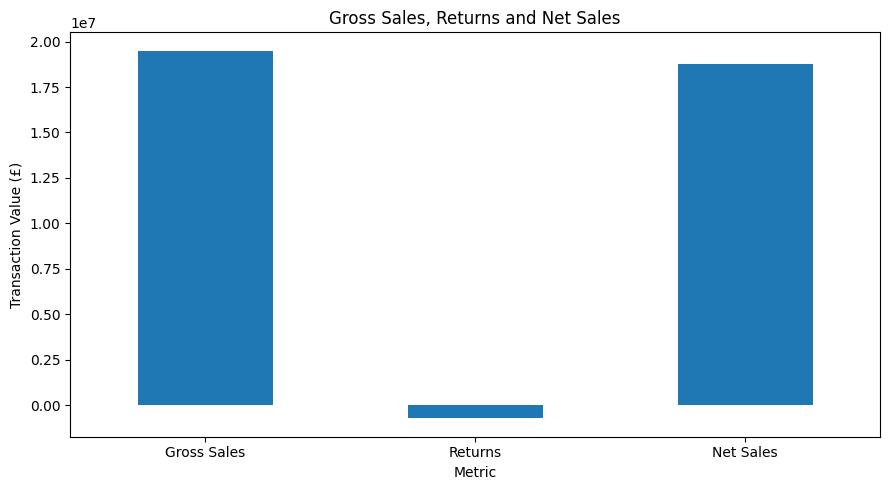

In [57]:
import matplotlib.pyplot as plt

sales_comparison = pd.Series({
    "Gross Sales": gross_sales_value,
    "Returns": -return_value,
    "Net Sales": net_sales_value
})

plt.figure(figsize=(9, 5))

sales_comparison.plot(
    kind="bar",
    title="Gross Sales, Returns and Net Sales"
)

plt.ylabel("Transaction Value (£)")
plt.xlabel("Metric")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

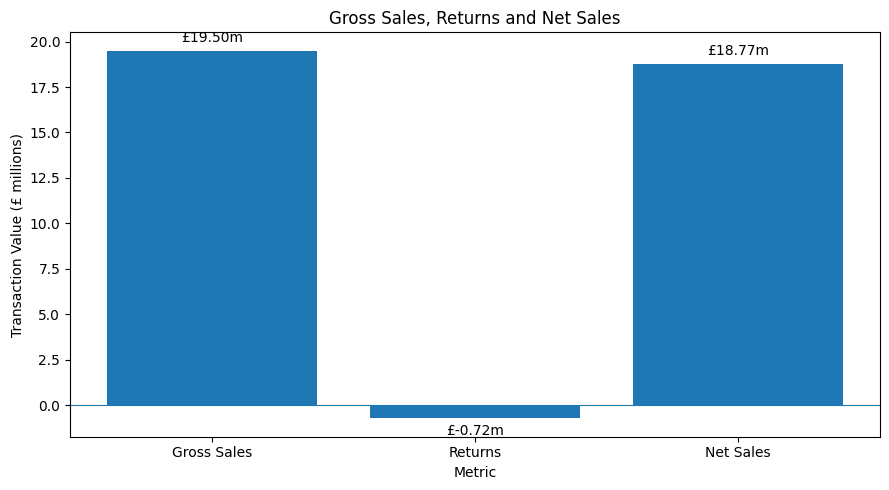

In [58]:
import matplotlib.pyplot as plt

sales_comparison = pd.Series({
    "Gross Sales": gross_sales_value / 1_000_000,
    "Returns": -return_value / 1_000_000,
    "Net Sales": net_sales_value / 1_000_000
})

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    sales_comparison.index,
    sales_comparison.values
)

ax.set_title("Gross Sales, Returns and Net Sales")
ax.set_ylabel("Transaction Value (£ millions)")
ax.set_xlabel("Metric")

ax.bar_label(
    bars,
    labels=[f"£{value:.2f}m" for value in sales_comparison.values],
    padding=4
)

ax.axhline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

Step 1. Prepare monthly sales data

In [59]:
# Work with product transactions only
monthly_df = product_df.copy()

# Create separate columns for sales and returns
monthly_df["Gross_Sales"] = np.where(
    monthly_df["Quantity"] > 0,
    monthly_df["TransactionValue"],
    0
)

monthly_df["Returns_Value"] = np.where(
    monthly_df["Quantity"] < 0,
    -monthly_df["TransactionValue"],
    0
)

monthly_df["Net_Sales"] = (
    monthly_df["Gross_Sales"] - monthly_df["Returns_Value"]
)

# Aggregate by month
monthly_sales = (
    monthly_df
    .groupby(pd.Grouper(key="InvoiceDate", freq="MS"))
    .agg(
        Gross_Sales=("Gross_Sales", "sum"),
        Returns_Value=("Returns_Value", "sum"),
        Net_Sales=("Net_Sales", "sum"),
        Transactions=("Invoice", "count")
    )
    .reset_index()
)

display(monthly_sales.head(10))

,InvoiceDate,Gross_Sales,Returns_Value,Net_Sales,Transactions
0,2009-12-01,798232.030,19558.08,778673.950,44477
1,2010-01-01,612455.502,7535.19,604920.312,30909
2,2010-02-01,537926.696,12575.44,525351.256,28452
3,2010-03-01,761748.531,9603.85,752144.681,40493
4,2010-04-01,592879.702,10025.26,582854.442,33332
5,2010-05-01,643585.640,37192.89,606392.750,34357
6,2010-06-01,697382.320,26373.46,671008.860,39091
7,2010-07-01,589047.630,17132.73,571914.900,32697
8,2010-08-01,674192.890,12397.60,661795.290,32663
9,2010-09-01,869277.161,27686.42,841590.741,41243


Step 2. Find the best and worst months

In [60]:
best_month = monthly_sales.loc[
    monthly_sales["Net_Sales"].idxmax()
]

worst_month = monthly_sales.loc[
    monthly_sales["Net_Sales"].idxmin()
]

print("Best Sales Month:")
print(best_month)

print("\nLowest Sales Month:")
print(worst_month)

Best Sales Month:
InvoiceDate      2011-11-01 00:00:00
Gross_Sales               1451740.98
Returns_Value               28384.77
Net_Sales                 1423356.21
Transactions                   82843
Name: 23, dtype: object

Lowest Sales Month:
InvoiceDate      2011-12-01 00:00:00
Gross_Sales                614349.25
Returns_Value               175191.8
Net_Sales                  439157.45
Transactions                   25115
Name: 24, dtype: object


Step 3. Visualise monthly net sales

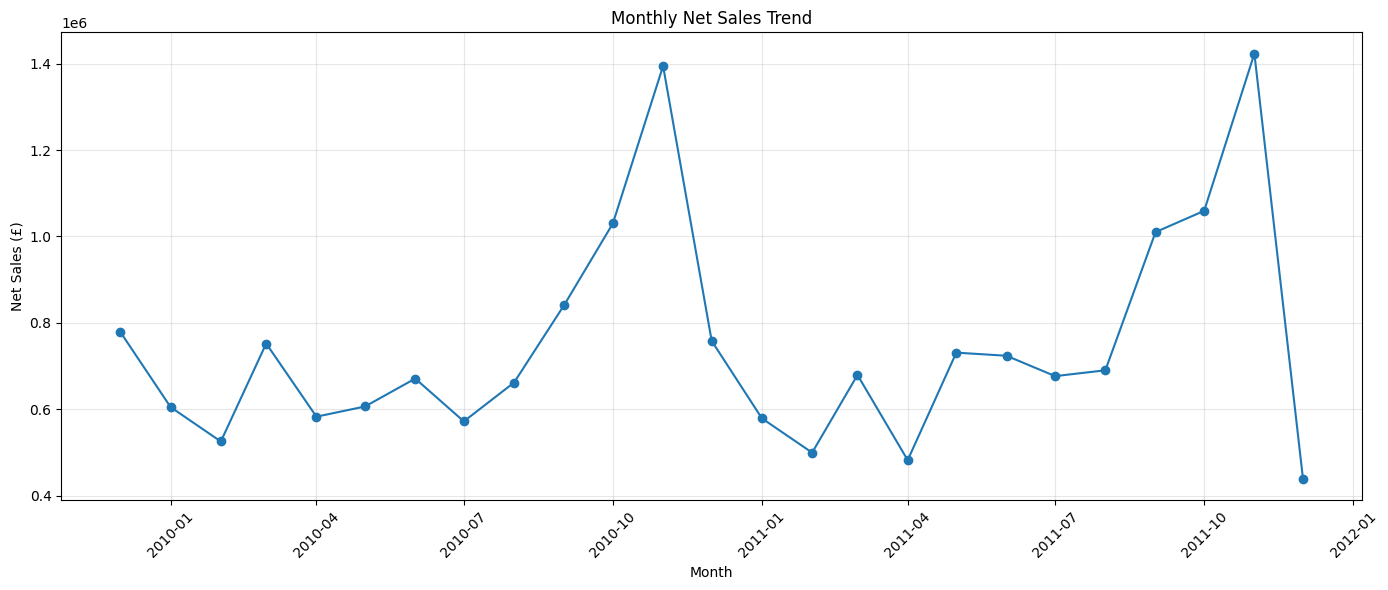

In [61]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["InvoiceDate"],
    monthly_sales["Net_Sales"],
    marker="o"
)

plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Step 4. Compare gross sales and returns

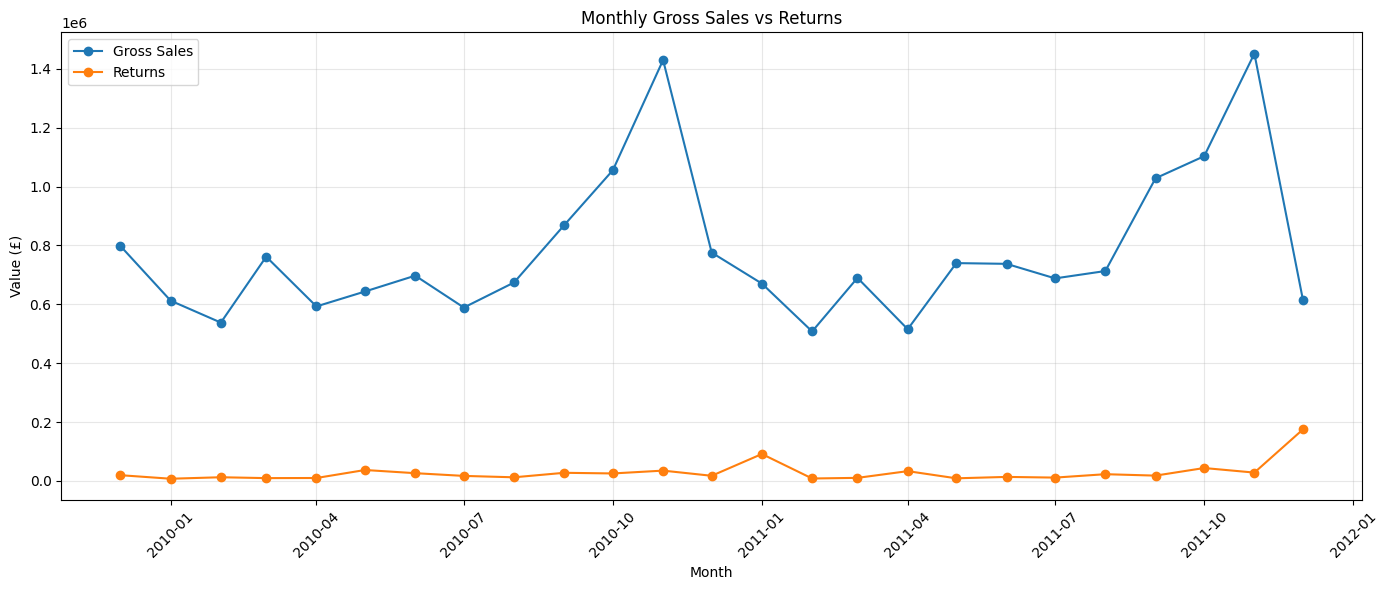

In [62]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["InvoiceDate"],
    monthly_sales["Gross_Sales"],
    label="Gross Sales",
    marker="o"
)

plt.plot(
    monthly_sales["InvoiceDate"],
    monthly_sales["Returns_Value"],
    label="Returns",
    marker="o"
)

plt.title("Monthly Gross Sales vs Returns")
plt.xlabel("Month")
plt.ylabel("Value (£)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
monthly_sales = (
    monthly_df
    .groupby(pd.Grouper(key="InvoiceDate", freq="MS"))
    .agg(
        Gross_Sales=("Gross_Sales", "sum"),
        Returns_Value=("Returns_Value", "sum"),
        Net_Sales=("Net_Sales", "sum"),
        Transaction_Lines=("Invoice", "count"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
)

display(monthly_sales)

,InvoiceDate,Gross_Sales,Returns_Value,Net_Sales,Transaction_Lines,Unique_Invoices
0,2009-12-01,798232.030,19558.08,778673.950,44477,2206
1,2010-01-01,612455.502,7535.19,604920.312,30909,1395
2,2010-02-01,537926.696,12575.44,525351.256,28452,1488
3,2010-03-01,761748.531,9603.85,752144.681,40493,2088
4,2010-04-01,592879.702,10025.26,582854.442,33332,1750
5,2010-05-01,643585.640,37192.89,606392.750,34357,2013
6,2010-06-01,697382.320,26373.46,671008.860,39091,2009
7,2010-07-01,589047.630,17132.73,571914.900,32697,1876
8,2010-08-01,674192.890,12397.60,661795.290,32663,1733
9,2010-09-01,869277.161,27686.42,841590.741,41243,2180


Next, inspect the December 2011 return records:

In [64]:
december_returns = product_df[
    (product_df["InvoiceDate"].dt.year == 2011) &
    (product_df["InvoiceDate"].dt.month == 12) &
    (product_df["Quantity"] < 0)
].copy()

print("December 2011 return records:", len(december_returns))

display(
    december_returns[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue",
            "Customer ID"
        ]
    ].sort_values(
        "TransactionValue"
    ).head(20)
)

December 2011 return records: 348


,Invoice,StockCode,Description,Quantity,Price,TransactionValue,Customer ID
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60,16446.0
1053454,C580726,CRUK,CRUK Commission,-1,1100.44,-1100.44,14096.0
1057280,C580971,22313,OFFICE MUG WARMER PINK,-250,2.55,-637.50,14298.0
1052774,C580702,23494,VINTAGE DOILY DELUXE SEWING KIT,-40,5.95,-238.00,17404.0
1062375,C581228,22781,GUMBALL MAGAZINE RACK,-24,6.75,-162.00,16019.0
1056873,C580954,21428,SET3 BOOK BOX GREEN GINGHAM FLOWER,-25,3.75,-93.75,12967.0
1045284,C580171,23108,SET OF 10 LED DOLLY LIGHTS,-24,3.39,-81.36,17949.0
1056813,C580918,21218,RED SPOTTY BISCUIT TIN,-24,3.25,-78.00,16779.0
1057277,C580970,22946,WOODEN ADVENT CALENDAR CREAM,-6,12.75,-76.50,15814.0
1062376,C581228,22467,GUMBALL COAT RACK,-36,2.10,-75.60,16019.0


4. Next: investigate the two unusual records

Code 1 — Inspect the large cancellation

In [65]:
# Find the unusual invoice
large_cancellation = df_analysis[
    df_analysis["Invoice"].astype(str) == "C581484"
]

display(
    large_cancellation[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "Customer ID",
            "Country",
            "TransactionValue"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID,Country,TransactionValue
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,16446.0,United Kingdom,-168469.6


Code 2 — Investigate all CRUK records

In [66]:
cruk_records = df_analysis[
    df_analysis["StockCode_norm"] == "CRUK"
].copy()

display(
    cruk_records[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "TransactionValue"
        ]
    ]
)

print("Total CRUK records:", len(cruk_records))
print("Total CRUK transaction value:",
      cruk_records["TransactionValue"].sum())

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,TransactionValue
842969,C564763,CRUK,CRUK Commission,-1,1.60,2011-08-30 10:49:00,-1.60
849464,C565382,CRUK,CRUK Commission,-1,13.01,2011-09-02 15:45:00,-13.01
859206,C566216,CRUK,CRUK Commission,-1,15.96,2011-09-09 15:17:00,-15.96
864273,C566565,CRUK,CRUK Commission,-1,52.24,2011-09-13 12:32:00,-52.24
876043,C567655,CRUK,CRUK Commission,-1,608.66,2011-09-21 14:40:00,-608.66
887050,C568345,CRUK,CRUK Commission,-1,447.56,2011-09-26 15:28:00,-447.56
898246,C569245,CRUK,CRUK Commission,-1,361.59,2011-10-03 09:57:00,-361.59
915425,C570487,CRUK,CRUK Commission,-1,411.92,2011-10-10 17:12:00,-411.92
927228,C571440,CRUK,CRUK Commission,-1,495.98,2011-10-17 13:31:00,-495.98
941573,C572551,CRUK,CRUK Commission,-1,425.14,2011-10-24 17:07:00,-425.14


Total CRUK records: 16
Total CRUK transaction value: -7933.43


Code 3 — Check the largest negative product transactions

In [67]:
largest_returns = (
    product_df[
        product_df["Quantity"] < 0
    ]
    .sort_values("TransactionValue")
    .head(15)
)

display(
    largest_returns[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue",
            "InvoiceDate"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,TransactionValue,InvoiceDate
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60,2011-12-09 09:27:00
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.60,2011-01-18 10:17:00
685606,C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,-6539.40,2011-04-18 13:08:00
685604,C550456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,-4921.50,2011-04-18 13:08:00
685602,C550456,48185,DOORMAT FAIRY CAKE,-670,6.75,-4522.50,2011-04-18 13:08:00
875211,C567527,23113,PANTRY CHOPPING BOARD,-756,5.06,-3825.36,2011-09-21 09:16:00
685605,C550456,21175,GIN + TONIC DIET METAL SIGN,-2000,1.85,-3700.00,2011-04-18 13:08:00
93676,C498151,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,-2504,1.45,-3630.80,2010-02-17 10:37:00
685603,C550456,47566B,TEA TIME PARTY BUNTING,-1300,2.55,-3315.00,2011-04-18 13:08:00
418860,C529352,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,-1152,2.75,-3168.00,2010-10-28 09:32:00


3. Next investigation: inspect the three unusual invoices

In [68]:
# Inspect unusual cancellation invoices

invoices_to_check = [
    "C581484",
    "C541433",
    "C550456"
]

unusual_invoices = df_analysis[
    df_analysis["Invoice"].astype(str).isin(invoices_to_check)
].copy()

unusual_invoice_summary = (
    unusual_invoices
    .groupby("Invoice")
    .agg(
        Records=("StockCode", "count"),
        Unique_Products=("StockCode", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Value=("TransactionValue", "sum"),
        Invoice_Date=("InvoiceDate", "min"),
        Customer_ID=("Customer ID", "first"),
        Country=("Country", "first")
    )
    .reset_index()
)

display(unusual_invoice_summary)

,Invoice,Records,Unique_Products,Total_Quantity,Total_Value,Invoice_Date,Customer_ID,Country
0,C541433,1,1,-74215,-77183.6,2011-01-18 10:17:00,12346.0,United Kingdom
1,C550456,5,5,-9014,-22998.4,2011-04-18 13:08:00,15749.0,United Kingdom
2,C581484,1,1,-80995,-168469.6,2011-12-09 09:27:00,16446.0,United Kingdom


Then inspect the individual product lines:

In [69]:
display(
    unusual_invoices[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue",
            "InvoiceDate",
            "Customer ID"
        ]
    ].sort_values(
        ["Invoice", "TransactionValue"]
    )
)

,Invoice,StockCode,Description,Quantity,Price,TransactionValue,InvoiceDate,Customer ID
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.6,2011-01-18 10:17:00,12346.0
685606,C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,-6539.4,2011-04-18 13:08:00,15749.0
685604,C550456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,-4921.5,2011-04-18 13:08:00,15749.0
685602,C550456,48185,DOORMAT FAIRY CAKE,-670,6.75,-4522.5,2011-04-18 13:08:00,15749.0
685605,C550456,21175,GIN + TONIC DIET METAL SIGN,-2000,1.85,-3700.0,2011-04-18 13:08:00,15749.0
685603,C550456,47566B,TEA TIME PARTY BUNTING,-1300,2.55,-3315.0,2011-04-18 13:08:00,15749.0
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6,2011-12-09 09:27:00,16446.0


4. Identify all extreme negative product quantities

In [70]:
extreme_returns = product_df[
    product_df["Quantity"] <= -1000
].copy()

extreme_returns["TransactionValue"] = (
    extreme_returns["Quantity"] *
    extreme_returns["Price"]
)

display(
    extreme_returns[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue",
            "InvoiceDate",
            "Customer ID"
        ]
    ].sort_values("Quantity")
)

print("Number of extreme return records:", len(extreme_returns))
print(
    "Total value of extreme returns:",
    extreme_returns["TransactionValue"].sum()
)

,Invoice,StockCode,Description,Quantity,Price,TransactionValue,InvoiceDate,Customer ID
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60,2011-12-09 09:27:00,16446.0
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.60,2011-01-18 10:17:00,12346.0
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,-280.80,2010-12-02 14:23:00,15838.0
359669,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,0.08,-570.24,2010-09-28 11:02:00,14277.0
359670,C524235,21096,SET/6 FRUIT SALAD PAPER PLATES,-7008,0.13,-911.04,2010-09-28 11:02:00,14277.0
359630,C524235,16047,POP ART PEN CASE & PENS,-5184,0.08,-414.72,2010-09-28 11:02:00,14277.0
359636,C524235,37340,MULTICOLOUR SPRING FLOWER MUG,-4992,0.10,-499.20,2010-09-28 11:02:00,14277.0
359653,C524235,85110,BLACK SILVER FLOWER T-LIGHT HOLDER,-4752,0.07,-332.64,2010-09-28 11:02:00,14277.0
359658,C524235,16046,TEATIME PEN CASE & PENS,-4608,0.08,-368.64,2010-09-28 11:02:00,14277.0
359654,C524235,85160A,WHITE BIRD GARDEN DESIGN MUG,-4320,0.13,-561.60,2010-09-28 11:02:00,14277.0


Number of extreme return records: 40
Total value of extreme returns: -285136.11


3. Next step: group extreme returns by invoice

In [71]:
# Summarise extreme returns by invoice

extreme_invoice_summary = (
    extreme_returns
    .groupby("Invoice")
    .agg(
        Records=("StockCode", "count"),
        Unique_Products=("StockCode", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Return_Value=("TransactionValue", "sum"),
        Invoice_Date=("InvoiceDate", "min"),
        Customer_ID=("Customer ID", "first")
    )
    .reset_index()
    .sort_values("Total_Return_Value")
)

display(extreme_invoice_summary)

,Invoice,Records,Unique_Products,Total_Quantity,Total_Return_Value,Invoice_Date,Customer_ID
12,C581484,1,1,-80995,-168469.60,2011-12-09 09:27:00,16446.0
7,C541433,1,1,-74215,-77183.60,2011-01-18 10:17:00,12346.0
8,C550456,4,4,-8344,-18475.90,2011-04-18 13:08:00,15749.0
3,C524235,25,25,-77384,-10422.00,2010-09-28 11:02:00,14277.0
0,C498151,1,1,-2504,-3630.80,2010-02-17 10:37:00,13902.0
4,C529352,1,1,-1152,-3168.00,2010-10-28 09:32:00,17450.0
11,C570556,1,1,-1296,-1373.76,2011-10-11 11:10:00,16029.0
2,C508334,1,1,-1200,-864.00,2010-05-14 12:04:00,13694.0
9,C556522,1,1,-1515,-833.25,2011-06-13 11:21:00,16938.0
6,C536757,1,1,-9360,-280.80,2010-12-02 14:23:00,15838.0


Then calculate how much these 40 records contribute to all product returns:

In [72]:
total_product_returns = product_df.loc[
    product_df["Quantity"] < 0,
    "TransactionValue"
].sum()

extreme_return_value = extreme_returns["TransactionValue"].sum()

print("Total product return value:", total_product_returns)
print("Extreme return value:", extreme_return_value)

print(
    "Share of return value (%):",
    round(
        abs(extreme_return_value) /
        abs(total_product_returns) * 100,
        2
    )
)

Total product return value: -724473.06
Extreme return value: -285136.11
Share of return value (%): 39.36


2. Check the two invoice summaries that differ from the earlier inspection

In [73]:
# Inspect the two invoices directly
for invoice in ["C550456", "C524235"]:
    print(f"\nInvoice: {invoice}")

    display(
        extreme_returns[
            extreme_returns["Invoice"] == invoice
        ][[
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue",
            "InvoiceDate",
            "Customer ID"
        ]].sort_values("TransactionValue")
    )


Invoice: C550456


,Invoice,StockCode,Description,Quantity,Price,TransactionValue,InvoiceDate,Customer ID
685606,C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,-6539.4,2011-04-18 13:08:00,15749.0
685604,C550456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,-4921.5,2011-04-18 13:08:00,15749.0
685605,C550456,21175,GIN + TONIC DIET METAL SIGN,-2000,1.85,-3700.0,2011-04-18 13:08:00,15749.0
685603,C550456,47566B,TEA TIME PARTY BUNTING,-1300,2.55,-3315.0,2011-04-18 13:08:00,15749.0



Invoice: C524235


,Invoice,StockCode,Description,Quantity,Price,TransactionValue,InvoiceDate,Customer ID
359674,C524235,85184D,S/4 BLUE ROUND DECOUPAGE BOXES,-3936,0.42,-1653.12,2010-09-28 11:02:00,14277.0
359670,C524235,21096,SET/6 FRUIT SALAD PAPER PLATES,-7008,0.13,-911.04,2010-09-28 11:02:00,14277.0
359669,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,0.08,-570.24,2010-09-28 11:02:00,14277.0
359654,C524235,85160A,WHITE BIRD GARDEN DESIGN MUG,-4320,0.13,-561.60,2010-09-28 11:02:00,14277.0
359668,C524235,21082,SET/20 FRUIT SALAD PAPER NAPKINS,-3072,0.17,-522.24,2010-09-28 11:02:00,14277.0
359636,C524235,37340,MULTICOLOUR SPRING FLOWER MUG,-4992,0.10,-499.20,2010-09-28 11:02:00,14277.0
359634,C524235,21392,RED POLKADOT PUDDING BOWL,-3648,0.13,-474.24,2010-09-28 11:02:00,14277.0
359651,C524235,85006,SET 4 NURSERY DES ROUND BOXES,-1440,0.31,-446.40,2010-09-28 11:02:00,14277.0
359630,C524235,16047,POP ART PEN CASE & PENS,-5184,0.08,-414.72,2010-09-28 11:02:00,14277.0
359672,C524235,21279,VINTAGE KITCHEN PRINT FRUITS,-1632,0.25,-408.00,2010-09-28 11:02:00,14277.0


3. Calculate how concentrated the extreme returns are

In [74]:
extreme_invoice_summary["Return_Value_Share_%"] = (
    extreme_invoice_summary["Total_Return_Value"].abs()
    / abs(extreme_returns["TransactionValue"].sum())
    * 100
)

display(
    extreme_invoice_summary[
        [
            "Invoice",
            "Records",
            "Total_Return_Value",
            "Return_Value_Share_%"
        ]
    ].sort_values(
        "Total_Return_Value"
    )
)

,Invoice,Records,Total_Return_Value,Return_Value_Share_%
12,C581484,1,-168469.60,59.083923
7,C541433,1,-77183.60,27.069037
8,C550456,4,-18475.90,6.479677
3,C524235,25,-10422.00,3.655097
0,C498151,1,-3630.80,1.273357
4,C529352,1,-3168.00,1.111048
11,C570556,1,-1373.76,0.481791
2,C508334,1,-864.00,0.303013
9,C556522,1,-833.25,0.292229
6,C536757,1,-280.80,0.098479


Step 1 — Identify the products with the largest return quantities

In [75]:
extreme_product_summary = (
    extreme_returns
    .groupby(["StockCode", "Description"])
    .agg(
        Return_Records=("Invoice", "count"),
        Total_Returned_Quantity=("Quantity", "sum"),
        Total_Return_Value=("TransactionValue", "sum"),
        Unique_Invoices=("Invoice", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Return_Value")
)

display(extreme_product_summary.head(15))

,StockCode,Description,Return_Records,Total_Returned_Quantity,Total_Return_Value,Unique_Invoices,Unique_Customers
19,23843,"PAPER CRAFT , LITTLE BIRDIE",1,-80995,-168469.60,1,1
18,23166,MEDIUM CERAMIC TOP STORAGE JAR,1,-74215,-77183.60,1,1
9,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,1,-3114,-6539.40,1,1
36,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1,-1930,-4921.50,1,1
10,21175,GIN + TONIC DIET METAL SIGN,1,-2000,-3700.00,1,1
30,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,1,-2504,-3630.80,1,1
34,47566B,TEA TIME PARTY BUNTING,1,-1300,-3315.00,1,1
23,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,1,-1152,-3168.00,1,1
39,85184D,S/4 BLUE ROUND DECOUPAGE BOXES,1,-3936,-1653.12,1,1
5,20971,PINK BLUE FELT CRAFT TRINKET BOX,1,-1296,-1373.76,1,1


Step 2 — Check the overall distribution

In [76]:
print("Unique products:", extreme_returns["StockCode"].nunique())
print("Unique invoices:", extreme_returns["Invoice"].nunique())
print("Unique customers:", extreme_returns["Customer ID"].nunique())
print("Extreme return records:", len(extreme_returns))

Unique products: 40
Unique invoices: 13
Unique customers: 13
Extreme return records: 40


2. Next investigation: Can we find the original sales?

In [77]:
# Keep positive product sales
positive_sales = product_df[
    product_df["Quantity"] > 0
].copy()

# Match extreme returns to earlier sales
matched_sales = extreme_returns[
    [
        "Invoice",
        "StockCode_norm",
        "Description",
        "Quantity",
        "InvoiceDate",
        "Customer ID"
    ]
].merge(
    positive_sales[
        [
            "Invoice",
            "StockCode_norm",
            "Quantity",
            "Price",
            "InvoiceDate",
            "Customer ID"
        ]
    ],
    on=["StockCode_norm", "Customer ID"],
    how="left",
    suffixes=("_return", "_sale")
)

# Keep only sales that occurred before the return
matched_sales = matched_sales[
    matched_sales["InvoiceDate_sale"]
    < matched_sales["InvoiceDate_return"]
]

display(
    matched_sales.sort_values(
        "InvoiceDate_return"
    ).head(20)
)

,Invoice_return,StockCode_norm,Description,Quantity_return,InvoiceDate_return,Customer ID,Invoice_sale,Quantity_sale,Price,InvoiceDate_sale
0,C498151,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,-2504,2010-02-17 10:37:00,13902.0,497946,2504.0,1.45,2010-02-15 11:57:00
2,C504415,84270,ASSTD DESIGN BUBBLE GUM RING,-1440,2010-04-13 12:33:00,12971.0,503828,1440.0,0.16,2010-04-07 15:43:00
3,C508334,47587A,PINK FAIRY CAKE COASTER,-1200,2010-05-14 12:04:00,13694.0,501614,160.0,0.19,2010-03-18 10:58:00
4,C508334,47587A,PINK FAIRY CAKE COASTER,-1200,2010-05-14 12:04:00,13694.0,508333,1200.0,0.72,2010-05-14 12:00:00
31,C524235,85184D,S/4 BLUE ROUND DECOUPAGE BOXES,-3936,2010-09-28 11:02:00,14277.0,518505,3936.0,0.42,2010-08-09 13:10:00
30,C524235,85160B,BLACK BIRD GARDEN DESIGN MUG,-2976,2010-09-28 11:02:00,14277.0,518505,2976.0,0.13,2010-08-09 13:10:00
29,C524235,21279,VINTAGE KITCHEN PRINT FRUITS,-1632,2010-09-28 11:02:00,14277.0,518505,1632.0,0.25,2010-08-09 13:10:00
28,C524235,21278,VINTAGE KITCHEN PRINT PUDDINGS,-1200,2010-09-28 11:02:00,14277.0,518505,1200.0,0.25,2010-08-09 13:10:00
27,C524235,21096,SET/6 FRUIT SALAD PAPER PLATES,-7008,2010-09-28 11:02:00,14277.0,518505,7008.0,0.13,2010-08-09 13:10:00
26,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,2010-09-28 11:02:00,14277.0,518505,7128.0,0.08,2010-08-09 13:10:00


3. Next step — calculate exact quantity matches

In [78]:
# Check whether returned quantities match the earlier sale quantities

matched_sales["Quantity_Match"] = (
    matched_sales["Quantity_return"].abs()
    == matched_sales["Quantity_sale"]
)

print("Matched records:", len(matched_sales))

print(
    "Exact quantity matches:",
    matched_sales["Quantity_Match"].sum()
)

print(
    "Non-exact quantity matches:",
    (~matched_sales["Quantity_Match"]).sum()
)

display(
    matched_sales[
        [
            "Invoice_return",
            "StockCode_norm",
            "Quantity_return",
            "Invoice_sale",
            "Quantity_sale",
            "Quantity_Match"
        ]
    ]
)

Matched records: 45
Exact quantity matches: 40
Non-exact quantity matches: 5


,Invoice_return,StockCode_norm,Quantity_return,Invoice_sale,Quantity_sale,Quantity_Match
0,C498151,85220,-2504,497946,2504.0,True
2,C504415,84270,-1440,503828,1440.0,True
3,C508334,47587A,-1200,501614,160.0,False
4,C508334,47587A,-1200,508333,1200.0,True
6,C524235,16047,-5184,491715,12.0,False
7,C524235,16047,-5184,518505,5184.0,True
8,C524235,21280,-1248,518505,1248.0,True
9,C524235,21281,-1536,518505,1536.0,True
10,C524235,21392,-3648,518505,3648.0,True
11,C524235,21393,-2496,518505,2496.0,True


4. Then calculate the matching coverage

In [79]:
print(
    "Extreme return records:",
    len(extreme_returns)
)

print(
    "Records with an earlier sale match:",
    matched_sales["Invoice_return"].nunique()
)

print(
    "Percentage of extreme-return invoices matched:",
    round(
        matched_sales["Invoice_return"].nunique()
        / extreme_returns["Invoice"].nunique() * 100,
        2
    ),
    "%"
)

Extreme return records: 40
Records with an earlier sale match: 13
Percentage of extreme-return invoices matched: 100.0 %


3. Next step — summarise exact matches by return invoice

In [80]:
invoice_match_summary = (
    matched_sales
    .groupby("Invoice_return")
    .agg(
        Candidate_Sales=("Invoice_sale", "count"),
        Exact_Matches=("Quantity_Match", "sum"),
        Exact_Match_Exists=("Quantity_Match", "any"),
        Return_Quantity=("Quantity_return", "first")
    )
    .reset_index()
)

display(
    invoice_match_summary.sort_values(
        "Invoice_return"
    )
)

,Invoice_return,Candidate_Sales,Exact_Matches,Exact_Match_Exists,Return_Quantity
0,C498151,1,1,True,-2504
1,C504415,1,1,True,-1440
2,C508334,2,1,True,-1200
3,C524235,26,25,True,-5184
4,C529352,1,1,True,-1152
5,C533125,1,1,True,-2400
6,C536757,3,1,True,-9360
7,C541433,1,1,True,-74215
8,C550456,3,3,True,-1930
9,C556522,1,1,True,-1515


Next step: check matching at the individual return-line level

In [81]:
# Give every extreme-return record a unique ID
return_records = extreme_returns.copy()
return_records["return_row_id"] = range(len(return_records))

# Keep positive sales
sales_records = product_df[
    product_df["Quantity"] > 0
].copy()

# Match returns to earlier sales by customer and product
matched_candidates = return_records.merge(
    sales_records,
    on=["Customer ID", "StockCode_norm"],
    suffixes=("_return", "_sale")
)

# Keep only sales made before the return
matched_candidates = matched_candidates[
    matched_candidates["InvoiceDate_sale"]
    < matched_candidates["InvoiceDate_return"]
].copy()

# Check whether the sale quantity exactly equals the returned quantity
matched_candidates["Quantity_Match"] = (
    matched_candidates["Quantity_return"].abs()
    == matched_candidates["Quantity_sale"]
)

Now create a summary for each individual return record:

In [82]:
line_match_summary = (
    matched_candidates
    .groupby("return_row_id")
    .agg(
        Invoice_return=("Invoice_return", "first"),
        StockCode_norm=("StockCode_norm", "first"),
        Quantity_return=("Quantity_return", "first"),
        Candidate_Sales=("Invoice_sale", "nunique"),
        Exact_Quantity_Candidates=("Quantity_Match", "sum"),
        Exact_Match_Exists=("Quantity_Match", "any")
    )
    .reset_index()
)

display(line_match_summary)

,return_row_id,Invoice_return,StockCode_norm,Quantity_return,Candidate_Sales,Exact_Quantity_Candidates,Exact_Match_Exists
0,0,C498151,85220,-2504,1,1,True
1,1,C504415,84270,-1440,1,1,True
2,2,C508334,47587A,-1200,2,1,True
3,3,C524235,16047,-5184,2,1,True
4,4,C524235,21280,-1248,1,1,True
5,5,C524235,21281,-1536,1,1,True
6,6,C524235,21392,-3648,1,1,True
7,7,C524235,21393,-2496,1,1,True
8,8,C524235,37340,-4992,1,1,True
9,9,C524235,37423,-2952,1,1,True


Finally, calculate the overall matching coverage:

In [83]:
total_returns = len(return_records)

matched_lines = len(line_match_summary)

exactly_matched_lines = line_match_summary[
    "Exact_Match_Exists"
].sum()

unmatched_returns = return_records[
    ~return_records["return_row_id"].isin(
        matched_candidates["return_row_id"]
    )
]

print("Total extreme-return records:", total_returns)
print("Records with earlier sales candidates:", matched_lines)
print("Records with exact quantity matches:", exactly_matched_lines)
print("Records without earlier sales candidates:", len(unmatched_returns))

Total extreme-return records: 40
Records with earlier sales candidates: 39
Records with exact quantity matches: 39
Records without earlier sales candidates: 1


1. Identify the unmatched return

In [84]:
unmatched_returns = return_records[
    ~return_records["return_row_id"].isin(
        matched_candidates["return_row_id"]
    )
]

display(
    unmatched_returns[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "Customer ID",
            "TransactionValue"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID,TransactionValue
685603,C550456,47566B,TEA TIME PARTY BUNTING,-1300,2.55,2011-04-18 13:08:00,15749.0,-3315.0


In [85]:
product_history = product_df[
    (product_df["Customer ID"] == 15749) &
    (product_df["StockCode_norm"] == "47566B")
].sort_values("InvoiceDate")

display(
    product_history[
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "TransactionValue"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,TransactionValue
685603,C550456,47566B,TEA TIME PARTY BUNTING,-1300,2.55,2011-04-18 13:08:00,-3315.0


Step 1 – Prepare product-level metrics

In [86]:
# Create a copy of merchandise transactions
product_performance_df = product_df.copy()

# Separate sales and returns
product_performance_df["Gross_Sales"] = np.where(
    product_performance_df["Quantity"] > 0,
    product_performance_df["TransactionValue"],
    0
)

product_performance_df["Return_Value"] = np.where(
    product_performance_df["Quantity"] < 0,
    abs(product_performance_df["TransactionValue"]),
    0
)

product_performance_df["Gross_Units"] = np.where(
    product_performance_df["Quantity"] > 0,
    product_performance_df["Quantity"],
    0
)

product_performance_df["Returned_Units"] = np.where(
    product_performance_df["Quantity"] < 0,
    abs(product_performance_df["Quantity"]),
    0
)

# Aggregate by product
product_summary = (
    product_performance_df
    .groupby("StockCode_norm")
    .agg(
        Description=("Description", "first"),
        Gross_Sales=("Gross_Sales", "sum"),
        Return_Value=("Return_Value", "sum"),
        Gross_Units=("Gross_Units", "sum"),
        Returned_Units=("Returned_Units", "sum"),
        Sales_Invoices=(
            "Invoice",
            lambda x: x[
                product_performance_df.loc[x.index, "Quantity"] > 0
            ].nunique()
        )
    )
    .reset_index()
)

# Calculate net sales and return rate
product_summary["Net_Sales"] = (
    product_summary["Gross_Sales"]
    - product_summary["Return_Value"]
)

product_summary["Unit_Return_Rate"] = np.where(
    product_summary["Gross_Units"] > 0,
    product_summary["Returned_Units"]
    / product_summary["Gross_Units"] * 100,
    0
)

# Sort by net sales
product_summary = product_summary.sort_values(
    "Net_Sales",
    ascending=False
)

display(product_summary.head(10))

,StockCode_norm,Description,Gross_Sales,Return_Value,Gross_Units,Returned_Units,Sales_Invoices,Net_Sales,Unit_Return_Rate
1656,22423,REGENCY CAKESTAND 3 TIER,330590.32,16545.30,26495,1450,3920,314045.02,5.472731
4225,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,98724,3637,5470,251781.63,3.684008
4203,85099B,JUMBO BAG RED WHITE SPOTTY,182680.98,2168.82,97183,1213,4018,180512.16,1.248161
3168,47566,PARTY BUNTING,148318.28,1238.55,28248,285,2677,147079.73,1.008921
3956,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,774.07,80090,511,2808,128550.42,0.638032
1343,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,1461.70,35113,590,2019,116298.59,1.680289
3449,79321,CHILLI LIGHTS,80540.88,635.75,15988,145,1149,79905.13,0.906930
1450,22197,"POPCORN HOLDER , SMALL",79520.20,616.58,88993,804,2329,78903.62,0.903442
1625,22386,JUMBO BAG PINK WITH WHITE SPOTS,76324.62,866.98,39437,482,2245,75457.64,1.222203
3593,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,71300.40,330.45,31522,9381,759,70969.95,29.760168


Step 2 – Compare product rankings

In [87]:
# Top 10 products by gross revenue
top_revenue = product_summary.sort_values(
    "Gross_Sales", ascending=False
).head(10)

# Top 10 products by units sold
top_quantity = product_summary.sort_values(
    "Gross_Units", ascending=False
).head(10)

# Top 10 products by net sales
top_net_sales = product_summary.sort_values(
    "Net_Sales", ascending=False
).head(10)

display(top_revenue)
display(top_quantity)
display(top_net_sales)

,StockCode_norm,Description,Gross_Sales,Return_Value,Gross_Units,Returned_Units,Sales_Invoices,Net_Sales,Unit_Return_Rate
1656,22423,REGENCY CAKESTAND 3 TIER,330590.32,16545.30,26495,1450,3920,314045.02,5.472731
4225,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,98724,3637,5470,251781.63,3.684008
4203,85099B,JUMBO BAG RED WHITE SPOTTY,182680.98,2168.82,97183,1213,4018,180512.16,1.248161
2818,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,168469.60,80995,80995,1,0.00,100.000000
3168,47566,PARTY BUNTING,148318.28,1238.55,28248,285,2677,147079.73,1.008921
3956,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,774.07,80090,511,2808,128550.42,0.638032
1343,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,1461.70,35113,590,2019,116298.59,1.680289
2372,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,77479.64,78033,74494,247,4221.28,95.464739
3449,79321,CHILLI LIGHTS,80540.88,635.75,15988,145,1149,79905.13,0.906930
1450,22197,"POPCORN HOLDER , SMALL",79520.20,616.58,88993,804,2329,78903.62,0.903442


,StockCode_norm,Description,Gross_Sales,Return_Value,Gross_Units,Returned_Units,Sales_Invoices,Net_Sales,Unit_Return_Rate
3540,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,24445.61,361.68,106250,1704,1021,24083.93,1.603765
4225,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,98724,3637,5470,251781.63,3.684008
4203,85099B,JUMBO BAG RED WHITE SPOTTY,182680.98,2168.82,97183,1213,4018,180512.16,1.248161
621,21212,PACK OF 72 RETRO SPOT CAKE CASES,51825.15,549.66,94884,1110,3118,51275.49,1.169850
1450,22197,"POPCORN HOLDER , SMALL",79520.20,616.58,88993,804,2329,78903.62,0.903442
2818,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,168469.60,80995,80995,1,0.00,100.000000
3956,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,774.07,80090,511,2808,128550.42,0.638032
2372,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,77479.64,78033,74494,247,4221.28,95.464739
111,17003,BROCADE RING PURSE,14766.42,215.78,70379,740,457,14550.64,1.051450
1262,21977,PACK OF 60 PINK PAISLEY CAKE CASES,28081.73,117.30,56061,219,1993,27964.43,0.390646


,StockCode_norm,Description,Gross_Sales,Return_Value,Gross_Units,Returned_Units,Sales_Invoices,Net_Sales,Unit_Return_Rate
1656,22423,REGENCY CAKESTAND 3 TIER,330590.32,16545.30,26495,1450,3920,314045.02,5.472731
4225,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,98724,3637,5470,251781.63,3.684008
4203,85099B,JUMBO BAG RED WHITE SPOTTY,182680.98,2168.82,97183,1213,4018,180512.16,1.248161
3168,47566,PARTY BUNTING,148318.28,1238.55,28248,285,2677,147079.73,1.008921
3956,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,774.07,80090,511,2808,128550.42,0.638032
1343,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,1461.70,35113,590,2019,116298.59,1.680289
3449,79321,CHILLI LIGHTS,80540.88,635.75,15988,145,1149,79905.13,0.906930
1450,22197,"POPCORN HOLDER , SMALL",79520.20,616.58,88993,804,2329,78903.62,0.903442
1625,22386,JUMBO BAG PINK WITH WHITE SPOTS,76324.62,866.98,39437,482,2245,75457.64,1.222203
3593,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,71300.40,330.45,31522,9381,759,70969.95,29.760168


Step 3 – Investigate products with high return rates

In [88]:
high_return_products = (
    product_summary[
        product_summary["Gross_Units"] >= 1000
    ]
    .sort_values("Unit_Return_Rate", ascending=False)
    .head(15)
)

display(high_return_products)

,StockCode_norm,Description,Gross_Sales,Return_Value,Gross_Units,Returned_Units,Sales_Invoices,Net_Sales,Unit_Return_Rate
2818,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,168469.60,80995,80995,1,0.00,100.000000
2372,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,77479.64,78033,74494,247,4221.28,95.464739
2319,23113,PANTRY CHOPPING BOARD,5868.50,4803.06,1154,946,57,1065.44,81.975737
3640,84493,BLUE/PINK NEST STRIPE BOX,111.12,45.36,1142,567,5,65.76,49.649737
44,16047,POP ART PEN CASE & PENS,1054.70,414.72,10612,5184,31,639.98,48.850358
3029,37471,MULTICOLOUR DOTS PLATE,197.85,68.40,1405,684,10,129.45,48.683274
4088,85006,SET 4 NURSERY DES ROUND BOXES,1289.31,564.40,3049,1480,37,724.91,48.540505
781,21392,RED SPOTTY PUDDING BOWL,1478.13,478.44,7545,3650,48,999.69,48.376408
3015,37444B,BLUE BREAKFAST CUP AND SAUCER,409.60,127.92,2036,984,30,281.68,48.330059
3014,37444A,YELLOW BREAKFAST CUP AND SAUCER,563.43,172.99,2715,1309,46,390.44,48.213628


2. Create your first product-performance charts

Top 10 products by net sales.

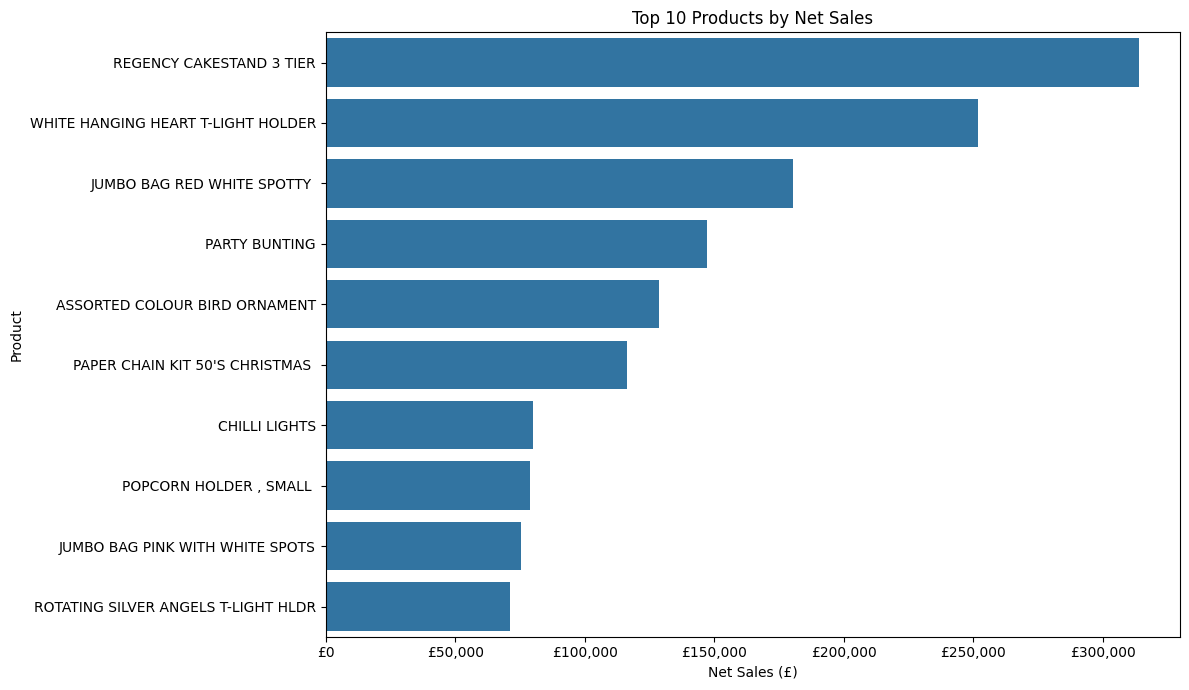

In [89]:
from matplotlib.ticker import FuncFormatter

top10_net = product_summary.nlargest(10, "Net_Sales")

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=top10_net,
    x="Net_Sales",
    y="Description",
    ax=ax
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x:,.0f}")
)

ax.set_title("Top 10 Products by Net Sales")
ax.set_xlabel("Net Sales (£)")
ax.set_ylabel("Product")

plt.tight_layout()

plt.savefig(
    "../images/top10_products_net_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Top 10 products by gross units sold.

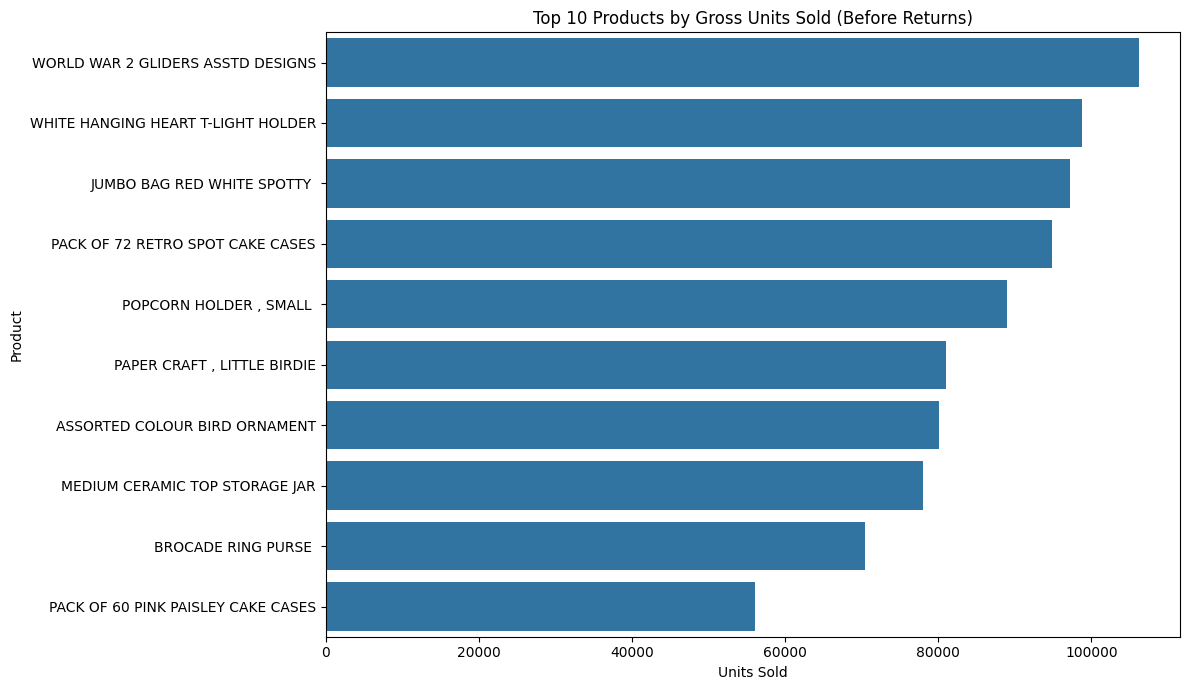

In [90]:
# Top 10 products by quantity sold
top10_units = product_summary.nlargest(10, "Gross_Units")

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10_units,
    x="Gross_Units",
    y="Description"
)

plt.title("Top 10 Products by Gross Units Sold (Before Returns)")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Step 1 – Create monthly product sales data

In [91]:
# Select positive product sales
monthly_product_df = product_df[
    product_df["Quantity"] > 0
].copy()

# Create month column
monthly_product_df["Month"] = (
    monthly_product_df["InvoiceDate"].dt.to_period("M")
)

# Aggregate monthly product sales
monthly_product_sales = (
    monthly_product_df
    .groupby(["Month", "StockCode_norm"])
    .agg(
        Description=("Description", "first"),
        Monthly_Revenue=("TransactionValue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Sales_Invoices=("Invoice", "nunique")
    )
    .reset_index()
)

# Convert Month to datetime for plotting
monthly_product_sales["Month"] = (
    monthly_product_sales["Month"].dt.to_timestamp()
)

display(monthly_product_sales.head(10))

,Month,StockCode_norm,Description,Monthly_Revenue,Units_Sold,Sales_Invoices
0,2009-12-01,10002,INFLATABLE POLITICAL GLOBE,185.30,215,20
1,2009-12-01,10002R,ROBOT PENCIL SHARPNER,15.51,3,2
2,2009-12-01,10080,GROOVY CACTUS INFLATABLE,3.40,4,2
3,2009-12-01,10109,BENDY COLOUR PENCILS,1.68,4,1
4,2009-12-01,10120,DOGGY RUBBER,26.13,115,12
5,2009-12-01,10123C,HEARTS WRAPPING TAPE,84.68,142,13
6,2009-12-01,10123G,ARMY CAMO WRAPPING TAPE,3.40,2,1
7,2009-12-01,10125,MINI FUNKY DESIGN TAPES,111.35,127,15
8,2009-12-01,10133,COLOURING PENCILS BROWN TUBE,131.75,154,16
9,2009-12-01,10134,COLOURING PENCILS BROWN TUBE,67.57,53,9


Step 2 – Create the monthly sales trend chart

In [92]:
# Identify top 10 products by gross sales
top10_product_codes = (
    product_summary
    .nlargest(10, "Gross_Sales")["StockCode_norm"]
)

# Filter monthly data for these products
top10_monthly = monthly_product_sales[
    monthly_product_sales["StockCode_norm"].isin(
        top10_product_codes
    )
].copy()

# Display sample
display(top10_monthly.head(10))

,Month,StockCode_norm,Description,Monthly_Revenue,Units_Sold,Sales_Invoices
1230,2009-12-01,22086,PAPER CHAIN KIT 50'S CHRISTMAS,10169.36,3362,184
1336,2009-12-01,22197,"POPCORN HOLDER , SMALL",1194.70,1929,51
1749,2009-12-01,47566,PARTY BUNTING,592.70,118,29
1982,2009-12-01,79321,CHILLI LIGHTS,2279.29,487,52
2376,2009-12-01,84879,ASSORTED COLOUR BIRD ORNAMENT,7623.93,4642,107
2582,2009-12-01,85099B,JUMBO BAG RED WHITE SPOTTY,6701.50,3771,135
2603,2009-12-01,85123A,WHITE HANGING HEART T-LIGHT HOLDER,17255.35,6406,304
4169,2010-01-01,22086,PAPER CHAIN KIT 50'S CHRISTMAS,113.42,23,11
4263,2010-01-01,22197,"POPCORN HOLDER , SMALL",590.24,737,32
4621,2010-01-01,47566,PARTY BUNTING,1585.30,346,43


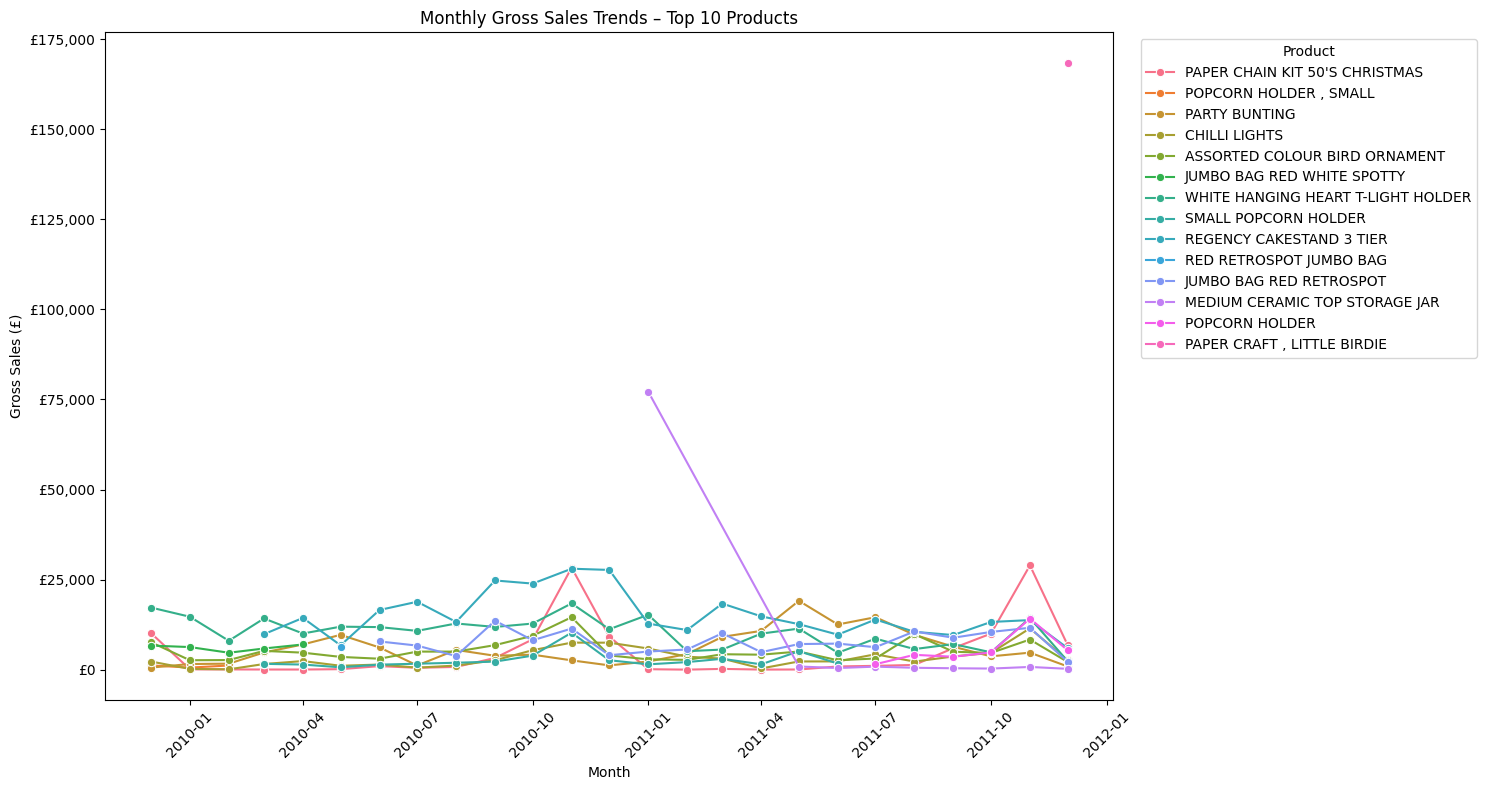

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(15, 8))

sns.lineplot(
    data=top10_monthly,
    x="Month",
    y="Monthly_Revenue",
    hue="Description",
    marker="o"
)

plt.title("Monthly Gross Sales Trends – Top 10 Products")
plt.xlabel("Month")
plt.ylabel("Gross Sales (£)")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x:,.0f}")
)

plt.xticks(rotation=45)

plt.legend(
    title="Product",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

2. Fix the product names in your chart

In [94]:
# Select top 10 product codes
top10_product_codes = (
    product_summary
    .nlargest(10, "Gross_Sales")["StockCode_norm"]
)

# Create a consistent product name mapping
product_names = (
    product_summary
    .set_index("StockCode_norm")["Description"]
)

# Filter monthly sales
top10_monthly = monthly_product_sales[
    monthly_product_sales["StockCode_norm"].isin(
        top10_product_codes
    )
].copy()

# Assign consistent names
top10_monthly["Product_Name"] = (
    top10_monthly["StockCode_norm"].map(product_names)
)

print("Unique products:", top10_monthly["StockCode_norm"].nunique())
print("Legend categories:", top10_monthly["Product_Name"].nunique())

Unique products: 10
Legend categories: 10


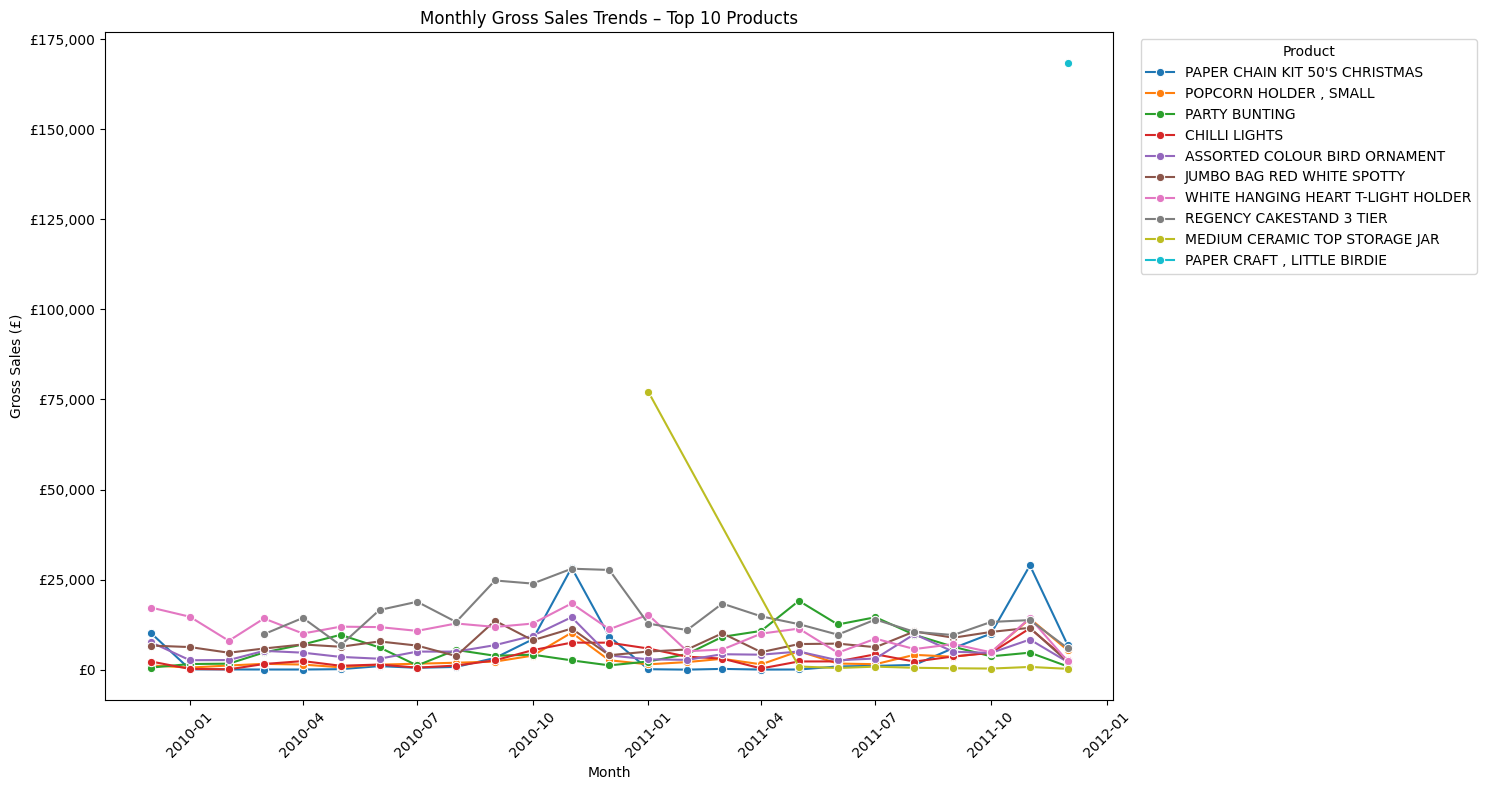

In [95]:
plt.figure(figsize=(15, 8))

sns.lineplot(
    data=top10_monthly,
    x="Month",
    y="Monthly_Revenue",
    hue="Product_Name",
    marker="o"
)

plt.title("Monthly Gross Sales Trends – Top 10 Products")
plt.xlabel("Month")
plt.ylabel("Gross Sales (£)")

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x:,.0f}")
)

plt.xticks(rotation=45)
plt.legend(
    title="Product",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Step 1 – Identify Christmas-related products

In [96]:
# Identify Christmas-related products
christmas_products = product_summary[
    product_summary["Description"].str.contains(
        "CHRISTMAS|XMAS|SANTA|REINDEER|SNOWMAN",
        case=False,
        na=False
    )
].copy()

print("Christmas-related products:", len(christmas_products))

display(
    christmas_products[
        [
            "StockCode_norm",
            "Description",
            "Gross_Sales",
            "Gross_Units",
            "Net_Sales"
        ]
    ].head(20)
)

Christmas-related products: 209


,StockCode_norm,Description,Gross_Sales,Gross_Units,Net_Sales
1343,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,35113,116298.59
2126,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,58652.70,19648,57467.10
1954,22734,SET OF 6 RIBBONS VINTAGE CHRISTMAS,26763.75,10131,26677.05
2537,23344,JUMBO BAG 50'S CHRISTMAS,23772.07,10285,23285.11
2157,22941,CHRISTMAS LIGHTS 10 REINDEER,21727.58,2615,21117.28
4152,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,21201.13,2685,20505.78
2168,22952,72 CAKE CASES VINTAGE CHRISTMAS,19240.05,33988,18998.85
2506,23313,VINTAGE CHRISTMAS BUNTING,15798.66,2990,15734.31
2156,22940,FELTCRAFT CHRISTMAS FAIRY,15282.81,3491,15162.06
2125,22909,SET OF 20 VINTAGE CHRISTMAS NAPKINS,15275.82,18144,14941.60


Step 2 – Calculate monthly Christmas sales

In [97]:
# Select Christmas-related product codes
christmas_codes = christmas_products["StockCode_norm"]

# Filter monthly product sales
christmas_monthly = monthly_product_sales[
    monthly_product_sales["StockCode_norm"].isin(
        christmas_codes
    )
].copy()

# Aggregate monthly revenue and units
christmas_monthly_summary = (
    christmas_monthly
    .groupby("Month")
    .agg(
        Monthly_Revenue=("Monthly_Revenue", "sum"),
        Units_Sold=("Units_Sold", "sum")
    )
    .reset_index()
)

display(christmas_monthly_summary)

,Month,Monthly_Revenue,Units_Sold
0,2009-12-01,26640.43,17519
1,2010-01-01,852.18,815
2,2010-02-01,790.06,751
3,2010-03-01,1416.22,1751
4,2010-04-01,613.91,627
5,2010-05-01,1395.42,1417
6,2010-06-01,2104.04,1874
7,2010-07-01,6376.88,6944
8,2010-08-01,14317.44,14362
9,2010-09-01,55427.15,51861


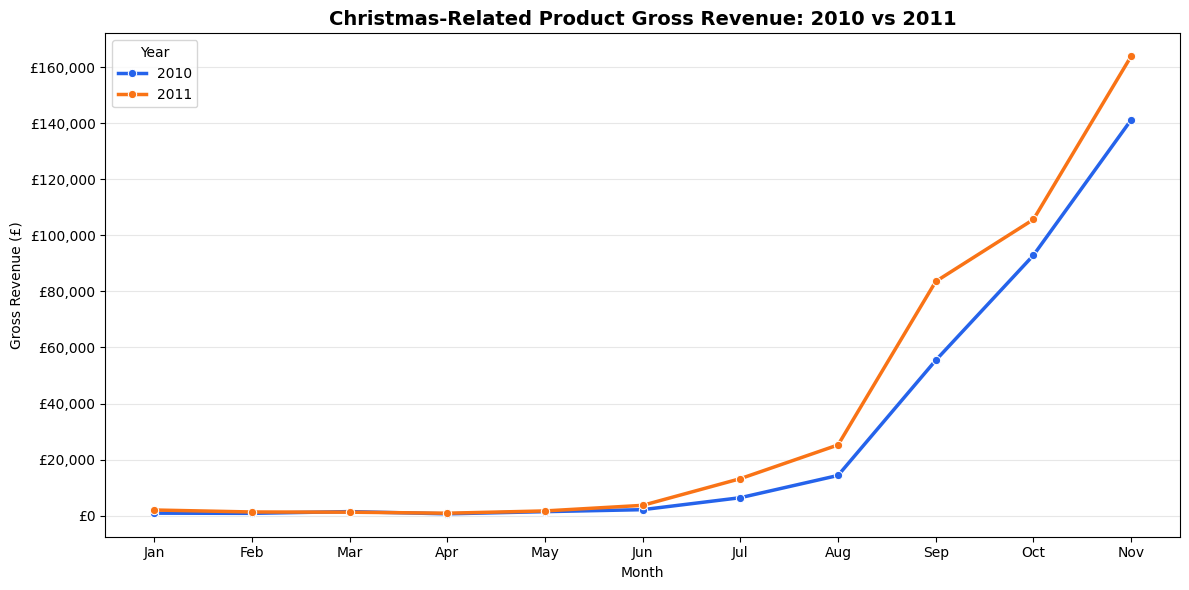

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Extract year and month
christmas_monthly_summary["Year"] = (
    christmas_monthly_summary["Month"].dt.year
)

christmas_monthly_summary["Month_Number"] = (
    christmas_monthly_summary["Month"].dt.month
)

# Select January–November for 2010 and 2011
christmas_comparison = christmas_monthly_summary[
    christmas_monthly_summary["Year"].isin([2010, 2011]) &
    (christmas_monthly_summary["Month_Number"] <= 11)
].copy()

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=christmas_comparison,
    x="Month_Number",
    y="Monthly_Revenue",
    hue="Year",
    marker="o",
    linewidth=2.5,
    palette=["#2563EB", "#F97316"]
)

plt.title(
    "Christmas-Related Product Gross Revenue: 2010 vs 2011",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Gross Revenue (£)")

plt.xticks(
    range(1, 12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov"]
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x:,.0f}")
)

plt.grid(axis="y", alpha=0.3)
plt.legend(title="Year")

plt.tight_layout()

# Save chart
plt.savefig(
    "../images/christmas_product_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

3. Next step – Calculate seasonal revenue contribution

In [99]:
# Use January–November for comparable periods
seasonal_data = christmas_comparison.copy()

# Total Christmas-product revenue by year
annual_revenue = (
    seasonal_data
    .groupby("Year")["Monthly_Revenue"]
    .sum()
)

# September–November revenue
peak_revenue = (
    seasonal_data[
        seasonal_data["Month_Number"].between(9, 11)
    ]
    .groupby("Year")["Monthly_Revenue"]
    .sum()
)

# Calculate seasonal contribution
seasonal_summary = pd.DataFrame({
    "Jan_Nov_Revenue": annual_revenue,
    "Sep_Nov_Revenue": peak_revenue
})

seasonal_summary["Peak_Season_Share_%"] = (
    seasonal_summary["Sep_Nov_Revenue"]
    / seasonal_summary["Jan_Nov_Revenue"] * 100
)

display(seasonal_summary.round(2))

,Jan_Nov_Revenue,Sep_Nov_Revenue,Peak_Season_Share_%
Year,,,
2010,317497.25,289631.10,91.22
2011,402281.70,353281.55,87.82


Step 1 – Prepare year-on-year product sales data

In [100]:
# Create a copy of monthly product sales
product_trends = monthly_product_sales.copy()

# Extract year and month
product_trends["Year"] = product_trends["Month"].dt.year
product_trends["Month_Number"] = product_trends["Month"].dt.month

# Compare January–November 2010 and 2011
product_trends = product_trends[
    product_trends["Year"].isin([2010, 2011]) &
    (product_trends["Month_Number"] <= 11)
].copy()

# Aggregate annual product performance
yearly_product_sales = (
    product_trends
    .groupby(["StockCode_norm", "Year"])
    .agg(
        Gross_Revenue=("Monthly_Revenue", "sum"),
        Gross_Units=("Units_Sold", "sum"),
        Active_Months=("Month", "nunique")
    )
    .reset_index()
)

display(yearly_product_sales.head(10))

,StockCode_norm,Year,Gross_Revenue,Gross_Units,Active_Months
0,10002,2010,5997.07,7596,11
1,10002,2011,525.48,789,4
2,10002R,2010,5.06,1,1
3,10080,2010,6.80,98,4
4,10080,2011,119.09,495,7
5,10120,2010,76.29,357,10
6,10120,2011,35.70,170,8
7,10123C,2010,166.48,503,11
8,10123C,2011,2.60,4,1
9,10123G,2010,162.16,2332,5


Step 2 – Compare 2010 and 2011

In [101]:
# Convert yearly revenue into separate columns
product_yoy = yearly_product_sales.pivot(
    index="StockCode_norm",
    columns="Year",
    values="Gross_Revenue"
)

product_yoy = product_yoy.rename(
    columns={
        2010: "Revenue_2010",
        2011: "Revenue_2011"
    }
)

# Keep products with recorded sales in both years
product_yoy = product_yoy.dropna().copy()

# Calculate growth percentage
product_yoy["YoY_Growth_%"] = (
    (
        product_yoy["Revenue_2011"]
        - product_yoy["Revenue_2010"]
    )
    / product_yoy["Revenue_2010"]
    * 100
)

# Add consistent product descriptions
product_names = (
    product_summary
    .set_index("StockCode_norm")["Description"]
)

product_yoy["Description"] = (
    product_yoy.index.map(product_names)
)

product_yoy = product_yoy.reset_index()

display(product_yoy.head(10))

Year,StockCode_norm,Revenue_2010,Revenue_2011,YoY_Growth_%,Description
0,10002,5997.07,525.48,-91.237721,INFLATABLE POLITICAL GLOBE
1,10080,6.80,119.09,1651.323529,GROOVY CACTUS INFLATABLE
2,10120,76.29,35.70,-53.204876,DOGGY RUBBER
3,10123C,166.48,2.60,-98.438251,HEARTS WRAPPING TAPE
4,10124A,17.64,5.04,-71.428571,SPOTS ON RED BOOKCOVER TAPE
5,10124G,7.14,5.04,-29.411765,ARMY CAMO BOOKCOVER TAPE
6,10125,610.44,881.03,44.327043,MINI FUNKY DESIGN TAPES
7,10133,701.91,1454.33,107.196079,COLOURING PENCILS BROWN TUBE
8,10135,2186.45,1828.73,-16.360767,COLOURING PENCILS BROWN TUBE
9,11001,4665.65,2205.84,-52.721700,ASSTD DESIGN RACING CAR PEN


Step 3 – Identify meaningful growth and decline

In [102]:
# Get active-month counts for both years
active_months = yearly_product_sales.pivot(
    index="StockCode_norm",
    columns="Year",
    values="Active_Months"
).rename(
    columns={
        2010: "Active_Months_2010",
        2011: "Active_Months_2011"
    }
).reset_index()

# Merge activity information
product_yoy = product_yoy.merge(
    active_months,
    on="StockCode_norm",
    how="left"
)

# Apply minimum thresholds
eligible_products = product_yoy[
    (product_yoy["Revenue_2010"] >= 1000) &
    (product_yoy["Revenue_2011"] >= 1000) &
    (product_yoy["Active_Months_2010"] >= 6) &
    (product_yoy["Active_Months_2011"] >= 6)
].copy()

print("Products meeting comparison criteria:", len(eligible_products))

# Top 10 growing products
top_growth = eligible_products.nlargest(
    10, "YoY_Growth_%"
)

# Top 10 declining products
top_decline = eligible_products.nsmallest(
    10, "YoY_Growth_%"
)

display(top_growth)
display(top_decline)

Products meeting comparison criteria: 787


Year,StockCode_norm,Revenue_2010,Revenue_2011,YoY_Growth_%,Description,Active_Months_2010,Active_Months_2011
1345,22502,9471.53,50287.91,430.937557,mailout,7.0,9.0
1001,22117,1166.59,3816.95,227.188644,METAL SIGN HER DINNER IS SERVED,11.0,11.0
1068,22193,3860.36,10929.78,183.128517,RED DINER WALL CLOCK,7.0,11.0
344,21108,6084.97,17165.42,182.095392,FAIRY CAKE FLANNEL ASSORTED COLOUR,11.0,11.0
1066,22191,4151.40,11342.91,173.230958,EAU DE NIL DINER WALL CLOCK,9.0,11.0
2610,85132C,1313.27,3499.53,166.474525,CHARLIE AND LOLA FIGURES TINS,11.0,9.0
1525,22692,4426.89,10799.55,143.953430,DOORMAT WELCOME TO OUR HOME,6.0,11.0
1457,22621,3730.67,9054.81,142.712703,TRADITIONAL KNITTING NANCY,7.0,11.0
1288,22440,1024.37,2313.29,125.825629,BALLOON WATER BOMB PACK OF 35,8.0,11.0
1067,22192,3549.31,7620.57,114.705675,BLUE DINER WALL CLOCK,9.0,11.0


Year,StockCode_norm,Revenue_2010,Revenue_2011,YoY_Growth_%,Description,Active_Months_2010,Active_Months_2011
652,21622,16533.50,1684.53,-89.811413,VINTAGE UNION JACK CUSHION COVER,11.0,11.0
14,15044A,11700.47,1406.79,-87.976637,PINK PAPER PARASOL,11.0,11.0
654,21624,8814.59,1094.22,-87.586263,VINTAGE UNION JACK DOORSTOP,11.0,11.0
501,21361,5855.78,1002.93,-82.872820,LOVE LARGE WOOD LETTERS,10.0,7.0
2421,84880,7441.20,1369.92,-81.590066,WHITE WIRE EGG HOLDER,11.0,11.0
899,21984,4780.13,1007.25,-78.928397,PACK OF 12 PINK PAISLEY TISSUES,11.0,11.0
947,22063,4736.53,1118.20,-76.392000,CERAMIC BOWL WITH STRAWBERRY DESIGN,11.0,11.0
822,21870,5247.91,1241.15,-76.349633,I CAN ONLY PLEASE ONE PERSON MUG,11.0,7.0
945,22061,13931.96,3330.26,-76.096256,LARGE CAKE STAND HANGING STRAWBERY,11.0,11.0
897,21982,8172.22,1960.13,-76.014718,PACK OF 12 SUKI TISSUES,9.0,11.0


2. Investigate StockCode 22502

In [103]:
# Investigate all descriptions for StockCode 22502
stock_22502 = product_df[
    product_df["StockCode_norm"] == "22502"
].copy()

display(
    stock_22502["Description"]
    .value_counts(dropna=False)
)

display(
    stock_22502[
        [
            "Invoice",
            "Description",
            "Quantity",
            "Price",
            "InvoiceDate",
            "TransactionValue"
        ]
    ].sort_values("InvoiceDate").head(20)
)

Description
PICNIC BASKET WICKER SMALL        950
NaN                                 4
PICNIC BASKET WICKER 60 PIECES      2
mailout                             1
Name: count, dtype: int64

,Invoice,Description,Quantity,Price,InvoiceDate,TransactionValue
205989,509214,mailout,100,0.00,2010-05-21 10:22:00,0.00
206913,509394,PICNIC BASKET WICKER SMALL,4,4.25,2010-05-23 10:54:00,17.00
206936,509396,PICNIC BASKET WICKER SMALL,16,3.75,2010-05-23 11:02:00,60.00
207042,509399,PICNIC BASKET WICKER SMALL,4,4.25,2010-05-23 11:19:00,17.00
207059,509401,PICNIC BASKET WICKER SMALL,4,4.25,2010-05-23 11:24:00,17.00
207145,509404,PICNIC BASKET WICKER SMALL,16,3.75,2010-05-23 11:34:00,60.00
207284,509409,PICNIC BASKET WICKER SMALL,4,4.25,2010-05-23 11:54:00,17.00
207442,509416,PICNIC BASKET WICKER SMALL,2,4.25,2010-05-23 12:50:00,8.50
207606,509422,PICNIC BASKET WICKER SMALL,4,4.25,2010-05-23 13:03:00,17.00
208284,509451,PICNIC BASKET WICKER SMALL,4,4.25,2010-05-24 09:32:00,17.00


3. Next: Check whether revenue changes reflect changes in quantity

In [104]:
# Create year-on-year unit sales comparison
units_yoy = yearly_product_sales.pivot(
    index="StockCode_norm",
    columns="Year",
    values="Gross_Units"
).rename(
    columns={
        2010: "Units_2010",
        2011: "Units_2011"
    }
).reset_index()

# Add units to eligible products
eligible_products = eligible_products.merge(
    units_yoy,
    on="StockCode_norm",
    how="left"
)

# Calculate unit growth
eligible_products["Unit_Growth_%"] = (
    (
        eligible_products["Units_2011"]
        - eligible_products["Units_2010"]
    )
    / eligible_products["Units_2010"]
    * 100
)

# Compare revenue growth and unit growth
display(
    eligible_products[
        [
            "StockCode_norm",
            "Description",
            "Revenue_2010",
            "Revenue_2011",
            "YoY_Growth_%",
            "Units_2010",
            "Units_2011",
            "Unit_Growth_%"
        ]
    ]
    .sort_values("YoY_Growth_%", ascending=False)
    .head(10)
)

Year,StockCode_norm,Description,Revenue_2010,Revenue_2011,YoY_Growth_%,Units_2010,Units_2011,Unit_Growth_%
551,22502,mailout,9471.53,50287.91,430.937557,1967.0,1842.0,-6.354855
359,22117,METAL SIGN HER DINNER IS SERVED,1166.59,3816.95,227.188644,397.0,1455.0,266.498741
398,22193,RED DINER WALL CLOCK,3860.36,10929.78,183.128517,467.0,1295.0,177.301927
81,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,6084.97,17165.42,182.095392,2297.0,9838.0,328.297780
396,22191,EAU DE NIL DINER WALL CLOCK,4151.40,11342.91,173.230958,504.0,1381.0,174.007937
777,85132C,CHARLIE AND LOLA FIGURES TINS,1313.27,3499.53,166.474525,365.0,1513.0,314.520548
620,22692,DOORMAT WELCOME TO OUR HOME,4426.89,10799.55,143.953430,627.0,1456.0,132.216906
597,22621,TRADITIONAL KNITTING NANCY,3730.67,9054.81,142.712703,2754.0,5545.0,101.343500
514,22440,BALLOON WATER BOMB PACK OF 35,1024.37,2313.29,125.825629,2513.0,5864.0,133.346598
397,22192,BLUE DINER WALL CLOCK,3549.31,7620.57,114.705675,432.0,891.0,106.250000


2. Investigate the price difference

In [105]:
# Investigate positive sales of StockCode 22502
basket_sales = product_df[
    (product_df["StockCode_norm"] == "22502") &
    (product_df["Quantity"] > 0)
].copy()

basket_sales["Year"] = basket_sales["InvoiceDate"].dt.year
basket_sales = basket_sales[
    basket_sales["Year"].isin([2010, 2011]) &
    (basket_sales["InvoiceDate"].dt.month <= 11)
]

# Compare prices and descriptions by year
basket_price_summary = (
    basket_sales
    .groupby(["Year", "Description"], dropna=False)
    .agg(
        Records=("Invoice", "count"),
        Units_Sold=("Quantity", "sum"),
        Gross_Revenue=("TransactionValue", "sum"),
        Min_Price=("Price", "min"),
        Median_Price=("Price", "median"),
        Max_Price=("Price", "max")
    )
    .reset_index()
)

display(basket_price_summary)

,Year,Description,Records,Units_Sold,Gross_Revenue,Min_Price,Median_Price,Max_Price
0,2010,PICNIC BASKET WICKER SMALL,469,1867,9471.53,0.0,5.95,8.47
1,2010,mailout,1,100,0.00,0.0,0.00,0.00
2,2011,PICNIC BASKET WICKER 60 PIECES,2,61,39619.50,649.5,649.50,649.50
3,2011,PICNIC BASKET WICKER SMALL,412,1702,10668.41,2.0,5.95,10.79
4,2011,NaN,4,79,0.00,0.0,0.00,0.00


3. Update the product growth rankings

In [106]:
# Exclude mixed-product StockCode 22502
eligible_products_clean = eligible_products[
    eligible_products["StockCode_norm"] != "22502"
].copy()

# Top 10 products by revenue growth
top_growth_clean = eligible_products_clean.nlargest(
    10, "YoY_Growth_%"
)

# Top 10 products by revenue decline
top_decline_clean = eligible_products_clean.nsmallest(
    10, "YoY_Growth_%"
)

# Display growth rankings with unit comparisons
columns = [
    "StockCode_norm",
    "Description",
    "Revenue_2010",
    "Revenue_2011",
    "YoY_Growth_%",
    "Units_2010",
    "Units_2011",
    "Unit_Growth_%"
]

print("TOP 10 GROWING PRODUCTS")
display(top_growth_clean[columns].round(2))

print("TOP 10 DECLINING PRODUCTS")
display(top_decline_clean[columns].round(2))

TOP 10 GROWING PRODUCTS


Year,StockCode_norm,Description,Revenue_2010,Revenue_2011,YoY_Growth_%,Units_2010,Units_2011,Unit_Growth_%
359,22117,METAL SIGN HER DINNER IS SERVED,1166.59,3816.95,227.19,397.0,1455.0,266.50
398,22193,RED DINER WALL CLOCK,3860.36,10929.78,183.13,467.0,1295.0,177.30
81,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,6084.97,17165.42,182.10,2297.0,9838.0,328.30
396,22191,EAU DE NIL DINER WALL CLOCK,4151.40,11342.91,173.23,504.0,1381.0,174.01
777,85132C,CHARLIE AND LOLA FIGURES TINS,1313.27,3499.53,166.47,365.0,1513.0,314.52
620,22692,DOORMAT WELCOME TO OUR HOME,4426.89,10799.55,143.95,627.0,1456.0,132.22
597,22621,TRADITIONAL KNITTING NANCY,3730.67,9054.81,142.71,2754.0,5545.0,101.34
514,22440,BALLOON WATER BOMB PACK OF 35,1024.37,2313.29,125.83,2513.0,5864.0,133.35
397,22192,BLUE DINER WALL CLOCK,3549.31,7620.57,114.71,432.0,891.0,106.25
243,21810,CHRISTMAS HANGING STAR WITH BELL,1146.80,2446.88,113.37,934.0,5184.0,455.03


TOP 10 DECLINING PRODUCTS


Year,StockCode_norm,Description,Revenue_2010,Revenue_2011,YoY_Growth_%,Units_2010,Units_2011,Unit_Growth_%
201,21622,VINTAGE UNION JACK CUSHION COVER,16533.50,1684.53,-89.81,3059.0,325.0,-89.38
4,15044A,PINK PAPER PARASOL,11700.47,1406.79,-87.98,4486.0,449.0,-89.99
203,21624,VINTAGE UNION JACK DOORSTOP,8814.59,1094.22,-87.59,1477.0,182.0,-87.68
141,21361,LOVE LARGE WOOD LETTERS,5855.78,1002.93,-82.87,450.0,71.0,-84.22
732,84880,WHITE WIRE EGG HOLDER,7441.20,1369.92,-81.59,1340.0,196.0,-85.37
308,21984,PACK OF 12 PINK PAISLEY TISSUES,4780.13,1007.25,-78.93,17477.0,3177.0,-81.82
328,22063,CERAMIC BOWL WITH STRAWBERRY DESIGN,4736.53,1118.20,-76.39,1637.0,356.0,-78.25
258,21870,I CAN ONLY PLEASE ONE PERSON MUG,5247.91,1241.15,-76.35,4268.0,934.0,-78.12
327,22061,LARGE CAKE STAND HANGING STRAWBERY,13931.96,3330.26,-76.10,1496.0,338.0,-77.41
307,21982,PACK OF 12 SUKI TISSUES,8172.22,1960.13,-76.01,24902.0,6469.0,-74.02


2. Create the comparison charts


Chart 1 – Top 10 growing products

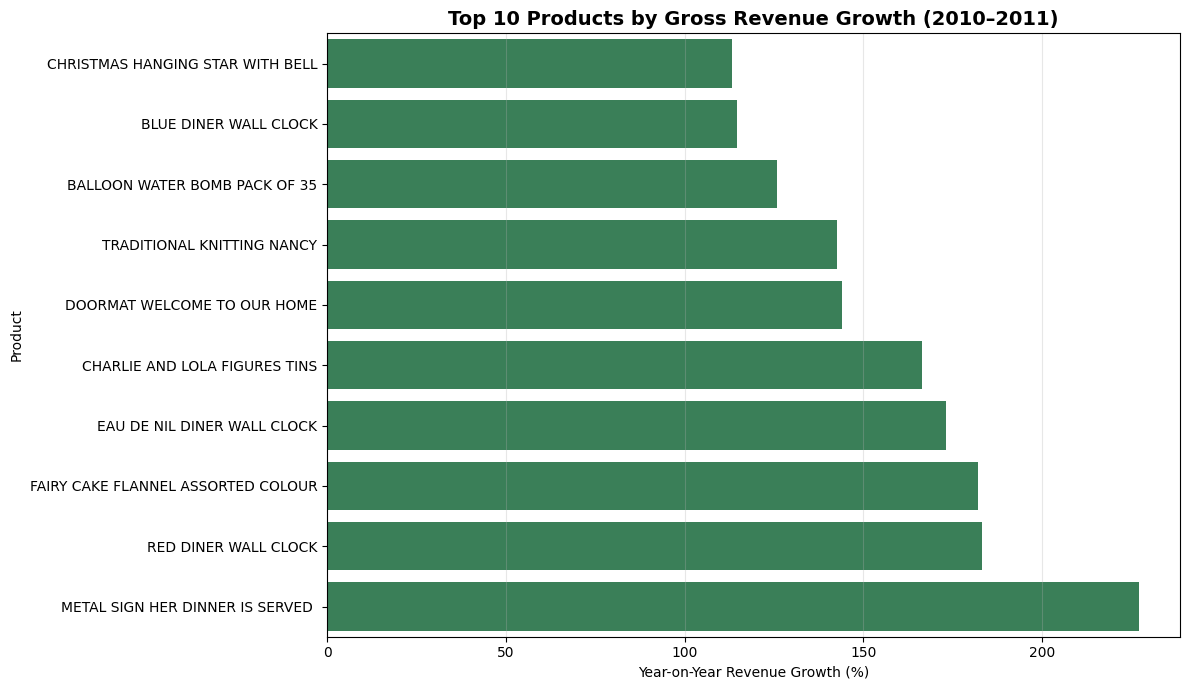

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

growth_chart = top_growth_clean.sort_values(
    "YoY_Growth_%", ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=growth_chart,
    x="YoY_Growth_%",
    y="Description",
    color="seagreen"
)

plt.title(
    "Top 10 Products by Gross Revenue Growth (2010–2011)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year-on-Year Revenue Growth (%)")
plt.ylabel("Product")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../images/top_10_growing_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Chart 2 – Top 10 declining products

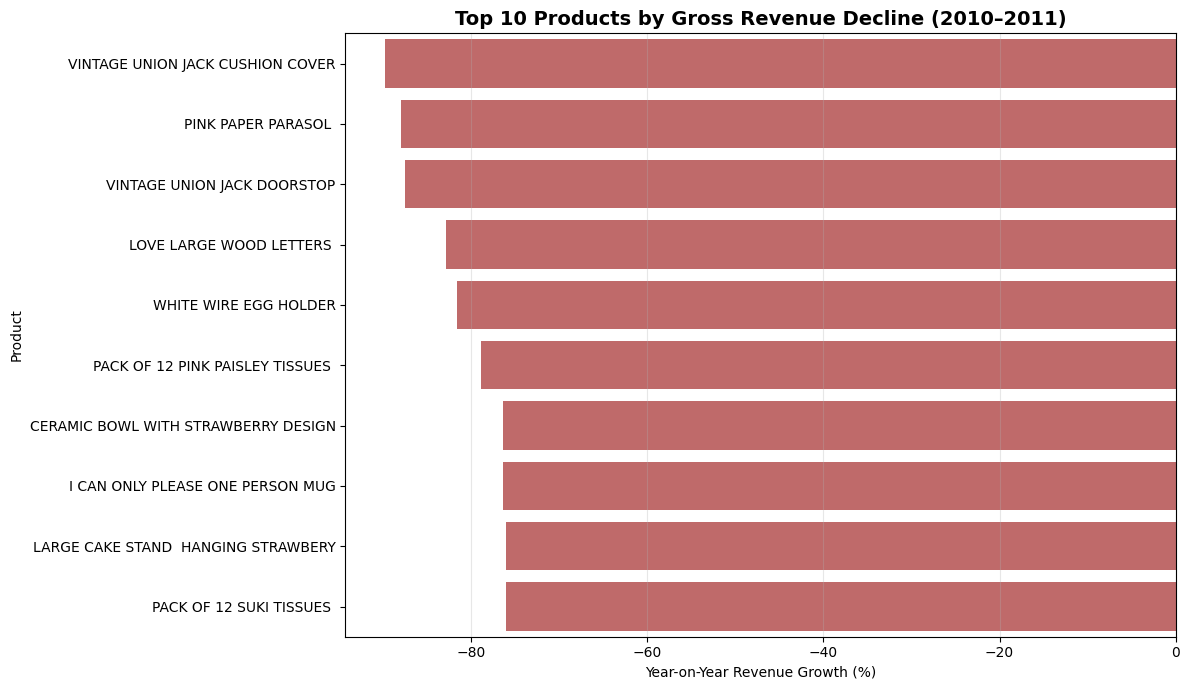

In [108]:
decline_chart = top_decline_clean.sort_values(
    "YoY_Growth_%", ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=decline_chart,
    x="YoY_Growth_%",
    y="Description",
    color="indianred"
)

plt.title(
    "Top 10 Products by Gross Revenue Decline (2010–2011)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year-on-Year Revenue Growth (%)")
plt.ylabel("Product")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../images/top_10_declining_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 1 – Calculate monthly revenue consistency

In [109]:
import pandas as pd
import numpy as np

# Select January–November 2011
monthly_2011 = monthly_product_sales[
    (monthly_product_sales["Month"].dt.year == 2011) &
    (monthly_product_sales["Month"].dt.month <= 11)
].copy()

# Create complete monthly revenue table
monthly_revenue_pivot = monthly_2011.pivot_table(
    index="StockCode_norm",
    columns="Month",
    values="Monthly_Revenue",
    aggfunc="sum",
    fill_value=0
)

# Ensure all 11 months are included
months_2011 = pd.date_range(
    "2011-01-01",
    "2011-11-01",
    freq="MS"
)

monthly_revenue_pivot = monthly_revenue_pivot.reindex(
    columns=months_2011,
    fill_value=0
)

# Calculate consistency metrics
product_consistency = pd.DataFrame({
    "Total_Revenue": monthly_revenue_pivot.sum(axis=1),
    "Average_Monthly_Revenue": monthly_revenue_pivot.mean(axis=1),
    "Monthly_Std": monthly_revenue_pivot.std(axis=1, ddof=0),
    "Active_Months": (monthly_revenue_pivot > 0).sum(axis=1)
})

# Coefficient of variation
product_consistency["CV_%"] = (
    product_consistency["Monthly_Std"] /
    product_consistency["Average_Monthly_Revenue"] * 100
)

# Add product descriptions
product_consistency["Description"] = (
    product_consistency.index.map(product_names)
)

product_consistency = product_consistency.reset_index()

display(product_consistency.head(10))

,StockCode_norm,Total_Revenue,Average_Monthly_Revenue,Monthly_Std,Active_Months,CV_%,Description
0,10002,525.48,47.770909,89.677964,4,187.725052,INFLATABLE POLITICAL GLOBE
1,10080,119.09,10.826364,12.464071,7,115.127028,GROOVY CACTUS INFLATABLE
2,10120,35.70,3.245455,3.419565,8,105.364748,DOGGY RUBBER
3,10123C,2.60,0.236364,0.747447,1,316.227766,HEARTS WRAPPING TAPE
4,10124A,5.04,0.458182,0.769342,3,167.912014,SPOTS ON RED BOOKCOVER TAPE
5,10124G,5.04,0.458182,0.748208,3,163.299316,ARMY CAMO BOOKCOVER TAPE
6,10125,881.03,80.093636,51.264528,10,64.005744,MINI FUNKY DESIGN TAPES
7,10133,1454.33,132.211818,141.214222,9,106.809077,COLOURING PENCILS BROWN TUBE
8,10135,1828.73,166.248182,130.187972,11,78.309411,COLOURING PENCILS BROWN TUBE
9,11001,2205.84,200.530909,160.233466,11,79.904623,ASSTD DESIGN RACING CAR PEN


Step 2 – Identify products with stable revenue

In [110]:
consistent_products = product_consistency[
    (product_consistency["Total_Revenue"] >= 5000) &
    (product_consistency["Active_Months"] >= 10)
].copy()

top_consistent = consistent_products.nsmallest(
    10, "CV_%"
)

print("Products meeting consistency criteria:",
      len(consistent_products))

display(
    top_consistent[
        [
            "StockCode_norm",
            "Description",
            "Total_Revenue",
            "Average_Monthly_Revenue",
            "Active_Months",
            "CV_%"
        ]
    ].round(2)
)

Products meeting consistency criteria: 336


,StockCode_norm,Description,Total_Revenue,Average_Monthly_Revenue,Active_Months,CV_%
1307,22457,NATURAL SLATE HEART CHALKBOARD,23143.34,2103.94,11,17.58
1533,22697,GREEN REGENCY TEACUP AND SAUCER,20125.25,1829.57,11,17.95
1605,22771,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN,8297.85,754.35,11,18.08
1274,22423,REGENCY CAKESTAND 3 TIER,140467.66,12769.79,11,19.09
1335,22488,NATURAL SLATE RECTANGLE CHALKBOARD,5348.75,486.25,11,19.50
1627,22796,PHOTO FRAME 3 CLASSIC HANGING,5276.01,479.64,11,19.92
415,21212,PACK OF 72 RETRO SPOT CAKE CASES,18058.00,1641.64,11,20.19
875,21931,JUMBO STORAGE BAG SUKI,28336.14,2576.01,11,20.21
1306,22456,NATURAL SLATE CHALKBOARD LARGE,8576.17,779.65,11,21.17
165,20725,LUNCH BAG RED SPOTTY,33640.27,3058.21,11,22.00


2. Create a chart of the most consistent products

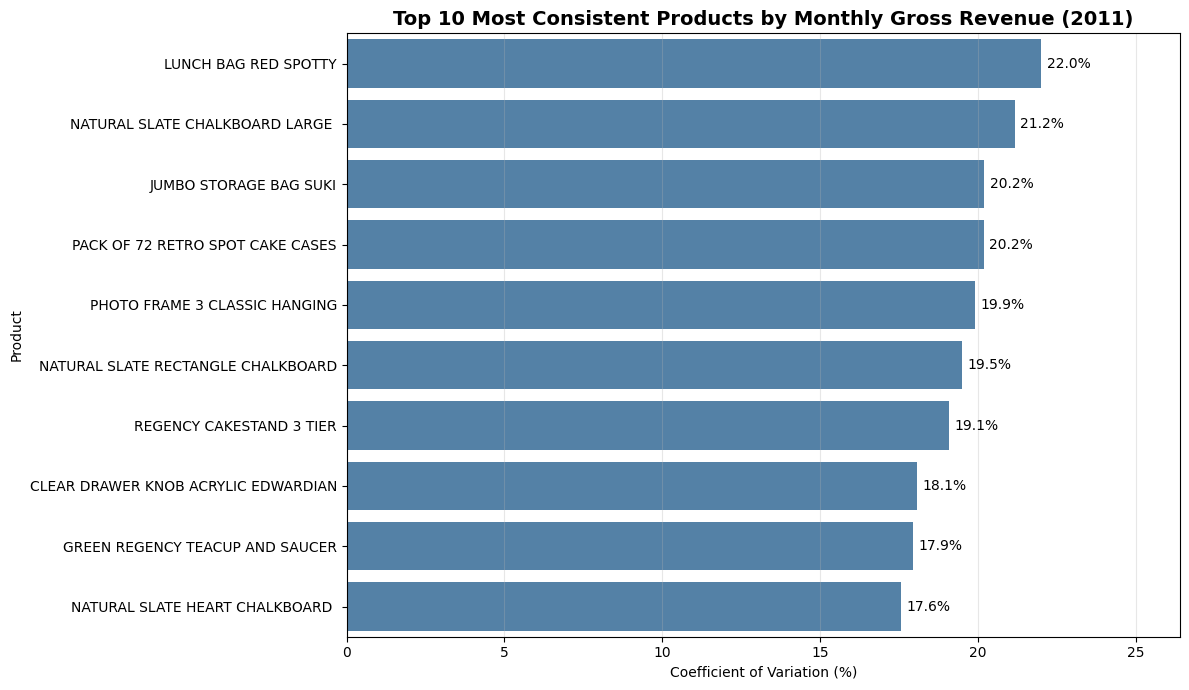

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort products by CV
consistency_chart = top_consistent.sort_values(
    "CV_%", ascending=False
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=consistency_chart,
    x="CV_%",
    y="Description",
    color="steelblue"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4
    )

plt.title(
    "Top 10 Most Consistent Products by Monthly Gross Revenue (2011)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Coefficient of Variation (%)")
plt.ylabel("Product")

plt.xlim(0, consistency_chart["CV_%"].max() * 1.2)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../images/top_10_consistent_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

3. Next: Visualize monthly revenue stability

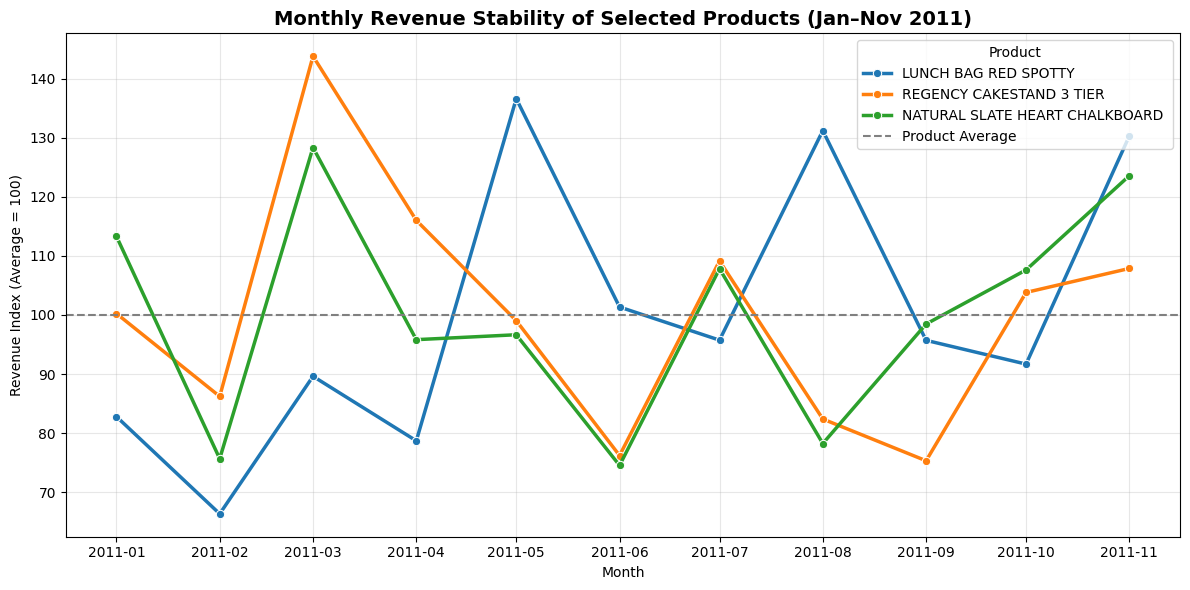

In [112]:
# Select three consistent products
selected_codes = ["22423", "22457", "20725"]

stability_data = monthly_2011[
    monthly_2011["StockCode_norm"].isin(selected_codes)
].copy()

# Add product names
stability_data["Product_Name"] = (
    stability_data["StockCode_norm"].map(product_names)
)

# Calculate average monthly revenue for each product
stability_data["Average_Revenue"] = (
    stability_data.groupby("StockCode_norm")["Monthly_Revenue"]
    .transform("mean")
)

# Normalize monthly revenue
stability_data["Revenue_Index"] = (
    stability_data["Monthly_Revenue"] /
    stability_data["Average_Revenue"] * 100
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=stability_data,
    x="Month",
    y="Revenue_Index",
    hue="Product_Name",
    marker="o",
    linewidth=2.5
)

plt.axhline(
    100,
    color="gray",
    linestyle="--",
    label="Product Average"
)

plt.title(
    "Monthly Revenue Stability of Selected Products (Jan–Nov 2011)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Revenue Index (Average = 100)")

plt.grid(alpha=0.3)
plt.legend(title="Product")

plt.tight_layout()

plt.savefig(
    "../images/monthly_product_revenue_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 1 – Identify high-revenue products with high return rates

In [113]:
# Focus on products with meaningful gross sales
return_risk_products = product_summary[
    (product_summary["Gross_Sales"] >= 10000) &
    (product_summary["Gross_Units"] >= 500)
].copy()

# Calculate sales-value return rate
return_risk_products["Value_Return_Rate_%"] = (
    return_risk_products["Return_Value"] /
    return_risk_products["Gross_Sales"] * 100
)

# Rank by return value
top_return_impact = return_risk_products.nlargest(
    15, "Return_Value"
)

display(
    top_return_impact[
        [
            "StockCode_norm",
            "Description",
            "Gross_Sales",
            "Return_Value",
            "Net_Sales",
            "Value_Return_Rate_%",
            "Unit_Return_Rate"
        ]
    ].round(2)
)

,StockCode_norm,Description,Gross_Sales,Return_Value,Net_Sales,Value_Return_Rate_%,Unit_Return_Rate
2818,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,168469.60,0.00,100.00,100.00
2372,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,77479.64,4221.28,94.83,95.46
1656,22423,REGENCY CAKESTAND 3 TIER,330590.32,16545.30,314045.02,5.00,5.47
4225,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,251781.63,3.59,3.68
3260,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,44680.75,7164.12,37516.63,16.03,16.98
536,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,25407.27,6614.37,18792.90,26.03,24.37
3456,79323W,WHITE CHERRY LIGHTS,18048.72,6421.10,11627.62,35.58,36.22
1163,21843,RETRO SPOT CAKE STAND,64918.30,5270.25,59648.05,8.12,9.58
3541,84078A,SET/4 WHITE RETRO STORAGE CUBES,43844.96,5187.65,38657.31,11.83,13.03
3215,48185,DOOR MAT FAIRY CAKE,45723.84,4678.68,41045.16,10.23,10.14


2. Next: Investigate return frequency

In [114]:
# Select return transactions for products of interest
selected_return_codes = [
    "23843",   # Paper Craft Little Birdie
    "23166",   # Ceramic Storage Jar
    "21108",   # Fairy Cake Flannel
    "79323W",  # White Cherry Lights
    "79323P",  # Pink Cherry Lights
    "22423"    # Regency Cakestand
]

selected_returns = product_df[
    (product_df["StockCode_norm"].isin(selected_return_codes)) &
    (product_df["Quantity"] < 0)
].copy()

# Summarize return frequency and severity
return_frequency = (
    selected_returns
    .groupby("StockCode_norm")
    .agg(
        Return_Records=("Invoice", "size"),
        Return_Invoices=("Invoice", "nunique"),
        Returned_Units=("Quantity", lambda x: -x.sum()),
        Total_Return_Value=("TransactionValue", lambda x: -x.sum()),
        Largest_Single_Return=("TransactionValue", lambda x: -x.min())
    )
    .reset_index()
)

return_frequency["Largest_Return_Share_%"] = (
    return_frequency["Largest_Single_Return"] /
    return_frequency["Total_Return_Value"] * 100
)

return_frequency["Description"] = (
    return_frequency["StockCode_norm"].map(product_names)
)

display(
    return_frequency[
        [
            "StockCode_norm",
            "Description",
            "Return_Records",
            "Return_Invoices",
            "Returned_Units",
            "Total_Return_Value",
            "Largest_Single_Return",
            "Largest_Return_Share_%"
        ]
    ].round(2)
)

,StockCode_norm,Description,Return_Records,Return_Invoices,Returned_Units,Total_Return_Value,Largest_Single_Return,Largest_Return_Share_%
0,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,4,4,3159,6614.37,6539.40,98.87
1,22423,REGENCY CAKESTAND 3 TIER,341,341,1450,16545.30,1642.50,9.93
2,23166,MEDIUM CERAMIC TOP STORAGE JAR,10,10,74494,77479.64,77183.60,99.62
3,23843,"PAPER CRAFT , LITTLE BIRDIE",1,1,80995,168469.60,168469.60,100.00
4,79323P,PINK CHERRY LIGHTS,86,86,693,4021.35,332.45,8.27
5,79323W,WHITE CHERRY LIGHTS,126,124,1088,6421.10,277.95,4.33


2. Next: Investigate cherry lights return patterns

In [115]:
# Focus on cherry lights returns
cherry_returns = selected_returns[
    selected_returns["StockCode_norm"].isin(
        ["79323W", "79323P"]
    )
].copy()

# Extract month
cherry_returns["Month"] = (
    cherry_returns["InvoiceDate"].dt.to_period("M")
)

# Monthly return summary
cherry_monthly_returns = (
    cherry_returns
    .groupby(["Month", "StockCode_norm"])
    .agg(
        Return_Records=("Invoice", "size"),
        Return_Invoices=("Invoice", "nunique"),
        Returned_Units=("Quantity", lambda x: -x.sum()),
        Return_Value=("TransactionValue", lambda x: -x.sum())
    )
    .reset_index()
)

cherry_monthly_returns["Description"] = (
    cherry_monthly_returns["StockCode_norm"]
    .map(product_names)
)

display(cherry_monthly_returns)

,Month,StockCode_norm,Return_Records,Return_Invoices,Returned_Units,Return_Value,Description
0,2009-12,79323P,4,4,6,39.20,PINK CHERRY LIGHTS
1,2009-12,79323W,2,2,2,12.20,WHITE CHERRY LIGHTS
2,2010-01,79323P,4,4,7,39.45,PINK CHERRY LIGHTS
3,2010-01,79323W,3,3,14,77.60,WHITE CHERRY LIGHTS
4,2010-02,79323P,1,1,1,5.95,PINK CHERRY LIGHTS
5,2010-03,79323P,3,3,4,27.00,PINK CHERRY LIGHTS
6,2010-03,79323W,2,2,2,12.20,WHITE CHERRY LIGHTS
7,2010-04,79323P,3,3,42,230.20,PINK CHERRY LIGHTS
8,2010-04,79323W,2,2,37,201.65,WHITE CHERRY LIGHTS
9,2010-05,79323P,43,43,400,2332.00,PINK CHERRY LIGHTS


2. Next step: Compare monthly sales against returns

In [116]:
# Select all cherry lights merchandise transactions
cherry_transactions = product_df[
    product_df["StockCode_norm"].isin(
        ["79323W", "79323P"]
    )
].copy()

# Create month column
cherry_transactions["Month"] = (
    cherry_transactions["InvoiceDate"].dt.to_period("M")
)

# Separate sales and returns
cherry_transactions["Gross_Sales"] = (
    cherry_transactions["TransactionValue"]
    .where(cherry_transactions["Quantity"] > 0, 0)
)

cherry_transactions["Return_Value"] = (
    -cherry_transactions["TransactionValue"]
    .where(cherry_transactions["Quantity"] < 0, 0)
)

# Monthly comparison
cherry_sales_returns = (
    cherry_transactions
    .groupby(["Month", "StockCode_norm"])
    .agg(
        Gross_Sales=("Gross_Sales", "sum"),
        Return_Value=("Return_Value", "sum")
    )
    .reset_index()
)

# Add monthly net sales
cherry_sales_returns["Net_Sales"] = (
    cherry_sales_returns["Gross_Sales"]
    - cherry_sales_returns["Return_Value"]
)

# Focus on the period of unusually high returns
display(
    cherry_sales_returns[
        (cherry_sales_returns["Month"] >= "2010-04") &
        (cherry_sales_returns["Month"] <= "2010-08")
    ].round(2)
)

,Month,StockCode_norm,Gross_Sales,Return_Value,Net_Sales
8,2010-04,79323P,1632.07,230.20,1401.87
9,2010-04,79323W,1022.70,201.65,821.05
10,2010-05,79323P,0.00,2332.00,-2332.00
11,2010-05,79323W,148.50,4226.70,-4078.20
12,2010-06,79323P,0.00,862.70,-862.70
13,2010-06,79323W,148.50,1495.85,-1347.35
14,2010-07,79323P,0.00,259.55,-259.55
15,2010-07,79323W,0.00,120.45,-120.45
16,2010-08,79323P,0.00,130.80,-130.80
17,2010-08,79323W,784.80,182.45,602.35


Step 1 – Check monthly sales quantities before the return spike

In [117]:
# Examine cherry lights sales before May 2010
cherry_early_sales = cherry_transactions[
    (cherry_transactions["Quantity"] > 0) &
    (cherry_transactions["InvoiceDate"] < "2010-05-01")
].copy()

cherry_early_sales["Month"] = (
    cherry_early_sales["InvoiceDate"].dt.to_period("M")
)

early_sales_summary = (
    cherry_early_sales
    .groupby(["Month", "StockCode_norm"])
    .agg(
        Sales_Records=("Invoice", "size"),
        Sales_Invoices=("Invoice", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Gross_Sales=("TransactionValue", "sum")
    )
    .reset_index()
)

display(early_sales_summary)

,Month,StockCode_norm,Sales_Records,Sales_Invoices,Units_Sold,Gross_Sales
0,2009-12,79323P,100,99,808,4956.56
1,2009-12,79323W,116,116,1074,6408.42
2,2010-01,79323P,53,53,307,1972.01
3,2010-01,79323W,65,64,455,2800.17
4,2010-02,79323P,35,35,263,1590.95
5,2010-02,79323W,55,55,409,2458.47
6,2010-03,79323P,56,56,588,3478.54
7,2010-03,79323W,87,87,684,4146.36
8,2010-04,79323P,20,20,287,1632.07
9,2010-04,79323W,23,23,170,1022.70


Step 2 – Compare earlier sales with May–June returns

In [118]:
# Total units sold before May 2010
prior_sales = (
    cherry_early_sales
    .groupby("StockCode_norm")["Quantity"]
    .sum()
    .rename("Units_Sold_Before_May")
)

# Total units returned during May–June 2010
may_june_returns = cherry_transactions[
    (cherry_transactions["Quantity"] < 0) &
    (cherry_transactions["InvoiceDate"] >= "2010-05-01") &
    (cherry_transactions["InvoiceDate"] < "2010-07-01")
].copy()

returned_units = (
    may_june_returns
    .groupby("StockCode_norm")["Quantity"]
    .sum()
    .mul(-1)
    .rename("Units_Returned_May_June")
)

# Compare quantities
cherry_quantity_comparison = pd.concat(
    [prior_sales, returned_units],
    axis=1
).fillna(0)

display(cherry_quantity_comparison)

,Units_Sold_Before_May,Units_Returned_May_June
StockCode_norm,,
79323P,2253,550
79323W,2792,967


2. Next step: Investigate whether returns were concentrated among a few customers

In [119]:
# Examine customer concentration during May–June 2010
cherry_customer_returns = may_june_returns.copy()

customer_return_summary = (
    cherry_customer_returns
    .groupby(
        ["StockCode_norm", "Customer ID"],
        dropna=False
    )
    .agg(
        Return_Records=("Invoice", "size"),
        Return_Invoices=("Invoice", "nunique"),
        Returned_Units=("Quantity", lambda x: -x.sum()),
        Return_Value=("TransactionValue", lambda x: -x.sum())
    )
    .reset_index()
)

# Top customers by returned value
top_return_customers = (
    customer_return_summary
    .sort_values(
        ["StockCode_norm", "Return_Value"],
        ascending=[True, False]
    )
    .groupby("StockCode_norm")
    .head(10)
)

display(top_return_customers)

,StockCode_norm,Customer ID,Return_Records,Return_Invoices,Returned_Units,Return_Value
24,79323P,15270.0,2,2,83,452.35
7,79323P,13694.0,1,1,61,332.45
13,79323P,14258.0,1,1,48,261.60
54,79323P,17850.0,1,1,36,196.20
49,79323P,17511.0,1,1,34,185.30
8,79323P,13799.0,1,1,32,174.40
38,79323P,16705.0,1,1,24,130.80
30,79323P,16067.0,2,2,22,119.90
20,79323P,14970.0,2,2,17,92.65
14,79323P,14430.0,1,1,12,81.00


2. Next step: Identify customers who returned both products

In [120]:
# Identify customers who returned both cherry lights products
customer_product_returns = (
    may_june_returns
    .dropna(subset=["Customer ID"])
    .groupby("Customer ID")["StockCode_norm"]
    .nunique()
)

# Customers who returned both products
customers_both = customer_product_returns[
    customer_product_returns == 2
].index

print(
    "Customers who returned both products:",
    len(customers_both)
)

# Total unique returning customers
total_customers = may_june_returns[
    "Customer ID"
].nunique()

print(
    "Total unique returning customers:",
    total_customers
)

print(
    "Percentage returning both products:",
    round(len(customers_both) / total_customers * 100, 2)
    if total_customers else 0
)

# Display transactions for customers returning both
both_product_returns = may_june_returns[
    may_june_returns["Customer ID"].isin(customers_both)
].copy()

display(
    both_product_returns[
        [
            "Customer ID",
            "Invoice",
            "StockCode_norm",
            "Quantity",
            "InvoiceDate",
            "TransactionValue"
        ]
    ].sort_values(
        ["Customer ID", "InvoiceDate"]
    ).head(30)
)

Customers who returned both products: 44
Total unique returning customers: 104
Percentage returning both products: 42.31


,Customer ID,Invoice,StockCode_norm,Quantity,InvoiceDate,TransactionValue
191215,12921.0,C507454,79323P,-8,2010-05-10 10:19:00,-54.00
191216,12921.0,C507454,79323W,-8,2010-05-10 10:19:00,-54.00
191255,12921.0,C507456,79323W,-9,2010-05-10 10:24:00,-60.75
198056,12989.0,C508459,79323P,-13,2010-05-14 17:23:00,-70.85
198057,12989.0,C508459,79323W,-49,2010-05-14 17:23:00,-267.05
197873,13081.0,C508414,79323P,-2,2010-05-14 16:10:00,-13.50
197874,13081.0,C508414,79323W,-7,2010-05-14 16:10:00,-47.25
252331,13089.0,C513745,79323W,-2,2010-06-28 12:24:00,-13.50
252332,13089.0,C513745,79323P,-5,2010-06-28 12:24:00,-33.75
200944,13327.0,C508695,79323P,-7,2010-05-17 17:01:00,-47.25


2. Next investigation: How many cancellation invoices contained both products?

In [121]:
# Count distinct cherry lights products per cancellation invoice
invoice_product_counts = (
    may_june_returns
    .groupby("Invoice")["StockCode_norm"]
    .nunique()
)

# Identify invoices containing both products
joint_return_invoices = invoice_product_counts[
    invoice_product_counts == 2
].index

print(
    "Cancellation invoices containing both products:",
    len(joint_return_invoices)
)

print(
    "Total unique cherry lights cancellation invoices:",
    may_june_returns["Invoice"].nunique()
)

# Examine transactions on joint return invoices
joint_returns = may_june_returns[
    may_june_returns["Invoice"].isin(joint_return_invoices)
].copy()

joint_summary = (
    joint_returns
    .groupby("StockCode_norm")
    .agg(
        Return_Records=("Invoice", "size"),
        Returned_Units=("Quantity", lambda x: -x.sum()),
        Return_Value=("TransactionValue", lambda x: -x.sum())
    )
    .reset_index()
)

display(joint_summary)

Cancellation invoices containing both products: 43
Total unique cherry lights cancellation invoices: 116


,StockCode_norm,Return_Records,Returned_Units,Return_Value
0,79323P,43,446,2587.60
1,79323W,43,429,2539.55


Step 1 — Create a consolidated product performance table

In [122]:
# Select revenue and return metrics
revenue_metrics = product_summary[
    [
        "StockCode_norm",
        "Description",
        "Gross_Sales",
        "Return_Value",
        "Net_Sales",
        "Gross_Units",
        "Returned_Units"
    ]
].copy()

# Calculate value return rate
revenue_metrics["Value_Return_Rate_%"] = (
    revenue_metrics["Return_Value"]
    / revenue_metrics["Gross_Sales"]
    * 100
)

# Select sales consistency metrics
consistency_metrics = product_consistency[
    [
        "StockCode_norm",
        "CV_%"
    ]
].copy()

# Combine product metrics
product_scorecard = revenue_metrics.merge(
    consistency_metrics,
    on="StockCode_norm",
    how="left",
    validate="one_to_one"
)

print("Total products:", len(product_scorecard))

display(product_scorecard.head(10))

Total products: 4816


,StockCode_norm,Description,Gross_Sales,Return_Value,Net_Sales,Gross_Units,Returned_Units,Value_Return_Rate_%,CV_%
0,22423,REGENCY CAKESTAND 3 TIER,330590.32,16545.30,314045.02,26495,1450,5.004774,19.085863
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,251781.63,98724,3637,3.594266,43.458513
2,85099B,JUMBO BAG RED WHITE SPOTTY,182680.98,2168.82,180512.16,97183,1213,1.187217,29.243641
3,47566,PARTY BUNTING,148318.28,1238.55,147079.73,28248,285,0.835062,55.913675
4,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,774.07,128550.42,80090,511,0.598549,46.498461
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,1461.70,116298.59,35113,590,1.241250,187.633372
6,79321,CHILLI LIGHTS,80540.88,635.75,79905.13,15988,145,0.789351,68.870983
7,22197,"POPCORN HOLDER , SMALL",79520.20,616.58,78903.62,88993,804,0.775375,88.775382
8,22386,JUMBO BAG PINK WITH WHITE SPOTS,76324.62,866.98,75457.64,39437,482,1.135911,39.871478
9,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,71300.40,330.45,70969.95,31522,9381,0.463462,184.295605


Step 2 — Identify high-revenue products with relatively low return rates

In [123]:
# High-revenue products with relatively low returns
strong_revenue_products = product_scorecard[
    (product_scorecard["Net_Sales"] >= 20000) &
    (product_scorecard["Value_Return_Rate_%"] <= 5)
].copy()

# Sort by net sales
strong_revenue_products = strong_revenue_products.sort_values(
    "Net_Sales",
    ascending=False
)

print(
    "Products meeting the criteria:",
    len(strong_revenue_products)
)

display(
    strong_revenue_products[
        [
            "StockCode_norm",
            "Description",
            "Gross_Sales",
            "Return_Value",
            "Net_Sales",
            "Value_Return_Rate_%",
            "CV_%"
        ]
    ].head(15).round(2)
)

Products meeting the criteria: 182


,StockCode_norm,Description,Gross_Sales,Return_Value,Net_Sales,Value_Return_Rate_%,CV_%
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,261168.73,9387.10,251781.63,3.59,43.46
2,85099B,JUMBO BAG RED WHITE SPOTTY,182680.98,2168.82,180512.16,1.19,29.24
3,47566,PARTY BUNTING,148318.28,1238.55,147079.73,0.84,55.91
4,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,774.07,128550.42,0.60,46.50
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,1461.70,116298.59,1.24,187.63
6,79321,CHILLI LIGHTS,80540.88,635.75,79905.13,0.79,68.87
7,22197,"POPCORN HOLDER , SMALL",79520.20,616.58,78903.62,0.78,88.78
8,22386,JUMBO BAG PINK WITH WHITE SPOTS,76324.62,866.98,75457.64,1.14,39.87
9,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,71300.40,330.45,70969.95,0.46,184.30
10,20725,LUNCH BAG RED SPOTTY,71106.29,1383.75,69722.54,1.95,22.00


2. Next step — Identify high-value, stable, low-return products

In [124]:
# Exclude the previously identified problematic product code
scorecard_clean = product_scorecard[
    product_scorecard["StockCode_norm"] != "22502"
].copy()

# Identify products with strong revenue,
# low returns, and relatively stable sales
priority_products = scorecard_clean[
    (scorecard_clean["Net_Sales"] >= 20000) &
    (scorecard_clean["Value_Return_Rate_%"] <= 5) &
    (scorecard_clean["CV_%"] <= 30)
].copy()

priority_products = priority_products.sort_values(
    "Net_Sales",
    ascending=False
)

print("Priority products:", len(priority_products))

display(
    priority_products[
        [
            "StockCode_norm",
            "Description",
            "Net_Sales",
            "Value_Return_Rate_%",
            "CV_%"
        ]
    ].round(2)
)

Priority products: 22


,StockCode_norm,Description,Net_Sales,Value_Return_Rate_%,CV_%
2,85099B,JUMBO BAG RED WHITE SPOTTY,180512.16,1.19,29.24
10,20725,LUNCH BAG RED SPOTTY,69722.54,1.95,22.00
16,21931,JUMBO STORAGE BAG SUKI,60826.92,1.15,20.21
21,85099C,JUMBO BAG BAROQUE BLACK WHITE,58571.90,0.97,29.46
26,82484,WOOD BLACK BOARD ANT WHITE FINISH,56420.73,0.57,23.33
29,21212,PACK OF 72 RETRO SPOT CAKE CASES,51275.49,1.06,20.19
43,22457,NATURAL SLATE HEART CHALKBOARD,46972.28,0.67,17.58
46,21754,HOME BUILDING BLOCK WORD,46285.34,0.50,26.56
52,22326,"ROUND SNACK BOXES ,SET4, WOODLAND",44089.59,0.38,29.33
62,82482,WOODEN PICTURE FRAME WHITE FINISH,40769.45,2.55,29.86


3. Next step — Investigate StockCode 22960

In [125]:
# Investigate product descriptions for StockCode 22960
product_22960 = product_df[
    product_df["StockCode_norm"] == "22960"
].copy()

print("Total records:", len(product_22960))

print("\nProduct descriptions:")
display(
    product_22960["Description"]
    .value_counts(dropna=False)
)

print("\nPrice distribution:")
display(
    product_22960.groupby(
        ["Description", "Price"],
        dropna=False
    )
    .agg(
        Records=("Invoice", "size"),
        Units=("Quantity", "sum"),
        Transaction_Value=("TransactionValue", "sum")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
    .head(20)
)

Total records: 1249

Product descriptions:


Description
JAM MAKING SET WITH JARS    1248
mailout addition               1
Name: count, dtype: int64


Price distribution:


,Description,Price,Records,Units,Transaction_Value
4,JAM MAKING SET WITH JARS,4.25,764,3303,14037.75
6,JAM MAKING SET WITH JARS,8.29,224,436,3614.44
3,JAM MAKING SET WITH JARS,3.75,220,4342,16282.50
7,JAM MAKING SET WITH JARS,8.47,32,90,762.30
5,JAM MAKING SET WITH JARS,4.60,4,446,2051.60
0,JAM MAKING SET WITH JARS,0.00,1,11,0.00
1,JAM MAKING SET WITH JARS,2.95,1,84,247.80
2,JAM MAKING SET WITH JARS,2.96,1,48,142.08
8,JAM MAKING SET WITH JARS,9.95,1,23,228.85
9,mailout addition,0.00,1,100,0.00


2. Correct the product description in your scorecard

In [126]:
# Correct the display description for StockCode 22960
product_scorecard.loc[
    product_scorecard["StockCode_norm"] == "22960",
    "Description"
] = "JAM MAKING SET WITH JARS"

# Update the existing priority shortlist
priority_products.loc[
    priority_products["StockCode_norm"] == "22960",
    "Description"
] = "JAM MAKING SET WITH JARS"

# Verify correction
display(
    priority_products[
        priority_products["StockCode_norm"] == "22960"
    ][
        [
            "StockCode_norm",
            "Description",
            "Net_Sales",
            "Value_Return_Rate_%",
            "CV_%"
        ]
    ]
)

,StockCode_norm,Description,Net_Sales,Value_Return_Rate_%,CV_%
72,22960,JAM MAKING SET WITH JARS,37367.32,2.638841,28.790692


3. Next step — Visualize the priority products

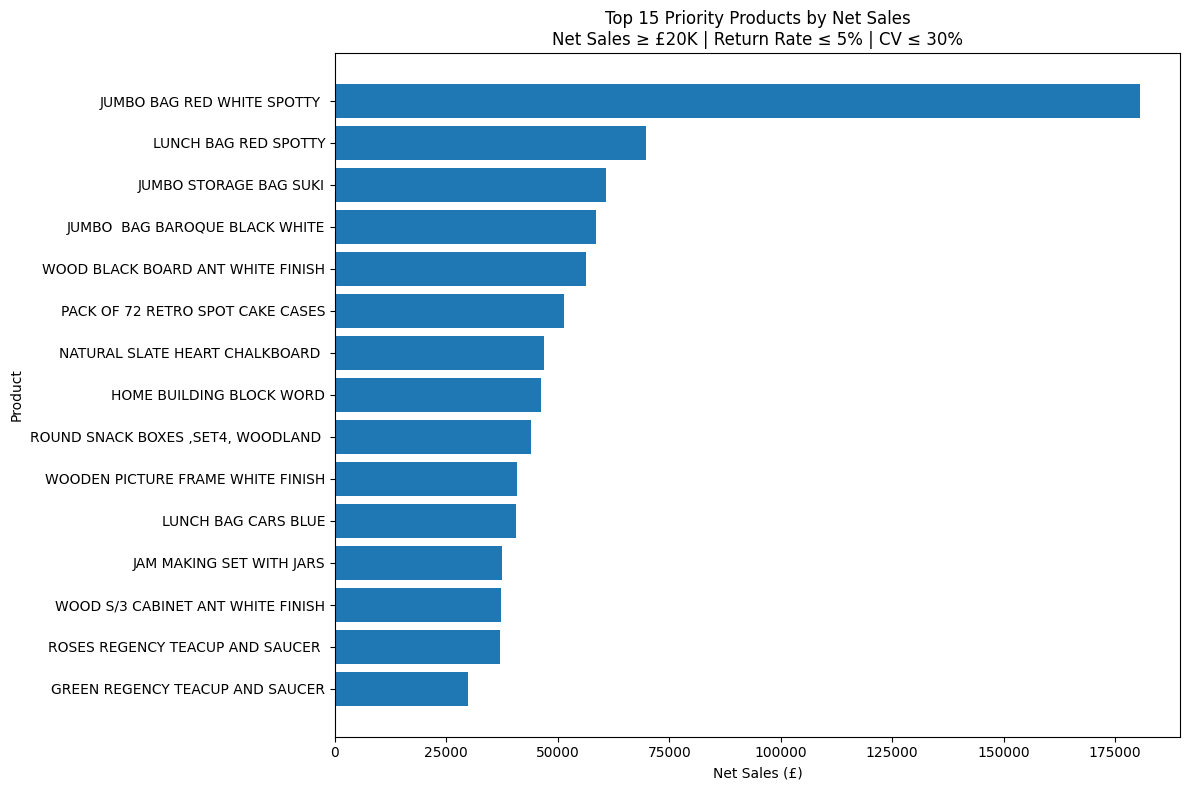

In [127]:
import matplotlib.pyplot as plt

top_priority = priority_products.nlargest(
    15, "Net_Sales"
).sort_values("Net_Sales")

plt.figure(figsize=(12, 8))

plt.barh(
    top_priority["Description"],
    top_priority["Net_Sales"]
)

plt.xlabel("Net Sales (£)")
plt.ylabel("Product")
plt.title(
    "Top 15 Priority Products by Net Sales\n"
    "Net Sales ≥ £20K | Return Rate ≤ 5% | CV ≤ 30%"
)

plt.tight_layout()

plt.savefig(
    "../images/top_15_priority_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 4 — Create a product performance scatter plot

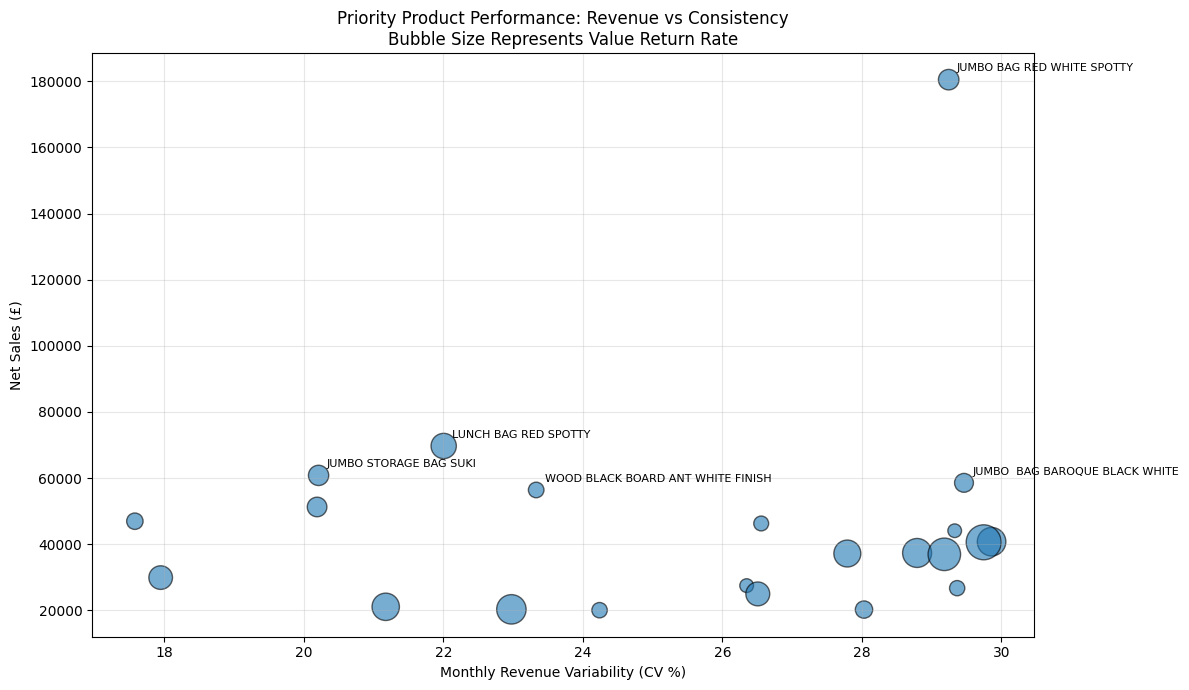

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    priority_products["CV_%"],
    priority_products["Net_Sales"],
    s=priority_products["Value_Return_Rate_%"] * 150 + 40,
    alpha=0.6,
    edgecolors="black"
)

# Label the top 5 products by net sales
top_5 = priority_products.nlargest(5, "Net_Sales")

for _, row in top_5.iterrows():
    plt.annotate(
        row["Description"],
        (row["CV_%"], row["Net_Sales"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Monthly Revenue Variability (CV %)")
plt.ylabel("Net Sales (£)")
plt.title(
    "Priority Product Performance: Revenue vs Consistency\n"
    "Bubble Size Represents Value Return Rate"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../images/priority_product_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

2. Next step — Segment the 22 priority products

In [129]:
import numpy as np

priority_products["Segment"] = np.select(
    [
        priority_products["Net_Sales"] >= 50000,
        priority_products["CV_%"] <= 22
    ],
    [
        "Revenue Leaders",
        "Consistency Leaders"
    ],
    default="Other Priority Products"
)

segment_summary = (
    priority_products
    .groupby("Segment")
    .agg(
        Product_Count=("StockCode_norm", "nunique"),
        Total_Net_Sales=("Net_Sales", "sum"),
        Average_Return_Rate=("Value_Return_Rate_%", "mean"),
        Average_CV=("CV_%", "mean")
    )
    .reset_index()
)

display(segment_summary.round(2))

,Segment,Product_Count,Total_Net_Sales,Average_Return_Rate,Average_CV
0,Consistency Leaders,3,97972.23,1.55,18.90
1,Other Priority Products,13,423069.28,1.72,27.59
2,Revenue Leaders,6,477329.74,1.15,24.07


2. Next step — Identify products in each segment

In [130]:
# Display products grouped by segment
segment_details = priority_products[
    [
        "Segment",
        "StockCode_norm",
        "Description",
        "Net_Sales",
        "Value_Return_Rate_%",
        "CV_%"
    ]
].sort_values(
    ["Segment", "Net_Sales"],
    ascending=[True, False]
)

for segment in [
    "Revenue Leaders",
    "Consistency Leaders",
    "Other Priority Products"
]:
    print(f"\n{segment}")

    display(
        segment_details[
            segment_details["Segment"] == segment
        ].round(2)
    )


Revenue Leaders


,Segment,StockCode_norm,Description,Net_Sales,Value_Return_Rate_%,CV_%
2,Revenue Leaders,85099B,JUMBO BAG RED WHITE SPOTTY,180512.16,1.19,29.24
10,Revenue Leaders,20725,LUNCH BAG RED SPOTTY,69722.54,1.95,22.00
16,Revenue Leaders,21931,JUMBO STORAGE BAG SUKI,60826.92,1.15,20.21
21,Revenue Leaders,85099C,JUMBO BAG BAROQUE BLACK WHITE,58571.90,0.97,29.46
26,Revenue Leaders,82484,WOOD BLACK BOARD ANT WHITE FINISH,56420.73,0.57,23.33
29,Revenue Leaders,21212,PACK OF 72 RETRO SPOT CAKE CASES,51275.49,1.06,20.19



Consistency Leaders


,Segment,StockCode_norm,Description,Net_Sales,Value_Return_Rate_%,CV_%
43,Consistency Leaders,22457,NATURAL SLATE HEART CHALKBOARD,46972.28,0.67,17.58
102,Consistency Leaders,22697,GREEN REGENCY TEACUP AND SAUCER,29918.25,1.67,17.95
186,Consistency Leaders,22456,NATURAL SLATE CHALKBOARD LARGE,21081.70,2.32,21.17



Other Priority Products


,Segment,StockCode_norm,Description,Net_Sales,Value_Return_Rate_%,CV_%
46,Other Priority Products,21754,HOME BUILDING BLOCK WORD,46285.34,0.50,26.56
52,Other Priority Products,22326,"ROUND SNACK BOXES ,SET4, WOODLAND",44089.59,0.38,29.33
62,Other Priority Products,82482,WOODEN PICTURE FRAME WHITE FINISH,40769.45,2.55,29.86
63,Other Priority Products,20728,LUNCH BAG CARS BLUE,40592.30,3.97,29.75
72,Other Priority Products,22960,JAM MAKING SET WITH JARS,37367.32,2.64,28.79
74,Other Priority Products,82486,WOOD S/3 CABINET ANT WHITE FINISH,37197.18,2.25,27.79
78,Other Priority Products,22699,ROSES REGENCY TEACUP AND SAUCER,36954.25,3.39,29.18
120,Other Priority Products,20719,WOODLAND CHARLOTTE BAG,27491.60,0.39,26.35
128,Other Priority Products,20750,RED/WHITE DOT MINI CASES,26722.03,0.54,29.37
141,Other Priority Products,21080,SET/20 RED SPOTTY PAPER NAPKINS,24983.26,1.71,26.51


3. Final validation before completing this section

In [131]:
# Validate the final segmentation
print("Total priority products:", len(priority_products))

print(
    "Unique product codes:",
    priority_products["StockCode_norm"].nunique()
)

print(
    "Combined net sales:",
    round(priority_products["Net_Sales"].sum(), 2)
)

print(
    "\nProducts by segment:"
)
print(priority_products["Segment"].value_counts())

print(
    "\nCheck screening criteria:"
)
print(
    "All products meet thresholds:",
    (
        (priority_products["Net_Sales"] >= 20000) &
        (priority_products["Value_Return_Rate_%"] <= 5) &
        (priority_products["CV_%"] <= 30)
    ).all()
)

Total priority products: 22
Unique product codes: 22
Combined net sales: 998371.25

Products by segment:
Segment
Other Priority Products    13
Revenue Leaders             6
Consistency Leaders         3
Name: count, dtype: int64

Check screening criteria:
All products meet thresholds: True


Next milestone: Customer Behaviour Analysis


Step 1 — Assess customer data coverage

In [132]:
# Customer data coverage for merchandise transactions

customer_coverage = pd.DataFrame({
    "Metric": [
        "Total Product Records",
        "Records With Customer ID",
        "Records Without Customer ID",
        "Unique Identified Customers",
        "Sales Records With Customer ID",
        "Return Records With Customer ID"
    ],
    "Value": [
        len(product_df),
        product_df["Customer ID"].notna().sum(),
        product_df["Customer ID"].isna().sum(),
        product_df["Customer ID"].nunique(),
        (
            (product_df["Quantity"] > 0) &
            product_df["Customer ID"].notna()
        ).sum(),
        (
            (product_df["Quantity"] < 0) &
            product_df["Customer ID"].notna()
        ).sum()
    ]
})

display(customer_coverage)

print(
    "Customer ID coverage:",
    round(
        product_df["Customer ID"].notna().mean() * 100,
        2
    ),
    "%"
)

,Metric,Value
0,Total Product Records,1023906
1,Records With Customer ID,794199
2,Records Without Customer ID,229707
3,Unique Identified Customers,5878
4,Sales Records With Customer ID,776593
5,Return Records With Customer ID,17606


Customer ID coverage: 77.57 %


2. Next step — Create the customer sales dataset

In [133]:
# Create customer sales dataset
customer_sales = product_df[
    (product_df["Customer ID"].notna()) &
    (product_df["Quantity"] > 0)
].copy()

# Standardize customer IDs
customer_sales["Customer_ID"] = (
    customer_sales["Customer ID"]
    .astype("Int64")
    .astype(str)
)

print("Customer sales records:", len(customer_sales))

print(
    "Unique customers:",
    customer_sales["Customer_ID"].nunique()
)

print(
    "Unique sales invoices:",
    customer_sales["Invoice"].nunique()
)

print(
    "Total identified customer gross sales:",
    round(customer_sales["TransactionValue"].sum(), 2)
)

Customer sales records: 776593
Unique customers: 5855
Unique sales invoices: 36612
Total identified customer gross sales: 17068339.79


2. Next step — Analyze customer purchase frequency

In [134]:
# Calculate purchase frequency per customer
customer_frequency = (
    customer_sales
    .groupby("Customer_ID")
    .agg(
        Purchase_Count=("Invoice", "nunique"),
        Total_Gross_Sales=("TransactionValue", "sum"),
        Total_Units=("Quantity", "sum"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .reset_index()
)

# Classify customers
customer_frequency["Customer_Type"] = np.where(
    customer_frequency["Purchase_Count"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

# Summarize customer types
customer_type_summary = (
    customer_frequency
    .groupby("Customer_Type")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Gross_Sales=("Total_Gross_Sales", "sum"),
        Average_Purchases=("Purchase_Count", "mean")
    )
    .reset_index()
)

customer_type_summary["Customer_Share_%"] = (
    customer_type_summary["Customers"]
    / customer_frequency["Customer_ID"].nunique()
    * 100
)

customer_type_summary["Revenue_Share_%"] = (
    customer_type_summary["Gross_Sales"]
    / customer_frequency["Total_Gross_Sales"].sum()
    * 100
)

display(customer_type_summary.round(2))

,Customer_Type,Customers,Gross_Sales,Average_Purchases,Customer_Share_%,Revenue_Share_%
0,One-Time Customer,1621,555969.97,1.00,27.69,3.26
1,Repeat Customer,4234,16512369.82,8.26,72.31,96.74


2. Next step — Analyze customer revenue concentration

In [135]:
import numpy as np
import pandas as pd

# Rank customers by gross merchandise sales
customer_revenue_ranked = (
    customer_frequency
    .sort_values("Total_Gross_Sales", ascending=False)
    .reset_index(drop=True)
)

total_customers = len(customer_revenue_ranked)
total_revenue = customer_revenue_ranked["Total_Gross_Sales"].sum()

# Calculate revenue concentration
concentration_results = []

for pct in [1, 5, 10, 20]:
    n_customers = int(np.ceil(total_customers * pct / 100))

    top_revenue = (
        customer_revenue_ranked
        .head(n_customers)["Total_Gross_Sales"]
        .sum()
    )

    concentration_results.append({
        "Top_Customer_%": pct,
        "Customer_Count": n_customers,
        "Gross_Sales": top_revenue,
        "Revenue_Share_%": top_revenue / total_revenue * 100
    })

customer_concentration = pd.DataFrame(concentration_results)

display(customer_concentration.round(2))

,Top_Customer_%,Customer_Count,Gross_Sales,Revenue_Share_%
0,1,59,5476988.79,32.09
1,5,293,8872790.91,51.98
2,10,586,10905820.25,63.90
3,20,1171,13172001.53,77.17


2. Next step — Investigate the top 10 highest-spending customers

In [136]:
# Identify the 10 highest-spending customers
top_10_customers = (
    customer_frequency
    .nlargest(10, "Total_Gross_Sales")
    .copy()
)

# Calculate average gross sales per invoice
top_10_customers["Avg_Invoice_Value"] = (
    top_10_customers["Total_Gross_Sales"]
    / top_10_customers["Purchase_Count"]
)

# Calculate observed purchasing period
top_10_customers["Customer_Active_Days"] = (
    top_10_customers["Last_Purchase"]
    - top_10_customers["First_Purchase"]
).dt.days

display(
    top_10_customers[
        [
            "Customer_ID",
            "Purchase_Count",
            "Total_Gross_Sales",
            "Avg_Invoice_Value",
            "Total_Units",
            "Customer_Active_Days"
        ]
    ].round(2)
)

,Customer_ID,Purchase_Count,Total_Gross_Sales,Avg_Invoice_Value,Total_Units,Customer_Active_Days
5669,18102,145,580987.04,4006.81,181645,738
2264,14646,146,526751.52,3607.89,367712,735
1780,14156,144,303069.88,2104.65,164281,728
2523,14911,373,272252.79,729.90,148054,737
5029,17450,51,244784.25,4799.69,84562,429
1322,13694,143,195640.69,1368.12,188201,731
5088,17511,60,172132.87,2868.88,117174,734
4040,16446,2,168472.50,84236.25,80997,204
4274,16684,55,147142.77,2675.32,104810,728
67,12415,24,144033.37,6001.39,91739,503


2. Next step — Investigate Customer 16446

In [137]:
# Investigate all merchandise transactions for Customer 16446

customer_16446 = product_df[
    product_df["Customer ID"] == 16446
].copy()

display(
    customer_16446[
        [
            "Invoice",
            "InvoiceDate",
            "StockCode_norm",
            "Description",
            "Quantity",
            "Price",
            "TransactionValue"
        ]
    ].sort_values("InvoiceDate")
)

print(
    "Gross Sales:",
    round(
        customer_16446.loc[
            customer_16446["Quantity"] > 0,
            "TransactionValue"
        ].sum(), 2
    )
)

print(
    "Return Value:",
    round(
        -customer_16446.loc[
            customer_16446["Quantity"] < 0,
            "TransactionValue"
        ].sum(), 2
    )
)

print(
    "Net Sales:",
    round(
        customer_16446["TransactionValue"].sum(), 2
    )
)

,Invoice,InvoiceDate,StockCode_norm,Description,Quantity,Price,TransactionValue
371780,C525275,2010-10-04 16:38:00,TEST001,This is a test product.,-2,4.50,-9.00
719815,553573,2011-05-18 09:52:00,22980,PANTRY SCRUBBING BRUSH,1,1.65,1.65
719816,553573,2011-05-18 09:52:00,22982,PANTRY PASTRY BRUSH,1,1.25,1.25
1065882,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
1065883,C581484,2011-12-09 09:27:00,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60


Gross Sales: 168472.5
Return Value: 168478.6
Net Sales: -6.1


2. Next step — Calculate net revenue for all customers

In [138]:
# Keep merchandise transactions with identified customers
customer_transactions = product_df[
    product_df["Customer ID"].notna()
].copy()

customer_transactions["Customer_ID"] = (
    customer_transactions["Customer ID"]
    .astype("Int64")
    .astype(str)
)

# Separate positive sales and return values
customer_transactions["Gross_Sales"] = np.where(
    customer_transactions["Quantity"] > 0,
    customer_transactions["TransactionValue"],
    0
)

customer_transactions["Return_Value"] = np.where(
    customer_transactions["Quantity"] < 0,
    -customer_transactions["TransactionValue"],
    0
)

# Aggregate by customer
customer_net_summary = (
    customer_transactions
    .groupby("Customer_ID")
    .agg(
        Gross_Sales=("Gross_Sales", "sum"),
        Return_Value=("Return_Value", "sum"),
        Net_Sales=("TransactionValue", "sum"),
        Sales_Invoices=(
            "Invoice",
            lambda x: x[
                customer_transactions.loc[x.index, "Quantity"] > 0
            ].nunique()
        )
    )
    .reset_index()
)

# Calculate customer-level return rate
customer_net_summary["Return_Rate_%"] = np.where(
    customer_net_summary["Gross_Sales"] > 0,
    customer_net_summary["Return_Value"]
    / customer_net_summary["Gross_Sales"] * 100,
    np.nan
)

print("Customers analyzed:", len(customer_net_summary))

print(
    "Total identified customer net sales:",
    round(customer_net_summary["Net_Sales"].sum(), 2)
)

print("\nTop 10 customers by NET sales:")

display(
    customer_net_summary
    .nlargest(10, "Net_Sales")
    .round(2)
)

print("\nCustomer 16446 verification:")

display(
    customer_net_summary[
        customer_net_summary["Customer_ID"] == "16446"
    ].round(2)
)

Customers analyzed: 5878
Total identified customer net sales: 16350408.83

Top 10 customers by NET sales:


,Customer_ID,Gross_Sales,Return_Value,Net_Sales,Sales_Invoices,Return_Rate_%
5692,18102,580987.04,2578.40,578408.64,145,0.44
2270,14646,526751.52,3548.78,523202.74,146,0.67
1785,14156,303069.88,5294.87,297775.01,144,1.75
2531,14911,272252.79,13730.36,258522.43,373,5.04
5046,17450,244784.25,11140.34,233643.91,51,4.55
1325,13694,195640.69,5249.19,190391.50,143,2.68
5106,17511,172132.87,3628.43,168504.44,60,2.11
67,12415,144033.37,926.35,143107.02,24,0.64
4289,16684,147142.77,5612.48,141530.29,55,3.81
2680,15061,126387.57,1405.44,124982.13,127,1.11



Customer 16446 verification:


,Customer_ID,Gross_Sales,Return_Value,Net_Sales,Sales_Invoices,Return_Rate_%
4053,16446,168472.5,168478.6,-6.1,2,100.0


2. Next step — Recalculate customer revenue concentration using net sales

In [139]:
# Identify customers with positive net merchandise sales
positive_net_customers = (
    customer_net_summary[
        customer_net_summary["Net_Sales"] > 0
    ]
    .sort_values("Net_Sales", ascending=False)
    .reset_index(drop=True)
)

# Check customers with zero or negative net sales
print(
    "Customers with positive net sales:",
    len(positive_net_customers)
)

print(
    "Customers with zero or negative net sales:",
    (customer_net_summary["Net_Sales"] <= 0).sum()
)

# Calculate net revenue concentration
total_customers = len(positive_net_customers)
total_net_sales = positive_net_customers["Net_Sales"].sum()

net_concentration_results = []

for pct in [1, 5, 10, 20]:

    n_customers = int(
        np.ceil(total_customers * pct / 100)
    )

    top_net_sales = (
        positive_net_customers
        .head(n_customers)["Net_Sales"]
        .sum()
    )

    net_concentration_results.append({
        "Top_Customer_%": pct,
        "Customer_Count": n_customers,
        "Net_Sales": top_net_sales,
        "Net_Revenue_Share_%":
            top_net_sales / total_net_sales * 100
    })

net_concentration = pd.DataFrame(
    net_concentration_results
)

display(net_concentration.round(2))

Customers with positive net sales: 5836
Customers with zero or negative net sales: 42


,Top_Customer_%,Customer_Count,Net_Sales,Net_Revenue_Share_%
0,1,59,5099706.80,31.18
1,5,292,8360061.51,51.12
2,10,584,10333762.60,63.19
3,20,1168,12546634.58,76.72


3. Next step — Customer return behaviour

In [140]:
# Identify customers with the highest merchandise return values
top_customer_returns = (
    customer_net_summary[
        customer_net_summary["Return_Value"] > 0
    ]
    .nlargest(15, "Return_Value")
    .copy()
)

display(
    top_customer_returns[
        [
            "Customer_ID",
            "Gross_Sales",
            "Return_Value",
            "Net_Sales",
            "Sales_Invoices",
            "Return_Rate_%"
        ]
    ].round(2)
)

print(
    "Customers with at least one return:",
    (customer_net_summary["Return_Value"] > 0).sum()
)

print(
    "Total identified customer return value:",
    round(customer_net_summary["Return_Value"].sum(), 2)
)

print(
    "Top 15 customers' share of return value:",
    round(
        top_customer_returns["Return_Value"].sum()
        / customer_net_summary["Return_Value"].sum()
        * 100,
        2
    ),
    "%"
)

,Customer_ID,Gross_Sales,Return_Value,Net_Sales,Sales_Invoices,Return_Rate_%
4053,16446,168472.50,168478.60,-6.10,2,100.00
0,12346,77556.46,77188.10,368.36,12,99.53
3364,15749,44534.30,22998.40,21535.90,3,51.64
574,12931,92347.34,20800.37,71546.97,57,22.52
2531,14911,272252.79,13730.36,258522.43,373,5.04
1905,14277,16789.16,12829.34,3959.82,8,76.41
3640,16029,109620.87,12554.16,97066.71,106,11.45
106,12454,16459.78,12360.82,4098.96,4,75.10
5046,17450,244784.25,11140.34,233643.91,51,4.55
4358,16754,65500.07,10807.25,54692.82,29,16.50


Customers with at least one return: 2447
Total identified customer return value: 717930.96
Top 15 customers' share of return value: 55.22 %


3. Next step — Investigate Customers 12346 and 15749

In [141]:
# Investigate high-return customers
investigation_customers = ["12346", "15749"]

customer_return_details = customer_transactions[
    customer_transactions["Customer_ID"].isin(
        investigation_customers
    )
].copy()

# Focus on negative-quantity merchandise transactions
return_details = customer_return_details[
    customer_return_details["Quantity"] < 0
].copy()

return_details["Return_Value"] = (
    -return_details["TransactionValue"]
)

# Show largest individual returns
display(
    return_details[
        [
            "Customer_ID",
            "Invoice",
            "InvoiceDate",
            "StockCode_norm",
            "Description",
            "Quantity",
            "Price",
            "Return_Value"
        ]
    ]
    .sort_values("Return_Value", ascending=False)
    .head(15)
)

# Summarize return frequency and concentration
return_investigation_summary = (
    return_details
    .groupby("Customer_ID")
    .agg(
        Return_Records=("Invoice", "size"),
        Return_Invoices=("Invoice", "nunique"),
        Total_Return_Value=("Return_Value", "sum"),
        Largest_Single_Return=("Return_Value", "max")
    )
    .reset_index()
)

return_investigation_summary["Largest_Return_Share_%"] = (
    return_investigation_summary["Largest_Single_Return"]
    / return_investigation_summary["Total_Return_Value"]
    * 100
)

display(return_investigation_summary.round(2))

,Customer_ID,Invoice,InvoiceDate,StockCode_norm,Description,Quantity,Price,Return_Value
587085,12346,C541433,2011-01-18 10:17:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,77183.6
685606,15749,C550456,2011-04-18 13:08:00,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,6539.4
685604,15749,C550456,2011-04-18 13:08:00,85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,4921.5
685602,15749,C550456,2011-04-18 13:08:00,48185,DOORMAT FAIRY CAKE,-670,6.75,4522.5
685605,15749,C550456,2011-04-18 13:08:00,21175,GIN + TONIC DIET METAL SIGN,-2000,1.85,3700.0
685603,15749,C550456,2011-04-18 13:08:00,47566B,TEA TIME PARTY BUNTING,-1300,2.55,3315.0
371779,12346,C525274,2010-10-04 16:33:00,TEST001,This is a test product.,-1,4.50,4.5


,Customer_ID,Return_Records,Return_Invoices,Total_Return_Value,Largest_Single_Return,Largest_Return_Share_%
0,12346,2,2,77188.1,77183.6,99.99
1,15749,5,1,22998.4,6539.4,28.43


3. Next step — Measure customer return frequency

In [142]:
# Return transactions with identifiable customers
customer_returns = customer_transactions[
    customer_transactions["Quantity"] < 0
].copy()

# Aggregate return activity by customer
customer_return_frequency = (
    customer_returns
    .groupby("Customer_ID")
    .agg(
        Return_Records=("Invoice", "size"),
        Return_Invoices=("Invoice", "nunique"),
        Return_Value=(
            "TransactionValue",
            lambda x: -x.sum()
        ),
        First_Return=("InvoiceDate", "min"),
        Last_Return=("InvoiceDate", "max")
    )
    .reset_index()
)

# Show customers with the most distinct return invoices
display(
    customer_return_frequency
    .nlargest(15, "Return_Invoices")[
        [
            "Customer_ID",
            "Return_Records",
            "Return_Invoices",
            "Return_Value"
        ]
    ].round(2)
)

print(
    "Customers with exactly one return invoice:",
    (customer_return_frequency["Return_Invoices"] == 1).sum()
)

print(
    "Customers with multiple return invoices:",
    (customer_return_frequency["Return_Invoices"] > 1).sum()
)

,Customer_ID,Return_Records,Return_Invoices,Return_Value
1128,14911,343,93,13730.36
2295,17841,198,76,1232.89
994,14606,139,66,735.53
1299,15311,273,62,3227.06
49,12471,157,49,1804.98
316,13089,75,44,3523.67
310,13078,54,38,648.62
801,14156,72,38,5294.87
2230,17677,48,36,825.11
320,13093,60,32,860.95


Customers with exactly one return invoice: 1117
Customers with multiple return invoices: 1330


2. Next step — Compare purchase and return activity

In [143]:
# Combine customer purchasing and return activity
customer_return_profile = (
    customer_net_summary
    .merge(
        customer_return_frequency[
            [
                "Customer_ID",
                "Return_Records",
                "Return_Invoices"
            ]
        ],
        on="Customer_ID",
        how="left",
        validate="one_to_one"
    )
)

# Customers without returns
customer_return_profile[
    ["Return_Records", "Return_Invoices"]
] = (
    customer_return_profile[
        ["Return_Records", "Return_Invoices"]
    ].fillna(0).astype(int)
)

# Descriptive ratio, not a true order return rate
customer_return_profile["Return_to_Sales_Invoice_Ratio_%"] = (
    np.where(
        customer_return_profile["Sales_Invoices"] > 0,
        customer_return_profile["Return_Invoices"]
        / customer_return_profile["Sales_Invoices"] * 100,
        np.nan
    )
)

# Focus on customers with at least 20 purchase invoices
active_customer_returns = (
    customer_return_profile[
        customer_return_profile["Sales_Invoices"] >= 20
    ]
    .sort_values(
        "Return_to_Sales_Invoice_Ratio_%",
        ascending=False
    )
)

print(
    "Customers with at least 20 sales invoices:",
    len(active_customer_returns)
)

display(
    active_customer_returns[
        [
            "Customer_ID",
            "Sales_Invoices",
            "Return_Invoices",
            "Return_to_Sales_Invoice_Ratio_%",
            "Gross_Sales",
            "Return_Value",
            "Return_Rate_%"
        ]
    ].head(15).round(2)
)

Customers with at least 20 sales invoices: 325


,Customer_ID,Sales_Invoices,Return_Invoices,Return_to_Sales_Invoice_Ratio_%,Gross_Sales,Return_Value,Return_Rate_%
5813,18223,26,25,96.15,14000.85,496.18,3.54
125,12474,29,23,79.31,11310.75,424.00,3.75
5289,17696,27,21,77.78,7679.59,298.70,3.89
690,13047,23,17,73.91,8423.58,313.49,3.72
1167,13534,35,25,71.43,7720.90,396.40,5.13
122,12471,71,49,69.01,35099.90,1804.98,5.14
720,13078,57,38,66.67,29018.06,648.62,2.24
5270,17677,54,36,66.67,35058.46,825.11,2.35
355,12709,32,21,65.62,29487.18,779.08,2.64
4008,16401,23,15,65.22,6847.45,218.21,3.19


4. Next milestone — Customer segmentation

In [144]:
# Reference date: one day after the latest observed purchase
analysis_date = (
    customer_sales["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

print("Analysis reference date:", analysis_date)

# Create initial RFM metrics
customer_rfm = (
    customer_sales
    .groupby("Customer_ID")
    .agg(
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary_Gross=("TransactionValue", "sum")
    )
    .reset_index()
)

# Calculate recency in days
customer_rfm["Recency_Days"] = (
    analysis_date - customer_rfm["Last_Purchase"]
).dt.days

print("\nRFM metric distributions:")

display(
    customer_rfm[
        ["Recency_Days", "Frequency", "Monetary_Gross"]
    ].describe().round(2)
)

Analysis reference date: 2011-12-10 12:50:00

RFM metric distributions:


,Recency_Days,Frequency,Monetary_Gross
count,5855.00,5855.00,5855.00
mean,200.33,6.25,2915.17
std,208.65,12.75,14303.61
min,1.00,1.00,0.00
25%,25.00,1.00,338.80
50%,95.00,3.00,855.71
75%,379.00,7.00,2239.36
max,739.00,373.00,580987.04


2. Next step — Build an RFM model using net monetary value

In [145]:
# Add customer-level net merchandise sales to RFM dataset
customer_rfm = customer_rfm.merge(
    customer_net_summary[
        ["Customer_ID", "Net_Sales"]
    ],
    on="Customer_ID",
    how="left",
    validate="one_to_one"
)

customer_rfm = customer_rfm.rename(
    columns={"Net_Sales": "Monetary_Net"}
)

# Verify customer coverage and monetary totals
print("Customers in RFM:", len(customer_rfm))

print(
    "Missing net monetary values:",
    customer_rfm["Monetary_Net"].isna().sum()
)

print(
    "Total RFM net sales:",
    round(customer_rfm["Monetary_Net"].sum(), 2)
)

print(
    "Customers with zero or negative net sales:",
    (customer_rfm["Monetary_Net"] <= 0).sum()
)

display(
    customer_rfm[
        [
            "Customer_ID",
            "Recency_Days",
            "Frequency",
            "Monetary_Gross",
            "Monetary_Net"
        ]
    ].head(10).round(2)
)

Customers in RFM: 5855
Missing net monetary values: 0
Total RFM net sales: 16351814.96
Customers with zero or negative net sales: 19


,Customer_ID,Recency_Days,Frequency,Monetary_Gross,Monetary_Net
0,12346,326,12,77556.46,368.36
1,12347,2,8,4921.53,4921.53
2,12348,75,5,1658.40,1658.40
3,12349,19,3,3678.69,3654.54
4,12350,310,1,294.40,294.40
5,12351,375,1,300.93,300.93
6,12352,36,9,1729.54,1609.21
7,12353,204,2,406.76,406.76
8,12354,232,1,1079.40,1079.40
9,12355,214,2,947.61,947.61


2. Next step — Assign RFM scores

In [146]:
# Create a copy for scoring
rfm_scored = customer_rfm.copy()

# Recency: lower values are better
rfm_scored["R_Score"] = np.ceil(
    (1 - rfm_scored["Recency_Days"].rank(
        method="average", pct=True
    )) * 5
).clip(1, 5).astype(int)

# Frequency: higher values are better
rfm_scored["F_Score"] = np.ceil(
    rfm_scored["Frequency"].rank(
        method="average", pct=True
    ) * 5
).clip(1, 5).astype(int)

# Monetary: higher net sales are better
rfm_scored["M_Score"] = np.ceil(
    rfm_scored["Monetary_Net"].rank(
        method="average", pct=True
    ) * 5
).clip(1, 5).astype(int)

# Create combined RFM score
rfm_scored["RFM_Score"] = (
    rfm_scored["R_Score"].astype(str)
    + rfm_scored["F_Score"].astype(str)
    + rfm_scored["M_Score"].astype(str)
)

# Verify scoring distributions
for col in ["R_Score", "F_Score", "M_Score"]:
    print(f"\n{col} distribution:")
    print(rfm_scored[col].value_counts().sort_index())

print("\nSample RFM results:")

display(
    rfm_scored[
        [
            "Customer_ID",
            "Recency_Days",
            "Frequency",
            "Monetary_Net",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score"
        ]
    ].head(15)
)


R_Score distribution:
R_Score
1    1174
2    1170
3    1179
4    1144
5    1188
Name: count, dtype: int64

F_Score distribution:
F_Score
1    1621
2     944
3    1148
4    1024
5    1118
Name: count, dtype: int64

M_Score distribution:
M_Score
1    1171
2    1171
3    1171
4    1171
5    1171
Name: count, dtype: int64

Sample RFM results:


,Customer_ID,Recency_Days,Frequency,Monetary_Net,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,12,368.36,2,5,2,252
1,12347,2,8,4921.53,5,4,5,545
2,12348,75,5,1658.40,3,4,4,344
3,12349,19,3,3654.54,5,3,5,535
4,12350,310,1,294.40,2,1,2,212
5,12351,375,1,300.93,2,1,2,212
6,12352,36,9,1609.21,4,5,4,454
7,12353,204,2,406.76,2,2,2,222
8,12354,232,1,1079.40,2,1,3,213
9,12355,214,2,947.61,2,2,3,223


2. Next step — Create meaningful customer segments

In [147]:
# Define mutually exclusive RFM customer segments
conditions = [
    # Champions
    (rfm_scored["R_Score"] >= 4) &
    (rfm_scored["F_Score"] >= 4) &
    (rfm_scored["M_Score"] >= 4),

    # At-Risk High-Value
    (rfm_scored["R_Score"] <= 2) &
    (rfm_scored["F_Score"] >= 4) &
    (rfm_scored["M_Score"] >= 4),

    # Loyal Customers
    (rfm_scored["R_Score"] >= 3) &
    (rfm_scored["F_Score"] >= 4),

    # Potential Loyalists
    (rfm_scored["R_Score"] >= 4) &
    (rfm_scored["F_Score"].between(2, 3)),

    # New / One-Time
    (rfm_scored["R_Score"] >= 4) &
    (rfm_scored["F_Score"] == 1),

    # Hibernating
    (rfm_scored["R_Score"] <= 2) &
    (rfm_scored["F_Score"] <= 2)
]

segment_names = [
    "Champions",
    "At-Risk High-Value",
    "Loyal Customers",
    "Potential Loyalists",
    "New / One-Time",
    "Hibernating"
]

rfm_scored["Customer_Segment"] = np.select(
    conditions,
    segment_names,
    default="Other Customers"
)

# Summarize segment performance
segment_summary = (
    rfm_scored
    .groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Net_Sales=("Monetary_Net", "sum"),
        Avg_Recency=("Recency_Days", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Net_Sales=("Monetary_Net", "mean")
    )
    .reset_index()
)

segment_summary["Customer_Share_%"] = (
    segment_summary["Customers"]
    / len(rfm_scored) * 100
)

segment_summary["Net_Revenue_Share_%"] = (
    segment_summary["Net_Sales"]
    / rfm_scored["Monetary_Net"].sum() * 100
)

segment_summary = segment_summary.sort_values(
    "Net_Sales",
    ascending=False
)

display(segment_summary.round(2))

print(
    "Total segmented customers:",
    segment_summary["Customers"].sum()
)

print(
    "Total net sales:",
    round(segment_summary["Net_Sales"].sum(), 2)
)

,Customer_Segment,Customers,Net_Sales,Avg_Recency,Avg_Frequency,Avg_Net_Sales,Customer_Share_%,Net_Revenue_Share_%
1,Champions,1247,11223942.58,19.24,17.35,9000.76,21.30,68.64
3,Loyal Customers,607,1734580.32,84.40,8.34,2857.63,10.37,10.61
5,Other Customers,1210,1114193.66,215.61,2.88,920.82,20.67,6.81
0,At-Risk High-Value,209,848710.61,339.39,9.62,4060.82,3.57,5.19
6,Potential Loyalists,711,677618.28,25.07,2.88,953.05,12.14,4.14
2,Hibernating,1633,674325.68,453.76,1.30,412.94,27.89,4.12
4,New / One-Time,238,78443.82,29.61,1.00,329.60,4.06,0.48


Total segmented customers: 5855
Total net sales: 16351814.96


2. Validate the segmentation before finalizing it

In [148]:
# Examine customers not captured by the main RFM segments
other_customers = rfm_scored[
    rfm_scored["Customer_Segment"] == "Other Customers"
].copy()

print("Total Other Customers:", len(other_customers))

# Examine score combinations
other_rfm_patterns = (
    other_customers
    .groupby(["R_Score", "F_Score", "M_Score"])
    .agg(
        Customers=("Customer_ID", "count"),
        Net_Sales=("Monetary_Net", "sum"),
        Avg_Recency=("Recency_Days", "mean"),
        Avg_Frequency=("Frequency", "mean")
    )
    .reset_index()
    .sort_values("Customers", ascending=False)
)

display(
    other_rfm_patterns.head(20).round(2)
)

# Summarize Other Customers by recency score
other_recency_summary = (
    other_customers
    .groupby("R_Score")
    .agg(
        Customers=("Customer_ID", "count"),
        Net_Sales=("Monetary_Net", "sum"),
        Avg_Frequency=("Frequency", "mean")
    )
    .reset_index()
)

display(other_recency_summary.round(2))

Total Other Customers: 1210


,R_Score,F_Score,M_Score,Customers,Net_Sales,Avg_Recency,Avg_Frequency
18,3,1,1,128,18867.62,108.56,1.00
11,2,3,3,127,109829.74,306.89,3.40
30,3,3,3,109,96634.31,109.62,3.43
19,3,1,2,85,33168.76,98.04,1.00
31,3,3,4,84,138127.54,107.35,3.50
24,3,2,2,68,29535.78,112.53,2.00
25,3,2,3,66,51926.55,108.30,2.00
12,2,3,4,66,106429.63,307.08,3.55
10,2,3,2,65,29159.55,306.55,3.31
2,1,3,3,64,53312.74,488.16,3.38


,R_Score,Customers,Net_Sales,Avg_Frequency
0,1,166,177879.84,3.63
1,2,336,342161.78,3.86
2,3,708,594152.04,2.24


3. Update your RFM segmentation

In [149]:
# Refine the previously unclassified customers

rfm_scored["Customer_Segment"] = np.select(
    [
        rfm_scored["Customer_Segment"].eq("Other Customers")
        & (rfm_scored["R_Score"] <= 2),

        rfm_scored["Customer_Segment"].eq("Other Customers")
        & (rfm_scored["R_Score"] == 3)
    ],
    [
        "Needs Attention",
        "Occasional Customers"
    ],
    default=rfm_scored["Customer_Segment"]
)

# Recalculate segment summary
segment_summary_final = (
    rfm_scored
    .groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Net_Sales=("Monetary_Net", "sum"),
        Avg_Recency=("Recency_Days", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Net_Sales=("Monetary_Net", "mean")
    )
    .reset_index()
)

segment_summary_final["Customer_Share_%"] = (
    segment_summary_final["Customers"]
    / len(rfm_scored) * 100
)

segment_summary_final["Net_Revenue_Share_%"] = (
    segment_summary_final["Net_Sales"]
    / rfm_scored["Monetary_Net"].sum() * 100
)

segment_summary_final = (
    segment_summary_final
    .sort_values("Net_Sales", ascending=False)
)

display(segment_summary_final.round(2))

# Final validation
print(
    "Total customers:",
    segment_summary_final["Customers"].sum()
)

print(
    "Total net sales:",
    round(segment_summary_final["Net_Sales"].sum(), 2)
)

print(
    "Unclassified customers:",
    (rfm_scored["Customer_Segment"] == "Other Customers").sum()
)

,Customer_Segment,Customers,Net_Sales,Avg_Recency,Avg_Frequency,Avg_Net_Sales,Customer_Share_%,Net_Revenue_Share_%
1,Champions,1247,11223942.58,19.24,17.35,9000.76,21.30,68.64
3,Loyal Customers,607,1734580.32,84.40,8.34,2857.63,10.37,10.61
0,At-Risk High-Value,209,848710.61,339.39,9.62,4060.82,3.57,5.19
7,Potential Loyalists,711,677618.28,25.07,2.88,953.05,12.14,4.14
2,Hibernating,1633,674325.68,453.76,1.30,412.94,27.89,4.12
6,Occasional Customers,708,594152.04,108.19,2.24,839.20,12.09,3.63
4,Needs Attention,502,520041.62,367.10,3.78,1035.94,8.57,3.18
5,New / One-Time,238,78443.82,29.61,1.00,329.60,4.06,0.48


Total customers: 5855
Total net sales: 16351814.96
Unclassified customers: 0


2. Next step — Create your first RFM visualization

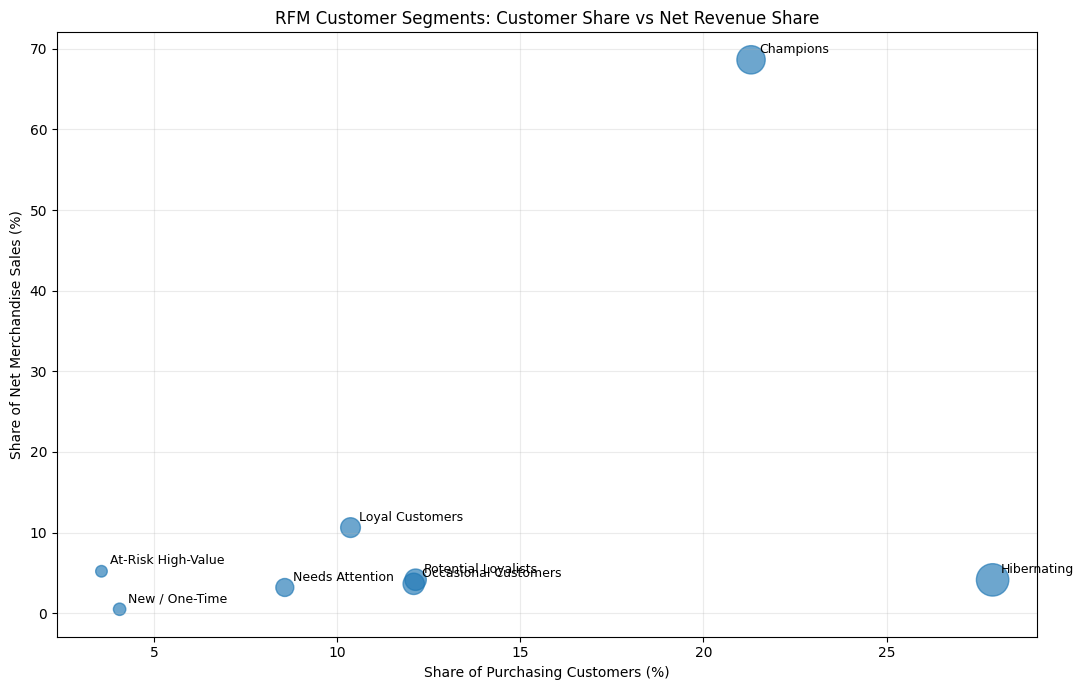

In [150]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    segment_summary_final["Customer_Share_%"],
    segment_summary_final["Net_Revenue_Share_%"],
    s=segment_summary_final["Customers"] / 3,
    alpha=0.65
)

for _, row in segment_summary_final.iterrows():
    ax.annotate(
        row["Customer_Segment"],
        (
            row["Customer_Share_%"],
            row["Net_Revenue_Share_%"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("Share of Purchasing Customers (%)")
ax.set_ylabel("Share of Net Merchandise Sales (%)")
ax.set_title("RFM Customer Segments: Customer Share vs Net Revenue Share")

ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

2. Create a portfolio-ready comparison chart

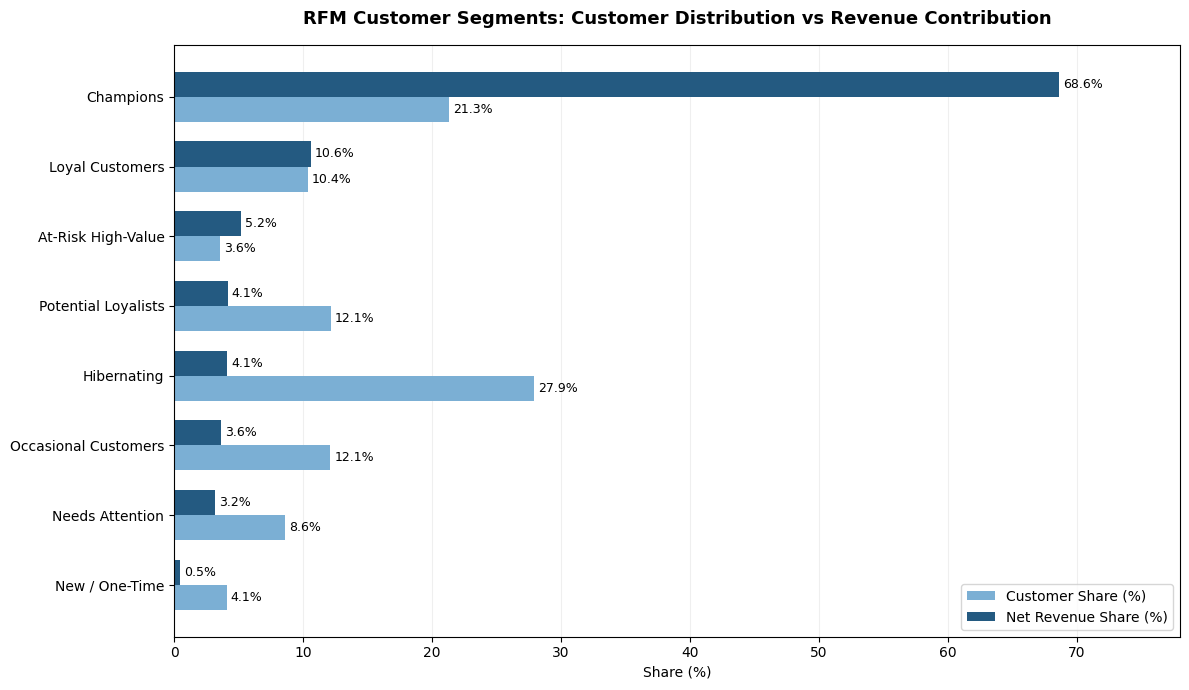

In [151]:
import matplotlib.pyplot as plt
import numpy as np

# Sort segments by net revenue contribution
plot_data = segment_summary_final.sort_values(
    "Net_Revenue_Share_%",
    ascending=True
)

y = np.arange(len(plot_data))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(12, 7))

bars_customers = ax.barh(
    y - bar_height / 2,
    plot_data["Customer_Share_%"],
    height=bar_height,
    label="Customer Share (%)",
    color="#7BAFD4"
)

bars_revenue = ax.barh(
    y + bar_height / 2,
    plot_data["Net_Revenue_Share_%"],
    height=bar_height,
    label="Net Revenue Share (%)",
    color="#245A81"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_data["Customer_Segment"])

ax.set_xlabel("Share (%)")
ax.set_title(
    "RFM Customer Segments: Customer Distribution vs Revenue Contribution",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.bar_label(
    bars_customers,
    fmt="%.1f%%",
    padding=3,
    fontsize=9
)

ax.bar_label(
    bars_revenue,
    fmt="%.1f%%",
    padding=3,
    fontsize=9
)

ax.set_xlim(0, 78)
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "rfm_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Next step — Visualize average customer behaviour by segment

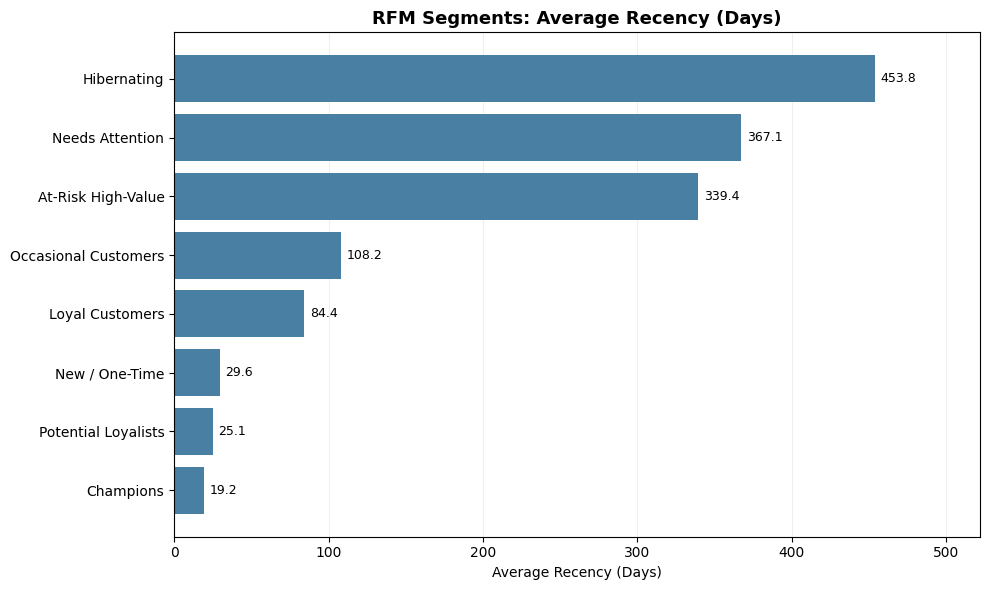

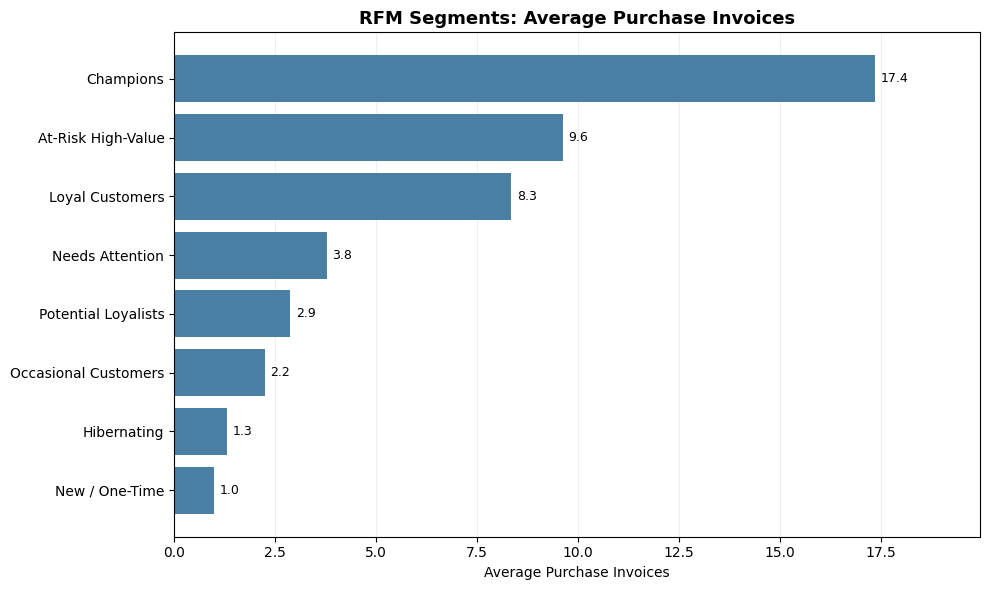

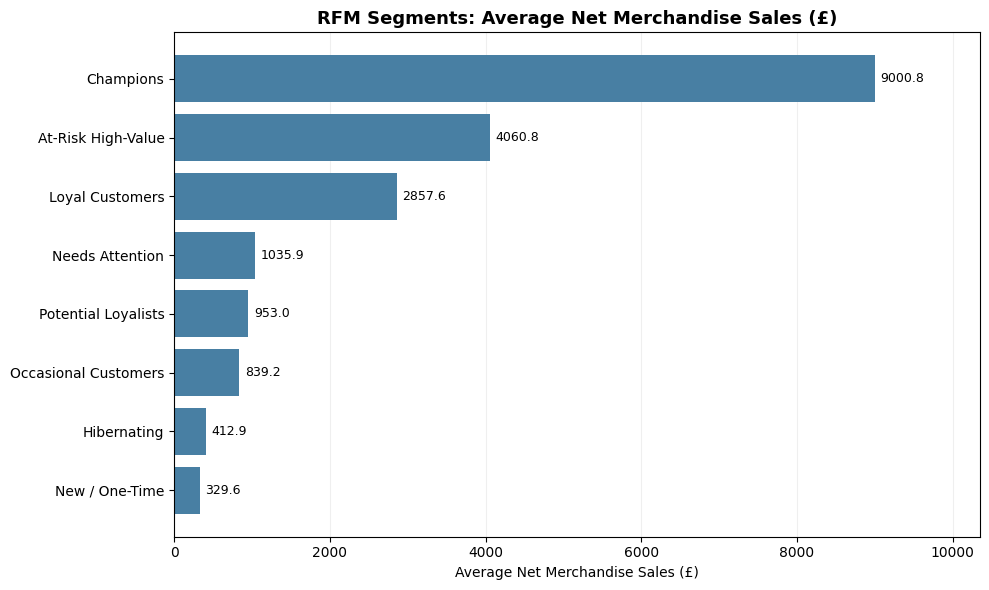

In [152]:
import matplotlib.pyplot as plt

metrics = [
    ("Avg_Recency", "Average Recency (Days)"),
    ("Avg_Frequency", "Average Purchase Invoices"),
    ("Avg_Net_Sales", "Average Net Merchandise Sales (£)")
]

for column, title in metrics:

    plot_data = segment_summary_final.sort_values(
        column,
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(
        plot_data["Customer_Segment"],
        plot_data[column],
        color="#487FA3"
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=4,
        fontsize=9
    )

    ax.set_xlim(0, plot_data[column].max() * 1.15)
    ax.set_xlabel(title)
    ax.set_title(
        f"RFM Segments: {title}",
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    plt.tight_layout()

    plt.savefig(
        f"rfm_{column.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

3. Next step — Validate and export the final customer segments

In [153]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

rfm_export = rfm_scored[
    [
        "Customer_ID",
        "Last_Purchase",
        "Recency_Days",
        "Frequency",
        "Monetary_Gross",
        "Monetary_Net",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Score",
        "Customer_Segment"
    ]
].copy()

# Check customer-level uniqueness
assert rfm_export["Customer_ID"].is_unique

# Check that all customers have segment assignments
assert rfm_export["Customer_Segment"].notna().all()
assert not rfm_export["Customer_Segment"].eq("Other Customers").any()

rfm_export.to_csv(
    output_dir / "customer_rfm_segments.csv",
    index=False
)

print("Exported customers:", len(rfm_export))
print("Segments:", rfm_export["Customer_Segment"].nunique())
print("File:", output_dir / "customer_rfm_segments.csv")

Exported customers: 5855
Segments: 8
File: data\processed\customer_rfm_segments.csv


Next step: Customer cohort and retention analysis

In [154]:
# Refine the previously unclassified customers

rfm_scored["Customer_Segment"] = np.select(
    [
        rfm_scored["Customer_Segment"].eq("Other Customers")
        & (rfm_scored["R_Score"] <= 2),

        rfm_scored["Customer_Segment"].eq("Other Customers")
        & (rfm_scored["R_Score"] == 3)
    ],
    [
        "Needs Attention",
        "Occasional Customers"
    ],
    default=rfm_scored["Customer_Segment"]
)

# Recalculate segment summary
segment_summary_final = (
    rfm_scored
    .groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Net_Sales=("Monetary_Net", "sum"),
        Avg_Recency=("Recency_Days", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Net_Sales=("Monetary_Net", "mean")
    )
    .reset_index()
)

segment_summary_final["Customer_Share_%"] = (
    segment_summary_final["Customers"]
    / len(rfm_scored) * 100
)

segment_summary_final["Net_Revenue_Share_%"] = (
    segment_summary_final["Net_Sales"]
    / rfm_scored["Monetary_Net"].sum() * 100
)

segment_summary_final = (
    segment_summary_final
    .sort_values("Net_Sales", ascending=False)
)

display(segment_summary_final.round(2))

# Final validation
print(
    "Total customers:",
    segment_summary_final["Customers"].sum()
)

print(
    "Total net sales:",
    round(segment_summary_final["Net_Sales"].sum(), 2)
)

print(
    "Unclassified customers:",
    (rfm_scored["Customer_Segment"] == "Other Customers").sum()
)

,Customer_Segment,Customers,Net_Sales,Avg_Recency,Avg_Frequency,Avg_Net_Sales,Customer_Share_%,Net_Revenue_Share_%
1,Champions,1247,11223942.58,19.24,17.35,9000.76,21.30,68.64
3,Loyal Customers,607,1734580.32,84.40,8.34,2857.63,10.37,10.61
0,At-Risk High-Value,209,848710.61,339.39,9.62,4060.82,3.57,5.19
7,Potential Loyalists,711,677618.28,25.07,2.88,953.05,12.14,4.14
2,Hibernating,1633,674325.68,453.76,1.30,412.94,27.89,4.12
6,Occasional Customers,708,594152.04,108.19,2.24,839.20,12.09,3.63
4,Needs Attention,502,520041.62,367.10,3.78,1035.94,8.57,3.18
5,New / One-Time,238,78443.82,29.61,1.00,329.60,4.06,0.48


Total customers: 5855
Total net sales: 16351814.96
Unclassified customers: 0


Next: Customer cohort and retention analysis

In [155]:
# Create customer cohort dataset
cohort_df = customer_sales[
    ["Customer_ID", "Invoice", "InvoiceDate"]
].copy()

# Identify purchase month
cohort_df["Purchase_Month"] = (
    cohort_df["InvoiceDate"].dt.to_period("M")
)

# Identify each customer's first observed purchase month
cohort_df["Cohort_Month"] = (
    cohort_df.groupby("Customer_ID")["Purchase_Month"]
    .transform("min")
)

# Calculate months since first observed purchase
cohort_df["Cohort_Index"] = (
    (cohort_df["Purchase_Month"].dt.year -
     cohort_df["Cohort_Month"].dt.year) * 12
    +
    (cohort_df["Purchase_Month"].dt.month -
     cohort_df["Cohort_Month"].dt.month)
)

print("Customers:", cohort_df["Customer_ID"].nunique())
print("Cohorts:", cohort_df["Cohort_Month"].nunique())
print(
    "Cohort index range:",
    cohort_df["Cohort_Index"].min(),
    "to",
    cohort_df["Cohort_Index"].max()
)

display(cohort_df.head(10))

Customers: 5855
Cohorts: 25
Cohort index range: 0 to 24


,Customer_ID,Invoice,InvoiceDate,Purchase_Month,Cohort_Month,Cohort_Index
0,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
1,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
2,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
3,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
4,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
5,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
6,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
7,13085,489434,2009-12-01 07:45:00,2009-12,2009-12,0
8,13085,489435,2009-12-01 07:46:00,2009-12,2009-12,0
9,13085,489435,2009-12-01 07:46:00,2009-12,2009-12,0


2. Next step — Calculate the monthly retention matrix

In [156]:
# Count unique active customers by cohort and month index
cohort_counts = (
    cohort_df
    .groupby(["Cohort_Month", "Cohort_Index"])
    ["Customer_ID"]
    .nunique()
    .unstack()
    .sort_index()
)

# Original cohort sizes (month 0)
cohort_sizes = cohort_counts[0]

# Calculate monthly retention percentages
retention_matrix = (
    cohort_counts
    .div(cohort_sizes, axis=0)
    * 100
)

print("Cohort count matrix shape:", cohort_counts.shape)

print("\nFirst 10 cohort sizes:")
display(cohort_sizes.head(10))

print("\nRetention matrix (first 10 cohorts, months 0–6):")
display(
    retention_matrix.iloc[:10, :7].round(2)
)

Cohort count matrix shape: (25, 25)

First 10 cohort sizes:


Cohort_Month
2009-12    952.0
2010-01    368.0
2010-02    377.0
2010-03    440.0
2010-04    294.0
2010-05    255.0
2010-06    267.0
2010-07    185.0
2010-08    163.0
2010-09    239.0
Freq: M, Name: 0, dtype: float64


Retention matrix (first 10 cohorts, months 0–6):


Cohort_Index,0,1,2,3,4,5,6
Cohort_Month,,,,,,,
2009-12,100.0,35.08,33.30,42.54,37.82,35.92,37.71
2010-01,100.0,21.47,32.07,31.52,27.17,31.25,26.90
2010-02,100.0,23.34,22.55,29.18,24.40,19.63,19.10
2010-03,100.0,19.09,23.18,24.09,23.18,20.45,24.77
2010-04,100.0,19.05,19.05,15.99,18.37,22.11,27.55
2010-05,100.0,15.69,16.86,17.65,17.65,25.49,21.18
2010-06,100.0,17.60,18.73,20.60,23.22,28.46,12.73
2010-07,100.0,15.68,18.38,29.73,29.19,14.05,11.35
2010-08,100.0,19.63,28.83,32.52,16.56,11.66,9.82


2. Next step — Calculate comparable retention benchmarks

In [157]:
# Calculate customer-weighted retention at selected cohort ages
# Exclude incomplete December 2011 outcome observations

last_complete_month = pd.Period("2011-11", freq="M")

retention_benchmarks = []

for month_index in [1, 3, 6, 12]:

    # Only include cohorts with a fully observed outcome month
    eligible_cohorts = [
        cohort
        for cohort in cohort_counts.index
        if cohort + month_index <= last_complete_month
    ]

    eligible_counts = cohort_counts.loc[
        eligible_cohorts, month_index
    ].fillna(0)

    eligible_sizes = cohort_sizes.loc[eligible_cohorts]

    retained_customers = eligible_counts.sum()
    total_customers = eligible_sizes.sum()

    retention_benchmarks.append({
        "Month_Index": month_index,
        "Eligible_Cohorts": len(eligible_cohorts),
        "Cohort_Customers": int(total_customers),
        "Returning_Customers": int(retained_customers),
        "Weighted_Retention_%": (
            retained_customers / total_customers * 100
        )
    })

retention_benchmark_df = pd.DataFrame(retention_benchmarks)

display(retention_benchmark_df.round(2))

,Month_Index,Eligible_Cohorts,Cohort_Customers,Returning_Customers,Weighted_Retention_%
0,1,23,5635,1316,23.35
1,3,21,5226,1305,24.97
2,6,18,4910,1089,22.18
3,12,12,4241,964,22.73


2. Next step — Create a cohort retention heatmap

In [158]:
# Prepare retention matrix for visualization
last_complete_month = pd.Period("2011-11", freq="M")

retention_complete = retention_matrix.copy()

for cohort_month in retention_complete.index:
    for month_index in retention_complete.columns:

        outcome_month = cohort_month + int(month_index)

        if outcome_month > last_complete_month:
            retention_complete.loc[
                cohort_month, month_index
            ] = np.nan

        elif pd.isna(
            retention_complete.loc[cohort_month, month_index]
        ):
            retention_complete.loc[
                cohort_month, month_index
            ] = 0

# Exclude the December 2011 acquisition cohort
retention_complete = retention_complete.loc[
    retention_complete.index <= last_complete_month
]

print("Heatmap matrix shape:", retention_complete.shape)

display(
    retention_complete.iloc[:10, :13].round(1)
)

Heatmap matrix shape: (24, 25)


Cohort_Index,0,1,2,3,4,5,6,7,8,9,10,11,12
Cohort_Month,,,,,,,,,,,,,
2009-12,100.0,35.1,33.3,42.5,37.8,35.9,37.7,34.3,33.7,36.1,42.1,49.6,37.6
2010-01,100.0,21.5,32.1,31.5,27.2,31.2,26.9,23.4,28.5,32.6,31.0,17.9,22.8
2010-02,100.0,23.3,22.5,29.2,24.4,19.6,19.1,28.6,25.5,27.6,11.4,12.5,15.1
2010-03,100.0,19.1,23.2,24.1,23.2,20.5,24.8,30.7,27.7,10.9,11.4,14.5,20.0
2010-04,100.0,19.0,19.0,16.0,18.4,22.1,27.6,26.5,10.5,10.9,7.5,13.9,14.3
2010-05,100.0,15.7,16.9,17.6,17.6,25.5,21.2,12.5,5.9,8.2,11.4,13.3,15.3
2010-06,100.0,17.6,18.7,20.6,23.2,28.5,12.7,9.0,8.2,11.2,10.5,13.9,15.0
2010-07,100.0,15.7,18.4,29.7,29.2,14.1,11.4,14.6,14.6,11.4,13.5,14.6,13.0
2010-08,100.0,19.6,28.8,32.5,16.6,11.7,9.8,12.9,13.5,12.9,12.9,11.7,14.7


2. Next step — Create the cohort retention heatmap

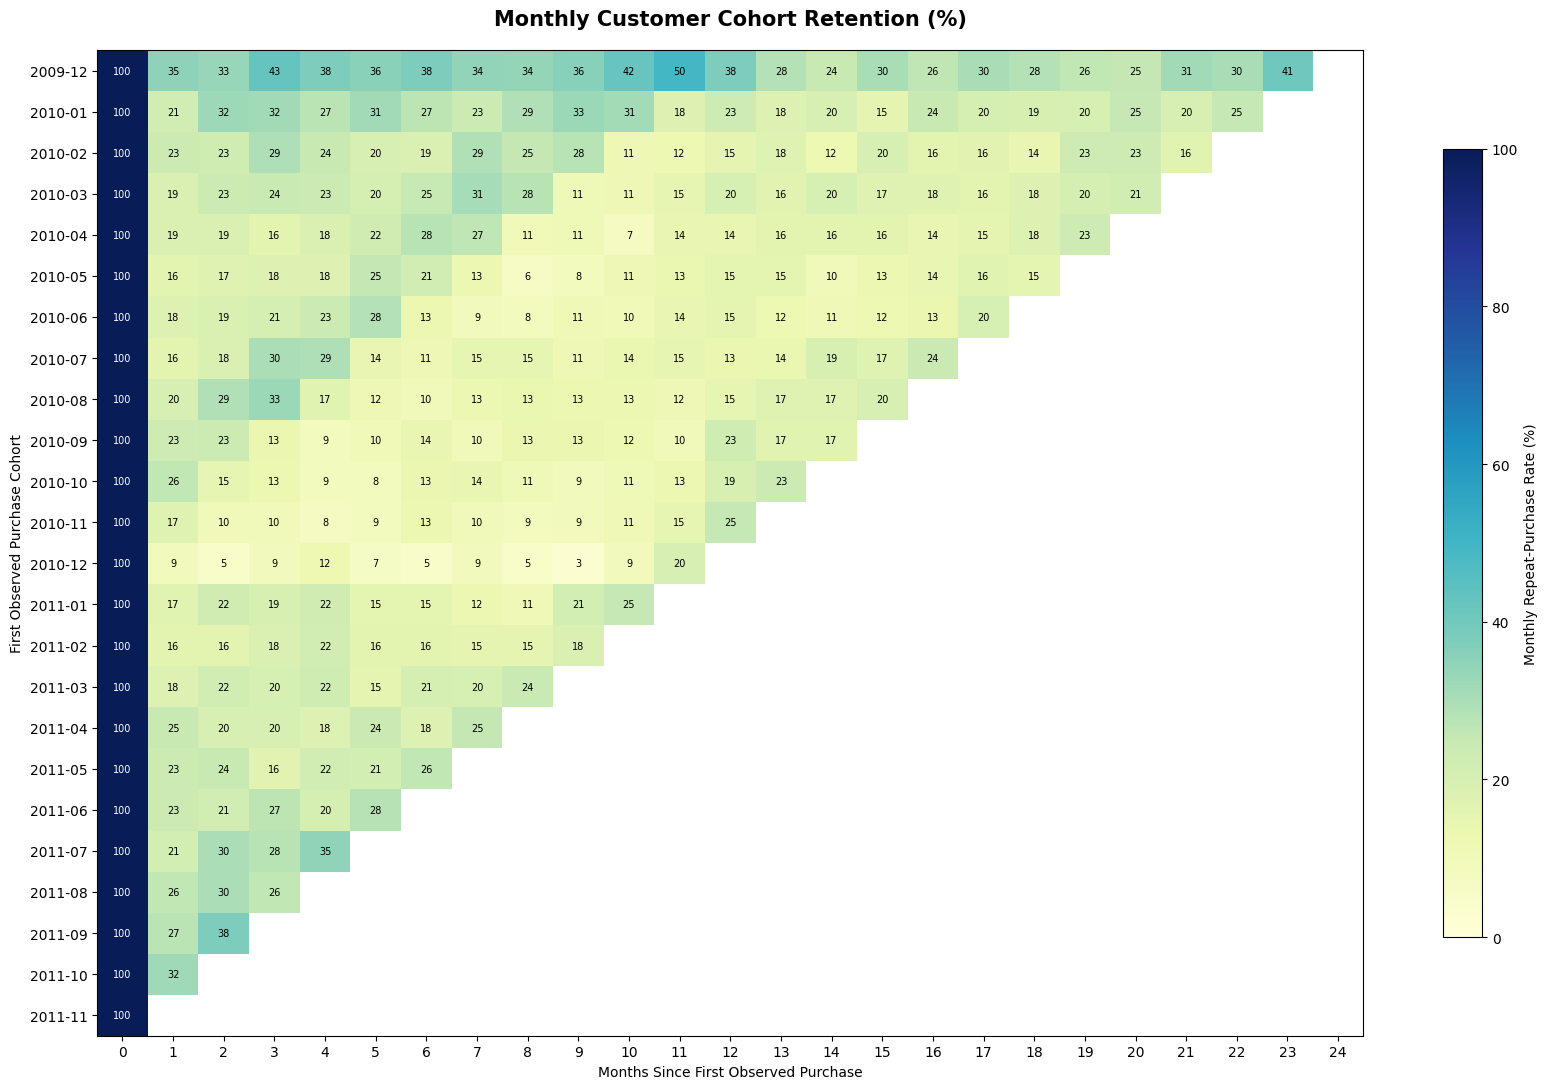

In [159]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare heatmap values
heatmap_data = retention_complete.copy()

# Display cohort months as strings
cohort_labels = heatmap_data.index.astype(str)

fig, ax = plt.subplots(figsize=(17, 11))

# Mask unavailable months
masked_data = np.ma.masked_invalid(
    heatmap_data.to_numpy(dtype=float)
)

im = ax.imshow(
    masked_data,
    cmap="YlGnBu",
    aspect="auto",
    vmin=0,
    vmax=100
)

# Axis labels
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(np.arange(len(cohort_labels)))
ax.set_yticklabels(cohort_labels)

ax.set_xlabel("Months Since First Observed Purchase")
ax.set_ylabel("First Observed Purchase Cohort")

ax.set_title(
    "Monthly Customer Cohort Retention (%)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Annotate available cells
for i in range(masked_data.shape[0]):
    for j in range(masked_data.shape[1]):

        value = masked_data[i, j]

        if not np.ma.is_masked(value):
            ax.text(
                j,
                i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if value >= 50 else "black"
            )

# Color scale
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Monthly Repeat-Purchase Rate (%)")

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "cohort_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Next step — Create a clearer retention heatmap

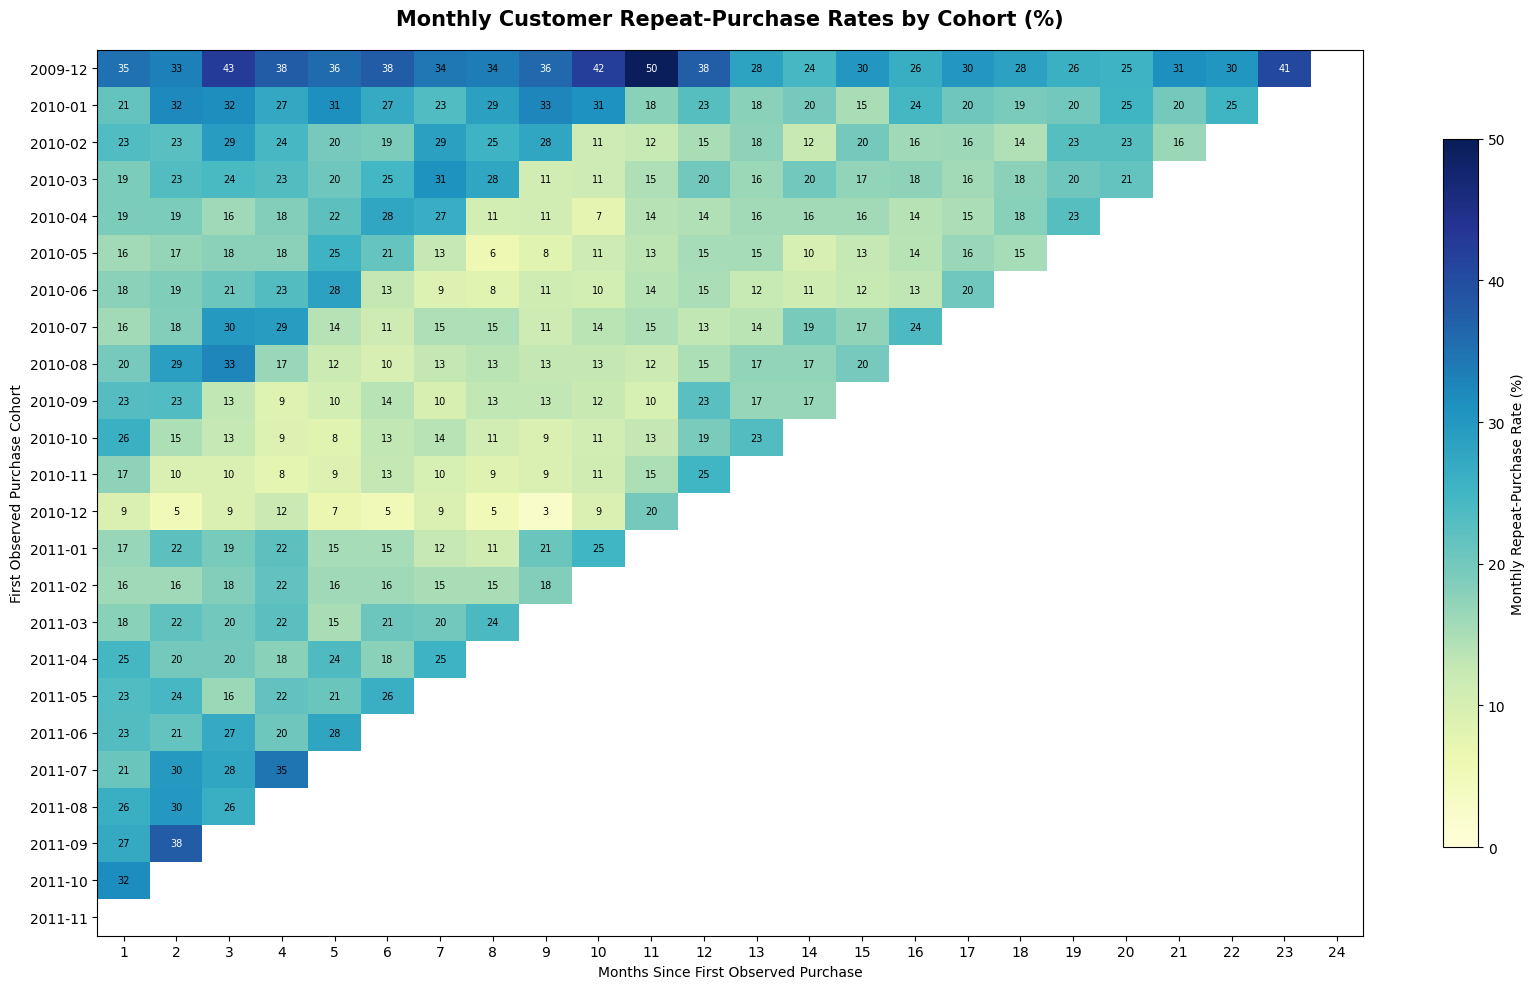

In [160]:
import matplotlib.pyplot as plt
import numpy as np

# Exclude month 0 from the visualization only
heatmap_data = retention_complete.iloc[:, 1:].copy()

masked_data = np.ma.masked_invalid(
    heatmap_data.to_numpy(dtype=float)
)

fig, ax = plt.subplots(figsize=(17, 10))

im = ax.imshow(
    masked_data,
    cmap="YlGnBu",
    aspect="auto",
    vmin=0,
    vmax=50
)

ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index.astype(str))

ax.set_xlabel("Months Since First Observed Purchase")
ax.set_ylabel("First Observed Purchase Cohort")

ax.set_title(
    "Monthly Customer Repeat-Purchase Rates by Cohort (%)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

# Annotate observed months
for i in range(masked_data.shape[0]):
    for j in range(masked_data.shape[1]):

        value = masked_data[i, j]

        if not np.ma.is_masked(value):
            ax.text(
                j, i,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if value >= 35 else "black"
            )

cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Monthly Repeat-Purchase Rate (%)")

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "cohort_retention_heatmap_final.png",
    dpi=300,
    bbox_inches="tight"
)

3. Next step — Verify the customer cohort analysis

In [161]:
# Final cohort analysis validation

print("Total customers across cohorts:", int(cohort_sizes.sum()))

print(
    "Unique purchasing customers:",
    customer_sales["Customer_ID"].nunique()
)

print(
    "Retention values within 0–100%:",
    retention_complete.stack().between(0, 100).all()
)

print(
    "All cohort month-0 rates equal 100%:",
    (retention_complete[0] == 100).all()
)

print(
    "Number of cohorts in final heatmap:",
    len(retention_complete)
)

Total customers across cohorts: 5855
Unique purchasing customers: 5855
Retention values within 0–100%: True
All cohort month-0 rates equal 100%: True
Number of cohorts in final heatmap: 24


2. Next step — Create a consolidated customer insights table

In [162]:
# Consolidated customer behaviour insights

customer_insights = pd.DataFrame([
    {
        "Analysis_Area": "Purchasing Behaviour",
        "Key_Finding": "Repeat customers generate 96.74% of identified gross sales",
        "Business_Implication": "Repeat purchasing is a major revenue driver",
        "Recommended_Action": "Investigate retention and repeat-purchase initiatives"
    },
    {
        "Analysis_Area": "Revenue Concentration",
        "Key_Finding": "Top 10% of customers generate 63.90% of gross sales",
        "Business_Implication": "Revenue is concentrated among high-spending customers",
        "Recommended_Action": "Monitor high-value customer purchasing patterns"
    },
    {
        "Analysis_Area": "Return Behaviour",
        "Key_Finding": "Top 15 returning customers account for 55.22% of identified return value",
        "Business_Implication": "A small group accounts for a substantial share of returns",
        "Recommended_Action": "Investigate exceptional cancellations and return patterns"
    },
    {
        "Analysis_Area": "RFM Segmentation",
        "Key_Finding": "Champions generate 68.64% of purchasing-customer net sales",
        "Business_Implication": "Recent, frequent, high-value customers dominate revenue",
        "Recommended_Action": "Prioritize understanding and maintaining these relationships"
    },
    {
        "Analysis_Area": "At-Risk Customers",
        "Key_Finding": "209 At-Risk High-Value customers contributed £848,710.61",
        "Business_Implication": "Historically valuable customers show older purchasing activity",
        "Recommended_Action": "Investigate targeted re-engagement opportunities"
    },
    {
        "Analysis_Area": "Cohort Retention",
        "Key_Finding": "Month-1 repeat-purchase rate is 23.35%",
        "Business_Implication": "Many customers do not purchase in the following month",
        "Recommended_Action": "Explore repeat-purchase initiatives and evaluate their outcomes"
    }
])

display(customer_insights)

,Analysis_Area,Key_Finding,Business_Implication,Recommended_Action
0,Purchasing Behaviour,Repeat customers generate 96.74% of identified...,Repeat purchasing is a major revenue driver,Investigate retention and repeat-purchase init...
1,Revenue Concentration,Top 10% of customers generate 63.90% of gross ...,Revenue is concentrated among high-spending cu...,Monitor high-value customer purchasing patterns
2,Return Behaviour,Top 15 returning customers account for 55.22% ...,A small group accounts for a substantial share...,Investigate exceptional cancellations and retu...
3,RFM Segmentation,Champions generate 68.64% of purchasing-custom...,"Recent, frequent, high-value customers dominat...",Prioritize understanding and maintaining these...
4,At-Risk Customers,209 At-Risk High-Value customers contributed £...,Historically valuable customers show older pur...,Investigate targeted re-engagement opportunities
5,Cohort Retention,Month-1 repeat-purchase rate is 23.35%,Many customers do not purchase in the followin...,Explore repeat-purchase initiatives and evalua...


Step 1 — Move the CSV and charts into the correct folders

In [163]:
from pathlib import Path
import shutil

# Notebook working directory
notebook_dir = Path.cwd()

# Repository root
project_root = notebook_dir.parent

# Destination folders
processed_dir = project_root / "data" / "processed"
images_dir = project_root / "images"

processed_dir.mkdir(parents=True, exist_ok=True)
images_dir.mkdir(parents=True, exist_ok=True)

# Move RFM CSV
csv_source = notebook_dir / "data" / "processed" / "customer_rfm_segments.csv"
csv_destination = processed_dir / "customer_rfm_segments.csv"

if csv_source.exists():
    shutil.move(str(csv_source), str(csv_destination))
    print("Moved CSV:", csv_destination)

# Move customer analysis charts
chart_files = [
    "rfm_segment_distribution.png",
    "rfm_avg_recency.png",
    "rfm_avg_frequency.png",
    "rfm_avg_net_sales.png",
    "cohort_retention_heatmap_final.png"
]

for filename in chart_files:
    source = notebook_dir / filename
    destination = images_dir / filename

    if source.exists():
        shutil.move(str(source), str(destination))
        print("Moved chart:", destination)

print("\nOrganization completed.")

Moved CSV: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\data\processed\customer_rfm_segments.csv
Moved chart: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\images\rfm_avg_recency.png
Moved chart: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\images\rfm_avg_frequency.png
Moved chart: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\images\rfm_avg_net_sales.png

Organization completed.


Next step — Make your notebook paths consistent

In [164]:
# Inspect leftover files before cleanup

old_data_dir = NOTEBOOK_DIR / "data"
old_heatmap = NOTEBOOK_DIR / "cohort_retention_heatmap.png"

print("Files in old notebook data folder:")

if old_data_dir.exists():
    for path in old_data_dir.rglob("*"):
        print(path.relative_to(NOTEBOOK_DIR))
else:
    print("Folder does not exist")

print("\nOld heatmap exists:", old_heatmap.exists())

print(
    "Final heatmap exists:",
    (IMAGES_DIR / "cohort_retention_heatmap_final.png").exists()
)

print(
    "RFM CSV exists:",
    (PROCESSED_DIR / "customer_rfm_segments.csv").exists()
)

Files in old notebook data folder:
data\processed

Old heatmap exists: False
Final heatmap exists: True
RFM CSV exists: True


In [165]:
from pathlib import Path

old_data_dir = NOTEBOOK_DIR / "data"
old_heatmap = NOTEBOOK_DIR / "cohort_retention_heatmap.png"

final_heatmap = IMAGES_DIR / "cohort_retention_heatmap_final.png"
final_csv = PROCESSED_DIR / "customer_rfm_segments.csv"

# Remove outdated heatmap only if final version exists
if final_heatmap.is_file() and old_heatmap.is_file():
    old_heatmap.unlink()
    print("Removed outdated heatmap")

# Remove empty old directories only if final CSV exists
if final_csv.is_file() and old_data_dir.exists():
    for folder in sorted(
        [p for p in old_data_dir.rglob("*") if p.is_dir()],
        key=lambda p: len(p.parts),
        reverse=True
    ):
        if not any(folder.iterdir()):
            folder.rmdir()
            print("Removed empty folder:", folder)

    if not any(old_data_dir.iterdir()):
        old_data_dir.rmdir()
        print("Removed old notebook data folder")

print("\nCleanup completed.")

Removed empty folder: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\notebooks\data\processed
Removed old notebook data folder

Cleanup completed.


In [166]:
import json

notebook_path = NOTEBOOK_DIR / "01_data_exploration.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "savefig(",
    "to_csv(",
    "to_excel(",
    "read_excel(",
    "read_csv(",
    "mkdir("
]

print("Notebook file-path operations:\n")

for index, cell in enumerate(notebook["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    for line in source.splitlines():
        if any(keyword in line for keyword in keywords):
            print(f"Cell {index}: {line.strip()}")

Notebook file-path operations:

Cell 3: PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
Cell 3: IMAGES_DIR.mkdir(parents=True, exist_ok=True)
Cell 7: df = pd.read_excel(
Cell 13: temp_df = pd.read_excel(
Cell 23: df_2009_2010 = pd.read_excel(
Cell 23: df_2010_2011 = pd.read_excel(
Cell 172: plt.savefig(
Cell 187: plt.savefig(
Cell 206: plt.savefig(
Cell 208: plt.savefig(
Cell 214: plt.savefig(
Cell 216: plt.savefig(
Cell 246: plt.savefig(
Cell 248: plt.savefig(
Cell 295: plt.savefig(
Cell 297: plt.savefig(
Cell 299: output_dir.mkdir(parents=True, exist_ok=True)
Cell 299: rfm_export.to_csv(
Cell 311: plt.savefig(
Cell 313: plt.savefig(
Cell 319: processed_dir.mkdir(parents=True, exist_ok=True)
Cell 319: images_dir.mkdir(parents=True, exist_ok=True)
Cell 323: "savefig(",
Cell 323: "to_csv(",
Cell 323: "to_excel(",
Cell 323: "read_excel(",
Cell 323: "read_csv(",
Cell 323: "mkdir("
Cell 326: output_dir.mkdir(parents=True, exist_ok=True)
Cell 327: output_dir.mkdir(parents=True, exist_ok=Tr

In [167]:
import json

notebook_path = NOTEBOOK_DIR / "01_data_exploration.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("Notebook:", notebook_path.name)
print("Total cells:", len(notebook["cells"]))

keywords = [
    "savefig",
    "to_csv",
    "to_excel",
    "read_excel",
    "read_csv",
    "mkdir",
    "open(",
    "Path("
]

matches = 0

for index, cell in enumerate(notebook["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    for line in source.splitlines():
        if any(keyword in line for keyword in keywords):
            print(f"Cell {index}: {line.strip()}")
            matches += 1

print("\nTotal matching lines:", matches)

Notebook: 01_data_exploration.ipynb
Total cells: 335
Cell 3: PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
Cell 3: IMAGES_DIR.mkdir(parents=True, exist_ok=True)
Cell 7: df = pd.read_excel(
Cell 13: temp_df = pd.read_excel(
Cell 23: df_2009_2010 = pd.read_excel(
Cell 23: df_2010_2011 = pd.read_excel(
Cell 172: plt.savefig(
Cell 187: plt.savefig(
Cell 206: plt.savefig(
Cell 208: plt.savefig(
Cell 214: plt.savefig(
Cell 216: plt.savefig(
Cell 246: plt.savefig(
Cell 248: plt.savefig(
Cell 295: plt.savefig(
Cell 297: plt.savefig(
Cell 299: output_dir = Path("data/processed")
Cell 299: output_dir.mkdir(parents=True, exist_ok=True)
Cell 299: rfm_export.to_csv(
Cell 311: plt.savefig(
Cell 313: plt.savefig(
Cell 319: processed_dir.mkdir(parents=True, exist_ok=True)
Cell 319: images_dir.mkdir(parents=True, exist_ok=True)
Cell 323: with open(notebook_path, "r", encoding="utf-8") as f:
Cell 323: "savefig(",
Cell 323: "to_csv(",
Cell 323: "to_excel(",
Cell 323: "read_excel(",
Cell 323: "read_csv

In [168]:
# Inspect specific notebook cells
cells_to_inspect = [298, 310, 312]

for cell_number in cells_to_inspect:
    cell = notebook["cells"][cell_number - 1]

    print(f"\n{'=' * 15} CELL {cell_number} {'=' * 15}")
    print("".join(cell["source"]))


=============== CELL 298 ===============
3. Next step — Validate and export the final customer segments

=============== CELL 310 ===============
2. Next step — Create the cohort retention heatmap

=============== CELL 312 ===============
Next step — Create a clearer retention heatmap


In [169]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

In [170]:
# Use the project-level processed data directory
output_dir = PROCESSED_DIR
output_dir.mkdir(parents=True, exist_ok=True)

In [171]:
for cell_number in [310, 312]:
    source = "".join(notebook["cells"][cell_number - 1]["source"])

    print(f"\nCell {cell_number}:")
    for line in source.splitlines():
        if "savefig" in line or ".png" in line:
            print(line.strip())


Cell 310:

Cell 312:


In [172]:
for index, cell in enumerate(notebook["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "savefig(" in source:
        lines = source.splitlines()

        for i, line in enumerate(lines):
            if "savefig(" in line:
                print(f"\nCell {index}:")
                print("\n".join(lines[i:i+5]))


Cell 172:
plt.savefig(
    "../images/top10_products_net_sales.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 187:
plt.savefig(
    "../images/christmas_product_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 206:
plt.savefig(
    "../images/top_10_growing_products.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 208:
plt.savefig(
    "../images/top_10_declining_products.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 214:
plt.savefig(
    "../images/top_10_consistent_products.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 216:
plt.savefig(
    "../images/monthly_product_revenue_stability.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 246:
plt.savefig(
    "../images/top_15_priority_products.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 248:
plt.savefig(
    "../images/priority_product_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

Cell 295:
plt.savefig(
    IMAGES_DIR / "rfm_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


In [173]:
import re

for index, cell in enumerate(notebook["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    matches = re.findall(
        r'plt\.savefig\(\s*["\']([^"\']+)',
        source
    )

    for filename in matches:
        status = (
            "CORRECT"
            if filename.startswith("../images/")
            else "CHECK"
        )

        print(f"Cell {index}: {filename} [{status}]")

Cell 172: ../images/top10_products_net_sales.png [CORRECT]
Cell 187: ../images/christmas_product_seasonality.png [CORRECT]
Cell 206: ../images/top_10_growing_products.png [CORRECT]
Cell 208: ../images/top_10_declining_products.png [CORRECT]
Cell 214: ../images/top_10_consistent_products.png [CORRECT]
Cell 216: ../images/monthly_product_revenue_stability.png [CORRECT]
Cell 246: ../images/top_15_priority_products.png [CORRECT]
Cell 248: ../images/priority_product_scatter.png [CORRECT]


In [174]:
from pathlib import Path

print("Images directory:", IMAGES_DIR)
print("\nSaved charts:")

for file in sorted(IMAGES_DIR.glob("*.png")):
    print("✓", file.name)

print("\nTotal charts:", len(list(IMAGES_DIR.glob("*.png"))))

Images directory: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\images

Saved charts:
✓ christmas_product_seasonality.png
✓ cohort_retention_heatmap.png
✓ cohort_retention_heatmap_final.png
✓ monthly_product_revenue_stability.png
✓ priority_product_scatter.png
✓ rfm_avg_frequency.png
✓ rfm_avg_net_sales.png
✓ rfm_avg_recency.png
✓ rfm_segment_distribution.png
✓ top10_products_net_sales.png
✓ top_10_consistent_products.png
✓ top_10_declining_products.png
✓ top_10_growing_products.png
✓ top_15_priority_products.png

Total charts: 14


In [175]:
for cell_number in [6, 12, 22]:
    cell = notebook["cells"][cell_number - 1]

    print(f"\n{'=' * 10} CELL {cell_number} {'=' * 10}")
    print("".join(cell["source"]))


========== CELL 6 ==========
Load the data

========== CELL 12 ==========
## 2. Dataset Structure and Time Period

The dataset contains two Excel worksheets.
I will inspect both sheets to understand their
time coverage and transaction structure before
combining them for further analysis.

========== CELL 22 ==========
## 3. Combining Both Worksheets

The dataset contains two worksheets representing
different reporting periods.

I will combine both worksheets into one DataFrame
to perform analysis across the complete dataset.


In [176]:
print("Excel file path:", file_path)
print("File exists:", Path(file_path).exists())
print("Available worksheets:", excel_file.sheet_names)

Excel file path: ../data/online_retail_II.xlsx
File exists: True
Available worksheets: ['Year 2009-2010', 'Year 2010-2011']


In [177]:
rfm_path = PROCESSED_DIR / "customer_rfm_segments.csv"

print("CSV path:", rfm_path)
print("File exists:", rfm_path.exists())

if rfm_path.exists():
    rfm_check = pd.read_csv(rfm_path)

    print("Dataset shape:", rfm_check.shape)
    print("Unique customers:", rfm_check["Customer_ID"].nunique())
    print("Duplicate customer IDs:", rfm_check["Customer_ID"].duplicated().sum())
    print("Columns:", rfm_check.columns.tolist())

CSV path: c:\Users\HP\Desktop\ecommerce-business-performance-analysis\data\processed\customer_rfm_segments.csv
File exists: True
Dataset shape: (5855, 11)
Unique customers: 5855
Duplicate customer IDs: 0
Columns: ['Customer_ID', 'Last_Purchase', 'Recency_Days', 'Frequency', 'Monetary_Gross', 'Monetary_Net', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Customer_Segment']


In [178]:
for index, cell in enumerate(notebook["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(name in source for name in [
        "PROJECT_ROOT =",
        "PROCESSED_DIR =",
        "IMAGES_DIR =",
        "file_path ="
    ]):
        print(f"\nCell {index}:")
        for line in source.splitlines():
            if any(name in line for name in [
                "PROJECT_ROOT =",
                "PROCESSED_DIR =",
                "IMAGES_DIR =",
                "file_path ="
            ]):
                print(line.strip())


Cell 3:
PROJECT_ROOT = NOTEBOOK_DIR.parent
PROCESSED_DIR = DATA_DIR / "processed"
IMAGES_DIR = PROJECT_ROOT / "images"

Cell 5:
file_path = "../data/online_retail_II.xlsx"

Cell 335:
"PROJECT_ROOT =",
"PROCESSED_DIR =",
"IMAGES_DIR =",
"file_path ="
"PROJECT_ROOT =",
"PROCESSED_DIR =",
"IMAGES_DIR =",
"file_path ="
